# 2-motor: identification

Find out whether the board alone can recover each motor constant a back-EMF speed estimate needs, and how close each board-only route lands to stage 2's bench references, at what cost in time and in motor revolutions.

## Purpose

A back-EMF speed estimate reads the motor's speed off its own terminals. The board knows the duty it applied, the terminal volts and the current, and the motor's equation turns them into a speed,

$$\omega = \frac{V - R\,i - V_b(\omega)}{K_e}$$

with $V$ the mean terminal voltage over the PWM period, $i$ the motor's mean current, $R$ the terminal resistance, $K_e$ the back-EMF constant and $V_b$ what the turning motor's terminals carry beyond the EMF and the copper's drop, which motor-model found on the turning motor and called the brush drop. Here it is read in two parts, one that follows the rate at which the motor's current drops out, the board's own count of the PWM periods whose crest sample sits near zero, and a table of the speed per direction of rotation. While the current moves, the inductance $L$ adds $L\,di/dt$. The board does not read the mean current directly. It reads the current once per period, the crest sample, and motor-model found that sample sits above the period's mean by a reading term $\Delta$, about 20 to 30 mA on the spinning motor, which falls to zero at 100 % duty where nothing switches. So $i$ is the crest less $\Delta$.

The estimate therefore needs $R$, its temperature, $K_e$, $L$, $\Delta$ and $V_b$. The route that reads $\Delta$ without a meter, the 100 % anchor below, also reads $c = J/(K_t K_e)$, the rotor's inertia $J$ over the torque constant $K_t$ and $K_e$, so $c$ is on the list too.

Stage 2 measured every one of them with help a servo does not have. It moved a wrench bar through twelve holes, put a DMM in series, ran spins of 1.5 s and run-ups of 300 ms at 100 %, and repeated everything three times. A servo in use has its own board, its own rail, one end stop to hold against, and about 157 motor revolutions between its end stops, the horn's 184 deg times the gear train's 308.05. So this notebook reads stage 2's data the way a servo's board could, one constant at a time, and grades each route against the bench reference. For each route it gives the value, the reference, the error, the spread between repeats, and the cost in maneuvers, seconds and motor revolutions.

It scores no speed. The compensation notebook reads this notebook's results and runs the constants through the estimator.

## Procedure

This notebook has no capture of its own. It reads stage 2's captures as if a servo had recorded them.

- One hole of rest-resistance's stall pass stands for the seat at an end stop, for $R$ and $L$.
- One repeat of bemf-coast's capture-1, twenty spins and their coasts, stands for an ident run of short spins, for $K_e$, $\Delta$ and $V_b$.
- One speed-torque run-up each way stands for the anchor's run-up, for $c$.

Every spin in these data ran 1.5 s. A short spin is emulated by reading only the last 50 ms before the cut and the first 15 ms of the coast, and it is costed as if the drive had started some 65 ms before the window and the bridge braked 15 ms after the cut. Whether a spin that has run only about 115 ms reads the same as one that ran 1.5 s is not tested here.

## Data

Every folder is under `telemetry/mg90-b__dev-v006-2A-D/`.

- `rest-resistance/capture-1/stall/`, the locked rotor at twelve holes of the bar, 100 % laps of 300 ms at 3.3, 3.7 and 4.2 V both ways.
- `inductance/capture-1/`, the locked bursts at the same twelve holes, five groups each on a 5 V rail. The other inductance sittings, `reversal-1`, `steps-1` and `fast-1`, enter only through their start times.
- `bemf-coast/capture-1/`, ten rungs, 15 to 60 % at 5.0 and 7.4 V, three repeats both ways, each a 1.5 s spin and a coast with the bridge open.
- `bemf-coast/meter-1/` and `high-1/`, the same cycles with the DMM in series, the day after, for grading the anchor.
- `bemf-coast/swapped-1/`, 7.4 V 40 and 60 % with the leads as wired and then swapped, for the temperature and the self-heat bound.
- `speed-torque/capture-1/`, three 300 ms run-ups at 100 % on 5.0 V each way and their coasts.

### The results carried in

From stage 1, current-scale, terminal-chain, sample-timing and bridge-states through motor-model's modules, and ntc-curve's grade of the NTC's nominal beta. From stage 2, rest-resistance's R by hole, its median, the meter's ohms and its thermal numbers, inductance's $L$ by hole by both estimators and its burst R by hole, bemf-coast's $K_e$ and its speed trend, speed-torque's $J$ and its turn-window tach, the teardown's cooling of the winding and its rotor mass, and motor-model's published no-meter reading-term grid, its slow-decay R at hole 11 by capture and its running R under 160 rev/s. rest-resistance's lap reduction and inductance's burst fits are not modules, so their own cells run unchanged in their own folders, and this notebook asserts that each reproduces its results file. The only numbers typed in are physical constants, copper's coefficient of 0.39 % per C and the specific heats of copper and iron, and the servo's geometry, the horn's travel of 184 deg and the gear ratio of 308.05. The ratio is the tooth count of another MG90's metal train, counted at its teardown, and it enters only the travel budget.

## Method

### One ident pass

A pass is what a servo could read in one sitting. $R$ and $L$ come from one seat, $K_e$ from one repeat's 20 coasts, $c$ from one run-up each way, $\Delta$ from that $c$ with the same repeat's 20 spins, and $V_b$, its dropout coefficient and its speed table, from six of those spins, 7.4 V at 30, 40 and 60 % both ways. With twelve seats and three repeats there are 36 passes, and each constant's spread over them is the route's own repeatability.

### Grading

Each route is graded against stage 2's bench reference for the same constant, and each grade says whether it is in-sample or held out. One seat's $R$ and $L$ is one of the twelve holes the reference averages. One repeat's $K_e$ is part of the 60 coasts of the reference, so it is also graded against the other two repeats alone. $c$ and the coast's drag come from the first day, and the anchor is graded against the DMM on the second. The $V_b$ subsets are graded against the full-data fit, which contains them.

### Cost

The cost of a spin is its motor revolutions, read from the board's own signals. A rough speed every row, $\hat\omega = (D\,V_\mathrm{on} - R\,i)/K_e$ with $D$ the applied duty and $V_\mathrm{on}$ the terminal volts in the window, boxcar-filtered over 5 ms and integrated, gives the revolutions. The coast's EMF over $K_e$ gives the revolutions after the cut. The anchor's run-up is read off speed-torque's own turn-window tach instead. A short spin is the spin-up to 95 % of its final speed, the window, and 15 ms of coast, then a brake. The brake's own distance is not in the data.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import figures, parallel, results
from oscnb.display import show
import identification as idn        # the routes and their shared pieces
import second_motor_ident as smi    # identification.py again, on mg90-c

mm, bd = idn.mm, idn.bd             # motor-model's modules, through idn
MECH_COLOR = {1: figures.BLUE, -1: figures.ORANGE}   # fixed per direction
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)   # whole folder names
STALL = idn.PAIR / "rest-resistance" / "capture-1" / "stall"
BURSTS = idn.PAIR / "inductance" / "capture-1"
FOLDERS = {**bd.RUNS, "swapped-1": idn.SWAP, "stall pass": STALL,
           "bursts": BURSTS}
print(idn.MOTOR.key, "on", idn.BOARD.key)
show(pd.DataFrame({"run": list(FOLDERS),
                   "folder": [str(results.rel(p)) for p in FOLDERS.values()]}),
     n=None)

mg90-b on dev-v006-2A-D


,run,folder
0,capture-1,telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1
1,meter-1,telemetry/mg90-b__dev-v006-2A-D/bemf-coast/meter-1
2,high-1,telemetry/mg90-b__dev-v006-2A-D/bemf-coast/high-1
3,speed-torque,telemetry/mg90-b__dev-v006-2A-D/speed-torque/capture-1
4,swapped-1,telemetry/mg90-b__dev-v006-2A-D/bemf-coast/swapped-1
5,stall pass,telemetry/mg90-b__dev-v006-2A-D/rest-resistance/capture-1/stall
6,bursts,telemetry/mg90-b__dev-v006-2A-D/inductance/capture-1


The method's constants, each with its unit and the reason for its value.

In [2]:
WINDOW_S = 0.050          # s, a short spin's window before the cut
COAST_S = 0.015           # s, the coast read after the cut, then a brake
BENCH_MS, SHORT_MS = 200, 50   # ms, the bench's window and a short spin's
WINDOWS_MS = (BENCH_MS, SHORT_MS)
REPEATS = range(3)        # capture-1's three repeats, one pass each
REPEAT_COASTS = 20        # coasts in one repeat, both ways at 10 rungs
SEAT_COUNTS = (1, 2, 3)   # seats an ident could hold, every combination
HOLD_LINES_S = (0.080, 0.100, 0.150, 0.200, 0.300)   # s, line stretches
HOLD_MEANS_S = (0.020, 0.050, 0.100)   # s, a plain mean's stretches
JOULE_MARKS_S = (0.05, 0.1)   # s into a run-up, its copper joules read
MARKS_MS = (65, 115, 265, 1500)   # ms: a spin-up, a 50 ms and a 200 ms
                                  # window after it, the bench spin
COPPER_J_PER_G_C = 0.385  # J/(g C), copper's specific heat
IRON_J_PER_G_C = 0.45     # J/(g C), iron's
RESTS_S = (2, 5, 10)      # s between a block's short spins
BLOCK_SPINS = (6, 10, 20) # spins in a block
RUNUP_BLOCK = 6           # run-ups, the bench's three each way
HELD_FLOOR_C = 0.2        # C, the held heat a block of run-ups waits under
REF_RUNG = (5.0, 15)      # V and %, the reference rung, the slowest
FEW_SPINS = 6             # spins in a small check
SEAT_LAPS = 4             # one seat's graded laps, two levels both ways
LAP_MS, HOLD_MS = 300, 200   # ms, the captured lap and a 200 ms hold
DELAYS_S = (10, 20)       # s, a wait before a check
KE_COAST_COUNTS = (1, 2, 3, 4, 6, 8, 10, 14, 20)   # coasts drawn
KE_DRAWS = 4000           # random draws per repeat and count
KE_SEED = 20261031        # the draws' seed, so the table repeats
KE_TOL_PCT = 0.3          # %, the Ke error a draw counts as within
L_COLS = ("l_mh", "l_ripple_mh")   # the period fit's L and the ripple L
L_SEAT = "4 bursts, 25 % forward"  # the ident's burst design at one seat
RUNUP_MARKS_S = (0.1, 0.15, 0.2, 0.25, 0.3)   # s into the 100 % run-up
RUNUP_CUT_S = 0.3         # s, the bench run-up's cut
KNOTS_LO, KNOTS_HI = 200, 500   # rev/s, the knots a table is graded on
KNOT_FAR = 550            # rev/s, a knot past the minimal rungs' top
DISTINCT_SPINS = 3        # distinct spins in a held-out residual's cell
R_SEAT_S = 0.6            # s, one seat's two 300 ms laps
L_BURSTS, L_SEAT_S = 5, 0.75   # one seat's bursts, 150 ms apart
RUNUPS, RUNUP_S = 2, 0.6  # the anchor's run-ups, one each way, 300 ms
PASS_MANEUVERS = 22       # a pass's 20 short spins and its 2 run-ups

The constants carried in from the results files, as the routes' module reads them.

In [3]:
# every constant from its results file, none typed in but copper's
# coefficient and the servo's travel
print(f"locked R {idn.R_LOCKED:.4f} ohm, the 12-hole median at "
      f"{bd.R_LOCKED_AMPS:.2f} A (rest-resistance); the meter's ohms "
      f"{bd.R_OHMS:.3f} ohm (rest-resistance's ohms-1); brake loop "
      f"{idn.R_BRK:.3f} ohm (bridge-states)")
print(f"Ke {idn.KE * 1e3:.5f} mV s/rad, {bd.KE_LO * 1e3:.4f} to "
      f"{bd.KE_HI * 1e3:.4f} (bemf-coast); J {idn.J * 1e9:.4f} x 1e-9 "
      f"kg m^2 (speed-torque), so J/(Kt Ke) = {idn.J / idn.KE ** 2:.5f} "
      f"A s/V with Kt = Ke; L {idn.IND['l_mh']['value']:.4f} mH by the "
      f"period fit, {idn.IND['l_ripple_mh']['value']:.4f} mH by the ripple "
      f"(inductance)")
print(f"the reading-term grid by rail and duty (motor-model); copper "
      f"{idn.ALPHA_CU * 100:.2f} %/C; the servo's travel "
      f"{idn.TRAVEL_DEG:.0f} deg x {idn.GEAR:.2f} = "
      f"{idn.TRAVEL_REVS:.1f} motor revs")

locked R 4.4553 ohm, the 12-hole median at 0.78 A (rest-resistance); the meter's ohms 4.100 ohm (rest-resistance's ohms-1); brake loop 0.301 ohm (bridge-states)
Ke 1.16838 mV s/rad, 1.1605 to 1.1725 (bemf-coast); J 6.2552 x 1e-9 kg m^2 (speed-torque), so J/(Kt Ke) = 0.00458 A s/V with Kt = Ke; L 0.8333 mH by the period fit, 0.6204 mH by the ripple (inductance)
the reading-term grid by rail and duty (motor-model); copper 0.39 %/C; the servo's travel 184 deg x 308.05 = 157.4 motor revs


The per-spin reduction is motor-model's brush-drop reduction of every spinning capture, with the ripple tach's slope over the last 100 to 200 ms before each cut beside it. The ripple tach, the commutation ripple counted at six events per revolution, is the speed truth throughout. It counts where its two seeds agree to 0.3 % and, over 150 rev/s, where it sits within 1 % of the coast's own speed at the cut, which keeps all 60 of capture-1's spins.

In [4]:
# brush_drop's per-spin reduction of every spinning capture, and the
# ripple tach's slope before each cut
RED = idn.reductions()
TB, SL = RED["TB"], RED["SL"]
counts = []
for run, T in TB.items():
    rails = sorted(T["level"].unique())
    duties = sorted(T["duty"].unique())
    counts.append(dict(run=run, spins=len(T),
                       folders=T["folder"].nunique(),
                       rails_v=" ".join(f"{v:g}" for v in rails),
                       duties_pct=" ".join(f"{d:g}" for d in duties)))
show(pd.DataFrame(counts), n=None)
C1 = idn.tag_mech(TB["capture-1"], "capture-1")   # with its mech direction
gate_ok, _ = idn.tach_gate(C1)
FT_PUB = idn.f_table_published()   # the published reading term per volt
f_pub = ", ".join(f"{d:g} % {v:.3f}" for d, v in zip(*FT_PUB)
                  if 0 < d < 100)
print(f"capture-1: the ripple tach's gate keeps {int(gate_ok.sum())} of "
      f"{len(C1)} spins; f(D) of the published grid, mA/V: {f_pub}")

,run,spins,folders,rails_v,duties_pct
0,capture-1,60,30,5 7.4,15 20 30 40 60
1,speed-torque,6,3,5,100
2,meter-1,18,9,5 7.4,20 30 40
3,high-1,18,9,5,60 80 100
4,swapped-wired,12,6,7.4,40 60
5,swapped-swapped,12,6,7.4,40 60


capture-1: the ripple tach's gate keeps 60 of 60 spins; f(D) of the published grid, mA/V: 10 % 3.685, 15 % 3.812, 20 % 3.892, 30 % 3.898, 40 % 3.699, 50 % 3.323, 60 % 2.807, 70 % 2.194, 80 % 1.525, 90 % 0.834


## What a maneuver costs

A servo's travel is the budget every maneuver has to fit inside. The table is each rung's mean over its spins, the bench spin and its free coast first, then the pieces a short spin needs.

In [5]:
# what each spin cost on the bench, and the parts a short spin needs, by
# the board's own rough speed
COSTS = idn.costs()
print(idn.kept("cost rows", COSTS, ["run"]))
RUNG_COSTS = COSTS.groupby(["run", "volts_set", "duty_pct"]).agg(
    n=("dir", "size"), rev_s=("rev_s_end", "mean"),
    spin_s=("spin_s", "mean"), spin_revs=("spin_revs", "mean"),
    t95_ms=("t95_s", lambda x: 1e3 * x.mean()),
    revs95=("revs95", "mean"), coast_revs=("coast_revs", "mean"),
    coast15=("coast_revs_15ms", "mean"),
    coast_stop_ms=("coast_stop_s", lambda x: 1e3 * x.mean()))
# the bench spin and its free coast inside the travel
bench = RUNG_COSTS["spin_revs"] + RUNG_COSTS["coast_revs"]
RUNG_COSTS["bench_spin_fits"] = bench <= idn.TRAVEL_REVS
show(RUNG_COSTS, n=None)

[cost rows] kept 90 rows: capture-1:60, speed-torque:6, swapped-swapped:12, swapped-wired:12


n   rev_s  spin_s  spin_revs  t95_ms  revs95  coast_revs  coast15  coast_stop_ms  bench_spin_fits
run             volts_set duty_pct                                                                                                   
capture-1       5.000     15        6  60.639   1.500     89.175  64.067   2.655       1.559    0.768         47.867             True
                          20        6  89.842   1.500    132.571  56.700   3.449       3.050    1.166         67.558             True
                          30        6 150.506   1.500    221.822  62.017   6.530       7.219    1.981        103.367            False
                          40        6 214.767   1.500    316.249  69.542  10.740      13.157    2.855        137.775            False
                          60        6 342.809   1.500    504.314  70.458  17.328      26.818    4.480        188.958            False
                7.400     15        6  98.189   1.500    144.730  62.275   4.263       3.870    1.333         76.725             True
                          20        6 142.950   1.500    210.556  62.017   6.195       7.054    1.932        103.500            False
                          30        6 236.737   1.500    348.478  70.100  11.977      16.044    3.196        151.358            False
                          40        6 330.511   1.500    486.792  67.800  16.055      26.025    4.377        189.083            False
                          60        6 525.514   1.500    774.022  66.525  24.647      52.760    6.709        256.900            False
speed-torque    5.000     100       6 600.286   0.300    166.599  61.975  25.520      58.591    7.497        262.458            False
swapped-swapped 7.400     40        6 335.516   1.500    494.621  65.608  15.348      30.642    4.561        207.875            False
                          60        6 528.136   1.500    779.204  57.992  20.657      57.281    6.774        274.258            False
swapped-wired   7.400     40        6 335.663   1.500    495.515  65.900  15.552      29.832    4.530        206.842            False
                          60        6 530.026   1.500    781.508  57.958  20.795      56.696    6.768        275.492            False

capture-1's rungs one by one, the bench spin against a short spin with a 50 ms window.

In [6]:
# capture-1 per rung: the bench spin, and a short spin with a 50 ms
# window (the spin-up to 95 %, the window, 15 ms of coast)
capture_1 = COSTS[COSTS["run"] == "capture-1"]
C1_COSTS = capture_1.groupby(["volts_set", "duty_pct"]).agg(
    revs95=("revs95", "mean"), rev_s=("rev_s_end", "mean"),
    c15=("coast_revs_15ms", "mean"), t95=("t95_s", "mean"),
    bench=("spin_revs", "mean"), cstop=("coast_revs", "mean"))
C1_COSTS["short50"] = (C1_COSTS["revs95"] + C1_COSTS["rev_s"] * WINDOW_S
                       + C1_COSTS["c15"])
tach = TB["capture-1"][["folder", "dir", "spin_rev_s"]]
ends = capture_1.merge(tach, on=["folder", "dir"])
rough = idn.pct(ends["rev_s_end"], ends["spin_rev_s"])
fits = RUNG_COSTS.loc["capture-1"]["bench_spin_fits"]
t95 = RUNG_COSTS["t95_ms"]
print(f"the rough board speed at the spin's end over the ripple tach: "
      f"{rough.min():+.1f} to {rough.max():+.1f} %; the spin-up to 95 % "
      f"takes {t95.min():.0f} to {t95.max():.0f} ms in the rung means")
print(f"capture-1: {int((~fits).sum())} of {len(C1_COSTS)} rungs' bench "
      f"spins do not fit {idn.TRAVEL_REVS:.0f} revs; a short spin with a "
      f"50 ms window uses {C1_COSTS['short50'].min():.1f} to "
      f"{C1_COSTS['short50'].max():.1f} revs")

the rough board speed at the spin's end over the ripple tach: -7.5 to +9.6 %; the spin-up to 95 % takes 57 to 70 ms in the rung means
capture-1: 7 of 10 rungs' bench spins do not fit 157 revs; a short spin with a 50 ms window uses 6.5 to 57.6 revs


The two kinds of spin per rung against the travel.

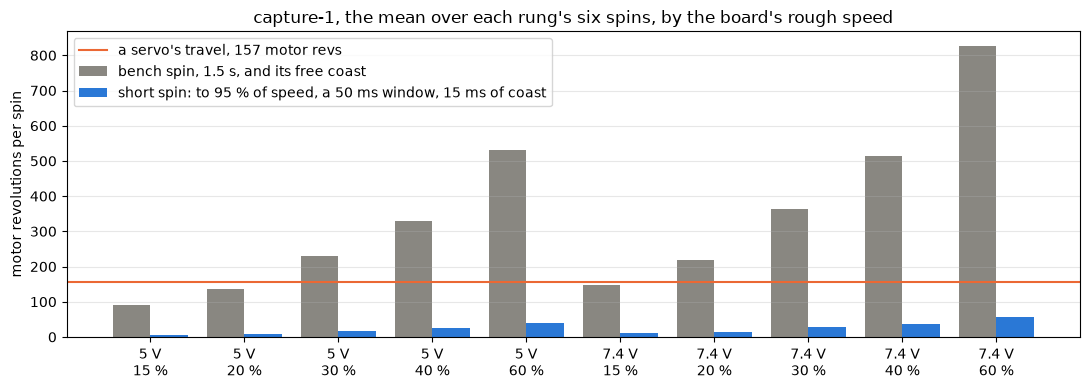

In [7]:
labels = [f"{v:g} V\n{d} %" for v, d in C1_COSTS.index]
x = np.arange(len(C1_COSTS))
bench = C1_COSTS["bench"] + C1_COSTS["cstop"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, bench, 0.4, color=figures.MUTED,
       label="bench spin, 1.5 s, and its free coast")
ax.bar(x + 0.2, C1_COSTS["short50"], 0.4, color=figures.BLUE,
       label="short spin: to 95 % of speed, a 50 ms window, 15 ms of coast")
ax.axhline(idn.TRAVEL_REVS, color=figures.ORANGE, lw=1.5,
           label=f"a servo's travel, {idn.TRAVEL_REVS:.0f} motor revs")
ax.set_xticks(x, labels)
ax.legend(loc="upper left")
figures.label(ax, y="motor revolutions per spin",
              title="capture-1, the mean over each rung's six spins, by the "
              "board's rough speed", grid=False)
ax.grid(alpha=figures.GRID_ALPHA, axis="y")
figures.finish(fig)

Gray is the bench's spin with its free coast, blue a short spin with a 50 ms window, and the orange line the travel. The thing to see is how far the bench spins overshoot and how far under the short ones stay. The bench spins used 89 to 774 revs each, and 7 of the 10 rungs do not fit 157 revs with their free coast. A short spin with a 50 ms window uses 6.5 to 58 revs. The spin-up to 95 % of speed takes 57 to 70 ms in every rung's mean. The rough board speed reads -7.5 to +9.6 % against the ripple tach at the spin's end, spin by spin, which is all a cost needs.

## Route 1. R from a locked seat

rest-resistance read $R$ at twelve holes of the bar with the rotor locked, a line through $V/I$ over each 300 ms lap at 100 % read back to the lap's start, the graded laps at 3.7 and 4.2 V in direction +1. A servo at its end stop has one seat. So each hole in turn is taken as the ident seat, its $R$ the mean of its two graded laps, and set against the angle average, the 12-hole mean. Two and three seats are every combination of two and three holes.

rest-resistance splits its hole map into a heat part, a one-body model of the heat carried from one hole to the next with a time constant of about 90 s, and an angle part, what is left. It holds that split at low to moderate confidence, so both are shown.

In [8]:
# rest-resistance's own cells, run unchanged in its folder: the lap table
# S, the hole table HOLE and the raw laps
RRN = idn.rest_resistance_cells()
HOLE, S, LAPS_RAW = RRN["HOLE"], RRN["S"], RRN["LAPS_RAW"]
# the cells reproduce rest-resistance's result
assert np.allclose(HOLE["r_plus"].to_numpy(), idn.RR["r_term_by_hole"],
                   atol=1e-4)
# the laps rest-resistance grades: direction +1 at 3.7 and 4.2 V
GRADED = S[S["graded"] & (S["dir"] == 1)]
print(idn.kept("graded +1 laps", GRADED, ["level"]))
seat_r = HOLE["r_plus"].to_numpy()   # one seat's R, its two graded laps
R_MED, R_MEAN = float(np.median(seat_r)), float(seat_r.mean())
R_DMM = float(idn.RR["r_ohms_median_ohm"]["value"])
angle_pct = HOLE["angle_pct"].to_numpy()   # rest-resistance's heat out
by_hole = pd.DataFrame({"r_ohm": seat_r,
                        "on_mean_pct": idn.pct(seat_r, R_MEAN),
                        "on_meter_pct": idn.pct(seat_r, R_DMM),
                        "angle_pct": angle_pct,
                        "heat_pct": HOLE["heat_pct"].to_numpy()},
                       index=HOLE.index)
print(f"rest-resistance's hole table reproduces r_term_by_hole to 1e-4 "
      f"ohm; the angle average over the 12 holes: median {R_MED:.4f}, "
      f"mean {R_MEAN:.4f} ohm; the meter's ohms {R_DMM:.3f} ohm (a day "
      f"later, at its milliamp)")
show(by_hole, n=None)

[graded +1 laps] kept 24 rows: 3.7:12, 4.2:12
rest-resistance's hole table reproduces r_term_by_hole to 1e-4 ohm; the angle average over the 12 holes: median 4.4553, mean 4.4629 ohm; the meter's ohms 4.100 ohm (a day later, at its milliamp)


,r_ohm,on_mean_pct,on_meter_pct,angle_pct,heat_pct
hole,,,,,
0,4.384,-1.777,6.916,-0.528,-1.083
1,4.453,-0.232,8.598,0.370,-0.432
2,4.443,-0.437,8.374,0.343,-0.611
3,4.407,-1.257,7.482,-0.772,-0.317
4,4.450,-0.298,8.526,0.593,-0.722
5,4.486,0.512,9.407,0.277,0.406
6,4.492,0.643,9.550,-0.061,0.875
7,4.531,1.523,10.508,0.873,0.823
8,4.510,1.052,9.996,0.508,0.716


Every mean of one, two and three seats against the 12-hole mean.

In [9]:
# every mean of k distinct holes against the 12-hole mean, as read and
# with rest-resistance's one-body heat taken out
SEATS, spread = {}, []
for name, x in (("as read", seat_r), ("angle part", 1 + angle_pct / 100)):
    for k in SEAT_COUNTS:
        c = idn.combos(x, k)
        SEATS[(name, k)] = c
        spread.append(dict(read=name, seats=k, combinations=len(c),
                           sd_pct=c.std(), max_abs_pct=np.abs(c).max(),
                           p95_abs_pct=np.percentile(np.abs(c), 95)))
show(pd.DataFrame(spread), n=None)
gap = idn.RR["direction_gap_pct"]
kept = idn.RR["direction_gap_kept"]["value"]
offset_mohm = idn.RR["direction_gap_offset_ohm"]["value"] * 1e3
print(f"the laps' own scatter about each hole's mean: "
      f"{RRN['REPEAT_PCT']:.2f} % (four graded laps per hole)")
print(f"direction -1 over +1: {gap['value']:+.2f} % as read "
      f"({gap['lo']:+.2f} to {gap['hi']:+.2f}); rest-resistance keeps "
      f"{kept:.2f} of a lap's rise into the next and leaves "
      f"{offset_mohm:+.1f} mohm")

,read,seats,combinations,sd_pct,max_abs_pct,p95_abs_pct
0,as read,1,12,0.910,1.777,1.637
1,as read,2,66,0.613,1.517,1.102
2,as read,3,220,0.475,1.157,0.870
3,angle part,1,12,0.564,0.991,0.926
4,angle part,2,66,0.380,0.881,0.722
5,angle part,3,220,0.295,0.763,0.575


the laps' own scatter about each hole's mean: 0.24 % (four graded laps per hole)
direction -1 over +1: +1.19 % as read (-1.13 to +2.20); rest-resistance keeps 0.59 of a lap's rise into the next and leaves +1.6 mohm


Each seat against the angle average, and every combination of seats.

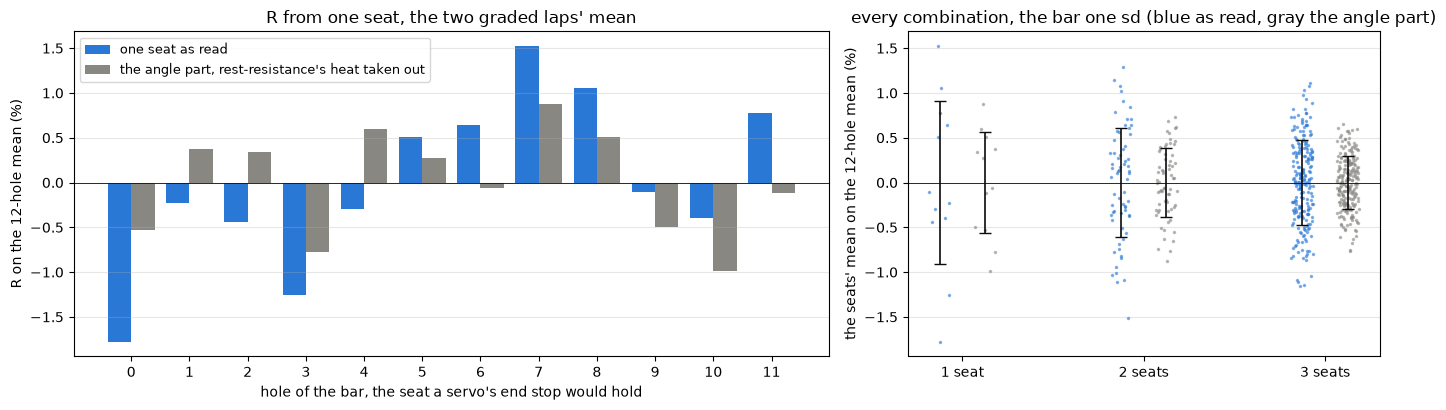

In [10]:
holes = HOLE.index
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2),
                       gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].bar(holes - 0.2, by_hole["on_mean_pct"], 0.4, color=figures.BLUE,
          label="one seat as read")
ax[0].bar(holes + 0.2, angle_pct, 0.4, color=figures.MUTED,
          label="the angle part, rest-resistance's heat taken out")
ax[0].axhline(0, color=figures.INK, lw=0.6)
ax[0].set_xticks(holes)
ax[0].legend(loc="upper left", fontsize=9)
figures.label(ax[0], x="hole of the bar, the seat a servo's end stop "
              "would hold", y="R on the 12-hole mean (%)",
              title="R from one seat, the two graded laps' mean", grid=False)
reads = (("as read", figures.BLUE), ("angle part", figures.MUTED))
for j, (name, color) in enumerate(reads):
    for k in SEAT_COUNTS:
        c = SEATS[(name, k)]
        x = k + (j - 0.5) * 0.25
        jitter = np.random.default_rng(k).uniform(-0.06, 0.06, len(c))
        ax[1].plot(np.full(len(c), x) + jitter, c, ".", ms=3, color=color,
                   alpha=0.5)
        ax[1].errorbar(x, 0, yerr=c.std(), color=figures.INK, capsize=4,
                       lw=1.2)
ax[1].axhline(0, color=figures.INK, lw=0.6)
ax[1].set_xticks((1, 2, 3), ("1 seat", "2 seats", "3 seats"))
figures.label(ax[1], y="the seats' mean on the 12-hole mean (%)",
              title="every combination, the bar one sd (blue as read, gray "
              "the angle part)", grid=False)
for a in ax:
    a.grid(alpha=figures.GRID_ALPHA, axis="y")
figures.finish(fig)

On the left, each seat against the 12-hole mean, blue as read and gray with the heat part taken out. On the right, every mean of one, two and three seats. The thing to see is how far one seat lands from the angle average, and how slowly more seats close it.

One seat lands within 0.91 % sd of the 12-hole mean, at worst 1.78 % low at hole 0, the first and coldest hole. Two seats come to 0.61 % sd, at worst 1.52 %, and three to 0.48 %, at worst 1.16 %. With the heat part out the same read 0.56, 0.38 and 0.29 %. A servo's ident would carry its own heat the same way, so the as-read numbers are the budget. The laps' own scatter about a hole's mean is 0.24 %, so the seat-to-seat spread is real at about four times that floor. Direction -1 reads 1.19 % over +1, which rest-resistance puts on the heat carried from the +1 lap a second earlier. This route reads direction +1 only.

### How long a hold

The same laps refitted over shorter stretches say how long a seat has to be held. Each hole's line through $V/I$ is cut at 80 to 300 ms and set against the full 300 ms read, and a plain mean of $V$ over $I$ is shown beside it.

In [11]:
# hold length: the graded +1 laps refitted over shorter stretches, each
# hole the mean of its 3.7 and 4.2 V laps, against the full 300 ms line
rows = []
for (k, v), pair in LAPS_RAW.items():
    if v < RRN["RAIL_GRADED_V"]:
        continue                     # the 3.3 V level is not graded
    lap = [p for p in pair if p["dir"] == 1][0]
    row = dict(hole=k, level=v)
    for T in HOLD_LINES_S:           # the line through V/I from 60 ms
        row[f"line_{int(T * 1e3)}"] = idn.lap_line(lap, T)
    for T in HOLD_MEANS_S:           # a plain mean V over mean I from 2 ms
        row[f"mean_{int(T * 1e3)}"] = idn.lap_mean(lap, T)
    rows.append(row)
HOLD_LAPS = pd.DataFrame(rows)
print(idn.kept("hold-length laps", HOLD_LAPS, ["level"]))
full = HOLD_LAPS.groupby("hole")["line_300"].mean()
# the 300 ms line is rest-resistance's own read
assert np.allclose(full.to_numpy(), seat_r, atol=2e-3)
reads = [c for c in HOLD_LAPS.columns if c.startswith(("line_", "mean_"))]
hold = []
for col in reads:
    per = HOLD_LAPS.groupby("hole")[col].mean()
    lev = HOLD_LAPS.pivot(index="hole", columns="level", values=col)
    d = idn.pct(per, full)
    # one level's lap alone against the hole's two-lap read
    one = np.concatenate([idn.pct(lev[3.7], full), idn.pct(lev[4.2], full)])
    hold.append(dict(read=col, hold_ms=int(col.split("_")[1]),
                     bias_pct=d.mean(),
                     rms_two_laps_pct=idn.rms(d - d.mean()),
                     rms_one_lap_pct=idn.rms(one - one.mean()),
                     map_corr=np.corrcoef(per, full)[0, 1]))
HOLD_READS = pd.DataFrame(hold)
show(HOLD_READS, n=None)

[hold-length laps] kept 24 rows: 3.7:12, 4.2:12


,read,hold_ms,bias_pct,rms_two_laps_pct,rms_one_lap_pct,map_corr
0,line_80,80,0.155,0.226,0.401,0.980
1,line_100,100,0.080,0.300,0.439,0.974
2,line_150,150,0.017,0.164,0.271,0.989
3,line_200,200,0.010,0.086,0.234,0.996
4,line_300,300,0.000,0.000,0.213,1.000
5,mean_20,20,0.859,0.397,0.465,0.929
6,mean_50,50,0.589,0.262,0.336,0.967
7,mean_100,100,0.598,0.155,0.231,0.988


What one lap draws, and the one locked PWM read in these data.

In [12]:
I_LAP = (GRADED["i_start"].min(), GRADED["i_start"].max())
J_LAP = (GRADED["joules"].min(), GRADED["joules"].max())
# the PWM read a servo on its own rail could make: inductance's bursts
burst_r = np.asarray(idn.IND["r_burst_ohm_by_hole"], float)
burst_sd = burst_r.std(ddof=1) / burst_r.mean() * 100
burst_med = np.median(burst_r)
print(f"one 100 % lap: {I_LAP[0]:.2f} to {I_LAP[1]:.2f} A, {J_LAP[0]:.2f} "
      f"to {J_LAP[1]:.2f} J, 0 motor revs (locked); at 100 % through "
      f"{R_MED:.3f} ohm a locked rotor draws {7.4 / R_MED:.2f} A on a "
      f"7.4 V rail and {5.0 / R_MED:.2f} A on 5.0 V")
print(f"inductance's 5 V locked bursts by hole, the period fit's R: "
      f"{burst_r.min():.3f} to {burst_r.max():.3f} ohm, sd "
      f"{burst_sd:.1f} % over the holes, median {burst_med:.3f} "
      f"({idn.pct(burst_med, R_MED):+.1f} % on the 100 % median); "
      f"correlation with the 100 % map by hole "
      f"{np.corrcoef(burst_r, seat_r)[0, 1]:+.2f}")

one 100 % lap: 0.72 to 0.85 A, 0.70 to 0.93 J, 0 motor revs (locked); at 100 % through 4.455 ohm a locked rotor draws 1.66 A on a 7.4 V rail and 1.12 A on 5.0 V
inductance's 5 V locked bursts by hole, the period fit's R: 4.078 to 4.614 ohm, sd 4.3 % over the holes, median 4.358 (-2.2 % on the 100 % median); correlation with the 100 % map by hole +0.23


The shorter holds against the full 300 ms line.

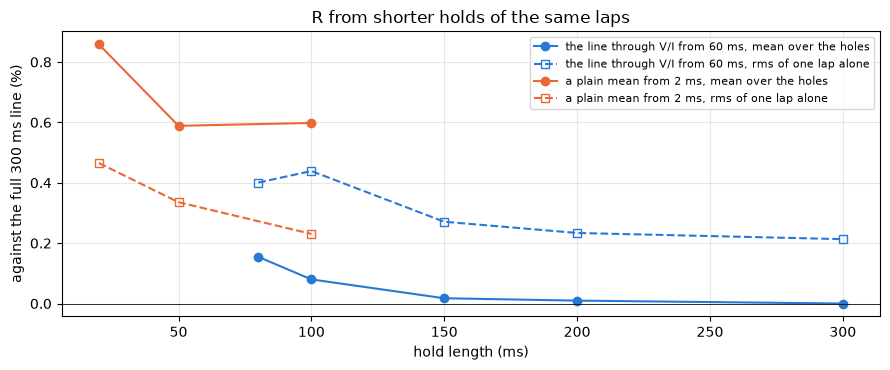

In [13]:
kinds = (("line_", figures.BLUE, "the line through V/I from 60 ms"),
         ("mean_", figures.ORANGE, "a plain mean from 2 ms"))
fig, ax = plt.subplots(figsize=(9, 3.8))
for kind, color, name in kinds:
    h = HOLD_READS[HOLD_READS["read"].str.startswith(kind)]
    ax.plot(h["hold_ms"], h["bias_pct"], "o-", color=color,
            label=f"{name}, mean over the holes")
    ax.plot(h["hold_ms"], h["rms_one_lap_pct"], "s--", color=color,
            mfc="none", label=f"{name}, rms of one lap alone")
ax.axhline(0, color=figures.INK, lw=0.6)
ax.legend(fontsize=8)
figures.label(ax, x="hold length (ms)",
              y="against the full 300 ms line (%)",
              title="R from shorter holds of the same laps")
figures.finish(fig)

Solid lines are the mean offset over the holes, dashed lines the rms of one lap read alone. The thing to see is that the line through $V/I$ holds its value down to about 150 ms, while a plain mean reads high at every length. A 200 ms line reads +0.01 % with an rms of 0.09 % over two laps, 150 ms +0.02 % (0.16 %) and 100 ms +0.08 % (0.30 %). A plain mean over 2 to 20 ms reads +0.86 % high, because the early fall of $V/I$ is in it. One lap alone carries 0.21 % rms even at 300 ms. So one 200 ms lap at each of two levels gives $R$ to about 0.1 % of the full read, high confidence.

### Against the meter, and the current it takes

Every seat reads 6.9 to 10.5 % over the meter's 4.100 ohm at its milliamp. Two things differ there, the current, milliamps against about 0.78 A, and the sitting, a day later. The board route reads $R$ at the motor's working current, which is the $R$ the estimate uses.

The route as captured needs the rail trimmed to 3.7 and 4.2 V, and it draws 0.72 to 0.85 A and 0.70 to 0.93 J per 300 ms lap. That is over the 0.5 A a metal-gear servo's end stop should hold, and on the servo's own 7.4 V rail 100 % would draw 1.66 A. A servo on its own rail would hold a PWM duty instead. The only locked PWM read in these data is inductance's 5 V bursts, whose period-fit $R$ spans 4.078 to 4.614 ohm by hole, an sd of 4.3 %, with its median 2.2 % under the 100 % median. It correlates only +0.23 with the 100 % map by hole. So a PWM hold does not stand in for the 100 % lap on these data, moderate confidence, since it is one capture and one model's $R$.

## Route 2. R and temperature

Copper's resistance rises about 0.39 % per degree. The board carries an NTC, so the simplest route to $R$ at temperature is $R_\mathrm{ref}\,(1 + \alpha\,(T - T_\mathrm{ref}))$, with $\alpha$ copper's coefficient, $T$ the board NTC and $T_\mathrm{ref}$ the board at the reference read. The NTC goes through the nominal beta, which stage 1's ntc-curve grades as the conversion that stands.

In the motor rig the bare motor sits away from the board, so the NTC reads the board and the room, not the winding. This section asks how far the board's temperature moves $R$ across stage 2's sittings, and then bounds the winding's own rise above it.

In [14]:
# the board NTC at every TEL capture's rest baseline, through the nominal
# beta that stage 1's ntc-curve grades
NC = results.read("1-board", "ntc-curve", pair=idn.BOARD.key)
# the conversion is the one ntc-curve grades
assert NC["beta_nominal"]["value"] == idn.BOARD.ntc_beta
print(f"NTC: nominal beta {idn.BOARD.ntc_beta} K, R25 "
      f"{idn.BOARD.ntc_r25_ohm} ohm, pull-up {idn.BOARD.ntc_pullup_ohm} "
      f"ohm; ntc-curve's room plateau sits {NC['gap_at_25_c']['value']:.2f} "
      f"C off the thermocouple at 25 C, and its refit beta "
      f"{NC['beta_fit']['value']:.0f} is not a constant")
NTC_CAPS = [("bemf-coast/capture-1", "cycles.csv"),
            ("speed-torque/capture-1", "cycles.csv"),
            ("rest-resistance/capture-1/stall", "laps.csv"),
            ("bemf-coast/meter-1", "cycles.csv"),
            ("bemf-coast/swapped-1", "wired.csv"),
            ("bemf-coast/swapped-1", "swapped.csv"),
            ("bemf-coast/high-1", "cycles.csv")]
jobs, keys = [], []
for cap, tab in NTC_CAPS:
    root = idn.PAIR / cap
    block = "" if tab in ("cycles.csv", "laps.csv") else f" ({tab[:-4]})"
    for _, C in pd.read_csv(root / tab).iterrows():
        jobs.append((idn.folder_ntc, (root / C["folder"],), {}))
        keys.append(dict(capture=cap + block, t=float(C["t_start"])))
ntc = parallel.run_parallel(jobs)
NT = pd.DataFrame([dict(k, **v) for k, v in zip(keys, ntc)])
NTC_T0 = NT["t"].min()
# the burst sittings, which carry no ntc_raw
bursts = ("capture-1", "reversal-1", "steps-1", "fast-1")
marks = [pd.read_csv(idn.PAIR / "inductance" / n / "marks.csv")
         for n in bursts]
IT = pd.DataFrame({"capture": [f"inductance/{n}" for n in bursts],
                   "t": [float(m["t_host"].min()) for m in marks]})
# the board at the stall pass's graded laps, the reference R's temperature
T_REF = float(GRADED["board_c"].median())
print(f"T_ref, the board at the stall pass's graded +1 laps: median "
      f"{T_REF:.2f} C ({GRADED['board_c'].min():.2f} to "
      f"{GRADED['board_c'].max():.2f}); ohms-1's can thermocouple a day "
      f"later {idn.RR['ohms_room_c1_c']['value']:.2f} and "
      f"{idn.RR['ohms_room_c2_c']['value']:.2f} C, no board in that sitting")

NTC: nominal beta 3950 K, R25 10000 ohm, pull-up 10000 ohm; ntc-curve's room plateau sits 0.57 C off the thermocouple at 25 C, and its refit beta 4331 is not a constant


T_ref, the board at the stall pass's graded +1 laps: median 25.67 C (25.52 to 25.78); ohms-1's can thermocouple a day later 25.20 and 25.81 C, no board in that sitting


What copper at the board's temperature does to R, capture by capture.

In [15]:
NT["r_move_pct"] = idn.ALPHA_CU * (NT["ntc_c"] - T_REF) * 100
by_cap = NT.groupby("capture", sort=False)
show(pd.DataFrame({"hours": (by_cap["t"].min() - NTC_T0) / 3600,
                   "folders": by_cap.size(),
                   "ntc_raw_lo": by_cap["ntc_raw"].min(),
                   "ntc_raw_hi": by_cap["ntc_raw"].max(),
                   "board_lo_c": by_cap["ntc_c"].min(),
                   "board_hi_c": by_cap["ntc_c"].max(),
                   "board_median_c": by_cap["ntc_c"].median(),
                   "r_move_lo_pct": by_cap["r_move_pct"].min(),
                   "r_move_hi_pct": by_cap["r_move_pct"].max()}), n=None)
burst_h = ", ".join(f"{c} {(t - NTC_T0) / 3600:.2f} h"
                    for c, t in zip(IT["capture"], IT["t"]))
BOARD_SPAN = NT["ntc_c"].max() - NT["ntc_c"].min()
SPIN_CAPS = ["bemf-coast/capture-1", "speed-torque/capture-1",
             "bemf-coast/swapped-1 (wired)", "bemf-coast/swapped-1 (swapped)"]
MOVE = NT[NT["capture"].isin(SPIN_CAPS)]["r_move_pct"]
print(f"no ntc_raw in a burst capture: {burst_h}")
print(f"over every TEL capture the board spans {BOARD_SPAN:.2f} C, "
      f"{BOARD_SPAN * idn.ALPHA_CU * 100:.2f} % of copper R at most; the "
      f"spinning captures this notebook reads: R moves {MOVE.min():+.2f} "
      f"to {MOVE.max():+.2f} % by the board NTC")

,hours,folders,ntc_raw_lo,ntc_raw_hi,board_lo_c,board_hi_c,board_median_c,r_move_lo_pct,r_move_hi_pct
capture,,,,,,,,,
bemf-coast/capture-1,0.000,30,2011.000,2087.000,24.145,25.815,25.022,-0.595,0.056
speed-torque/capture-1,0.636,3,2031.000,2034.000,25.308,25.374,25.308,-0.142,-0.116
rest-resistance/capture-1/stall,1.229,36,2011.000,2024.000,25.528,25.815,25.683,-0.056,0.056
bemf-coast/meter-1,24.651,9,1982.000,2010.000,25.838,26.458,26.147,0.065,0.307
bemf-coast/swapped-1 (wired),24.862,6,1992.000,2007.000,25.904,26.236,26.192,0.090,0.220
bemf-coast/swapped-1 (swapped),25.004,6,1987.000,1987.000,26.347,26.347,26.347,0.263,0.263
bemf-coast/high-1,27.625,9,1986.000,2036.000,25.264,26.369,25.904,-0.159,0.272


no ntc_raw in a burst capture: inductance/capture-1 21.96 h, inductance/reversal-1 22.64 h, inductance/steps-1 23.86 h, inductance/fast-1 23.88 h
over every TEL capture the board spans 2.31 C, 0.90 % of copper R at most; the spinning captures this notebook reads: R moves -0.60 to +0.26 % by the board NTC


One dot per folder's rest baseline, the spinning captures in blue.

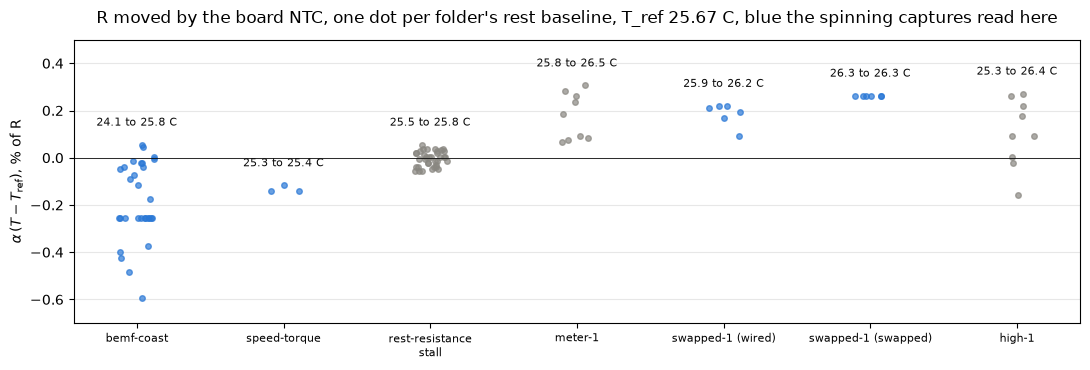

In [16]:
order = list(NT["capture"].unique())
ticks = [c.replace("/capture-1", "").replace("bemf-coast/", "")
         .replace("/", "\n") for c in order]
fig, ax = plt.subplots(figsize=(11, 3.8))
for j, cap in enumerate(order):
    sitting = NT[NT["capture"] == cap]
    move = sitting["r_move_pct"]
    jitter = np.random.default_rng(j).uniform(-0.12, 0.12, len(sitting))
    color = figures.BLUE if cap in SPIN_CAPS else figures.MUTED
    ax.plot(np.full(len(sitting), j) + jitter, move, "o", ms=4,
            color=color, alpha=0.7)
    span = f"{sitting['ntc_c'].min():.1f} to {sitting['ntc_c'].max():.1f} C"
    ax.text(j, move.max() + 0.08, span, ha="center", fontsize=8,
            color=figures.INK)
ax.axhline(0, color=figures.INK, lw=0.6)
ax.set_ylim(-0.7, 0.5)
ax.set_xticks(range(len(order)), ticks, fontsize=8)
figures.label(ax, y=r"$\alpha\,(T - T_\mathrm{ref})$, % of R", grid=False)
ax.set_title(f"R moved by the board NTC, one dot per folder's rest "
             f"baseline, T_ref {T_REF:.2f} C, blue the spinning captures "
             f"read here", pad=12)
ax.grid(alpha=figures.GRID_ALPHA, axis="y")
figures.finish(fig)

One dot per folder's rest baseline, blue for the spinning captures this notebook reads, with each capture's board range written above it. The thing to see is how little the board moves. capture-1 runs -0.60 to +0.06 %, speed-torque -0.14 to -0.12 % and swapped-1 +0.09 to +0.26 %. So across these sittings the board NTC moves $R$ by only -0.60 to +0.26 %. Over every TEL capture, a day apart, the board spans 2.31 C, at most 0.90 % of $R$. The bare motor sat near room temperature throughout, so the NTC had little to report.

The stall pass is $T_\mathrm{ref}$, at 25.67 C, and it has no other thermometer. ohms-1's can thermocouple read 25.20 and 25.81 C a day later with no board in that sitting. The inductance sittings carry no `ntc_raw` at all.

### The winding's own rise

The NTC does not see the winding, so the winding's rise above the board is bounded from stage 2's thermal numbers. One bound is rest-resistance's warming of the copper per joule within a lap, 2.86 % per J with no time to cool, for a spin's own joules. The other is rest-resistance's one-body map, 0.716 % per J held with a 90 s time constant, for the heat carried from earlier spins. Both let none of a spin's heat leave the copper within the spin, so both are upper bounds.

In [17]:
# the winding's own rise above the board, bounded from rest-resistance's
# thermal numbers: the copper's warming per joule in a lap (no time to
# cool) for a spin's own joules, and the one-body map's 0.716 %/J held with
# its time constant for heat carried from earlier cycles. Both let none of
# a spin's heat leave the copper within the spin, so both are upper bounds.
warming = idn.RR["warming_pct_per_j"]
WPJ = warming["value"] / 100
BODY_PCT_PER_J = float(RRN["best"]["slope"]) / 100   # held, per J
TAU_BODY = idn.RR["hole_map_body_tau_s"]["value"]
print(f"copper {WPJ * 100:.2f} %/J within a lap ({warming['lo']:.2f} to "
      f"{warming['hi']:.2f}), copper tau "
      f"{idn.RR['copper_tau_s']['value']:.1f} s; carried heat "
      f"{BODY_PCT_PER_J * 100:.3f} %/J held, tau {TAU_BODY:.0f} s")
HEAT, heat_rows = {}, []
for run in ("capture-1", "swapped-wired", "swapped-swapped"):
    T = TB[run]
    # the crest over-reads the mean, so the watts are an upper bound
    watts = idn.R_LOCKED * (T["i_crest_200"] * 1e-3) ** 2
    e_spin = watts * T["spin_rows"] / idn.FS
    own = WPJ * e_spin
    t = T["t_start"].to_numpy()
    joules = e_spin.to_numpy()
    carried = []
    for ti in t:
        before = t < ti
        decay = np.exp(-(ti - t[before]) / TAU_BODY)
        carried.append(BODY_PCT_PER_J * np.sum(joules[before] * decay))
    carried = np.array(carried)
    HEAT[run] = own.to_numpy() + carried
    heat_rows.append(dict(
        run=run, joules_lo=e_spin.min(), joules_hi=e_spin.max(),
        mw_lo=watts.min() * 1e3, mw_hi=watts.max() * 1e3,
        own_lo_pct=own.min() * 100, own_hi_pct=own.max() * 100,
        carried_lo_pct=carried.min() * 100,
        carried_hi_pct=carried.max() * 100,
        h_lo_pct=HEAT[run].min() * 100, h_hi_pct=HEAT[run].max() * 100,
        copper_c=HEAT[run].max() / idn.ALPHA_CU))
show(pd.DataFrame(heat_rows), n=None)

copper 2.86 %/J within a lap (1.92 to 3.48), copper tau 1.9 s; carried heat 0.716 %/J held, tau 90 s


,run,joules_lo,joules_hi,mw_lo,mw_hi,own_lo_pct,own_hi_pct,carried_lo_pct,carried_hi_pct,h_lo_pct,h_hi_pct,copper_c
0,capture-1,0.028,0.095,18.912,63.247,0.081,0.272,0.000,0.094,0.082,0.366,0.939
1,swapped-wired,0.067,0.080,44.632,53.390,0.192,0.229,0.000,0.084,0.200,0.314,0.804
2,swapped-swapped,0.064,0.080,42.731,53.167,0.184,0.228,0.000,0.084,0.184,0.308,0.789


The copper joules of every capture-1 spin and every speed-torque run-up, from the drive's start.

In [18]:
# copper joules from the drive's start, every spin of capture-1 and every
# speed-torque run-up
JF = [x for x in idn.cycle_folders() if x[0] in ("capture-1", "speed-torque")]
parts = parallel.run_parallel([(idn.copper_joules, (f,), {})
                               for run, C, f in JF])
rows = []
for (run, C, f), part in zip(JF, parts):
    for spin in part:
        rows.append(dict(spin, run=run, k=int(C["k"]),
                         level=float(C["volts_set"]),
                         duty=int(C["duty_pct"])))
EN = pd.DataFrame(rows)
RU_E = EN[EN["run"] == "speed-torque"]
runups = []
for _, run_up in RU_E.sort_values(["k", "dir"]).iterrows():
    e = run_up["e"]
    row = dict(k=run_up["k"], dir=run_up["dir"])
    for mark in JOULE_MARKS_S:
        row[f"j_{int(mark * 1e3)}ms"] = np.interp(mark, run_up["t"], e)
    row.update(j_cut=e[-1], rise_pct=WPJ * e[-1] * 100,
               rise_c=WPJ * e[-1] / idn.ALPHA_CU)
    runups.append(row)
show(pd.DataFrame(runups), n=None)
SELF_SPIN = max(h.max() for h in HEAT.values()) * 100
SELF_RUNUP = WPJ * max(e[-1] for e in RU_E["e"]) * 100
print(f"the self-heat bound: at most {SELF_SPIN:.2f} % of R on a free "
      f"spin, {SELF_RUNUP:.2f} % on a 100 % run-up")

,k,dir,j_50ms,j_100ms,j_cut,rise_pct,rise_c
0,0,-1,0.054,0.059,0.070,0.201,0.516
1,0,1,0.056,0.061,0.075,0.215,0.551
2,1,-1,0.057,0.062,0.074,0.211,0.542
3,1,1,0.056,0.061,0.075,0.215,0.550
4,2,-1,0.057,0.061,0.073,0.209,0.535
5,2,1,0.056,0.062,0.076,0.216,0.554


the self-heat bound: at most 0.37 % of R on a free spin, 0.22 % on a 100 % run-up


Free spins put 19 to 63 mW into the copper, up to 0.095 J per 1.5 s spin, and raise $R$ by at most 0.08 to 0.37 %, 0.9 C. A 100 % run-up puts 0.054 to 0.057 J in by 50 ms and 0.070 to 0.076 J by the cut, at most 0.22 % of $R$, 0.6 C. So the board stands in for the winding's temperature to under 0.4 % of $R$ in every capture here, moderate confidence, since the bounds lean on rest-resistance's thermal model.

### R between sittings

Two more questions. Whether the board sees the motor's own heat at all, and whether $R$ moves between sittings by more than temperature can explain.

In [19]:
# the stall pass against its own board NTC
board_by_hole = GRADED.groupby("hole")["board_c"].mean()
# what copper's coefficient predicts from the board alone
pred = (board_by_hole - board_by_hole.mean()) * idn.ALPHA_CU * 100
corr_map = np.corrcoef(board_by_hole, HOLE["map_pct"])[0, 1]
corr_heat = np.corrcoef(board_by_hole, HOLE["heat_pct"])[0, 1]
span = board_by_hole.max() - board_by_hole.min()
print(f"stall pass, per hole: board {board_by_hole.min():.2f} to "
      f"{board_by_hole.max():.2f} C (span {span:.2f} C), which at copper's "
      f"{idn.ALPHA_CU * 100:.2f} %/C predicts {pred.min():+.2f} to "
      f"{pred.max():+.2f} % of R; the map spans "
      f"{HOLE['map_pct'].min():+.2f} to {HOLE['map_pct'].max():+.2f} %, "
      f"the one-body heat part {HOLE['heat_pct'].min():+.2f} to "
      f"{HOLE['heat_pct'].max():+.2f} %")
print(f"correlation of the board NTC with the map {corr_map:+.2f}, with the "
      f"heat part {corr_heat:+.2f}")

stall pass, per hole: board 25.52 to 25.77 C (span 0.25 C), which at copper's 0.39 %/C predicts -0.05 to +0.04 % of R; the map spans -1.61 to +1.70 %, the one-body heat part -1.08 to +1.06 %
correlation of the board NTC with the map +0.14, with the heat part +0.47


R by sitting and route, with the board NTC where the sitting carries it.

In [20]:
slow_r = idn.MM["motor_r_slow_ohm_by_capture"]
slow_sittings = ("capture-1", "reversal-1", "fast-1")
board_at = NT.groupby("capture")["ntc_c"].median()
runup_a = idn.RR["r_runup_amps"]["value"]
running = idn.MM["running_r_low_speed_ohm"]["route a"]["value"]
sittings = [
    ("stall pass, 100 % laps, 12 holes", R_MED, board_by_hole.median()),
    (f"speed-torque run-up start, {runup_a:.2f} A",
     idn.RR["r_runup_ohm"]["value"], board_at["speed-torque/capture-1"]),
    ("bemf-coast capture-1, running R under 160 rev/s (motor-model)",
     running, board_at["bemf-coast/capture-1"])]
for n in slow_sittings:
    sittings.append((f"inductance {n}, hole 11, slow-decay series R "
                     f"(motor-model)", slow_r[n]["value"], np.nan))
show(pd.DataFrame(sittings, columns=["sitting and route", "r_ohm",
                                     "board_c"]), n=None)
hole_11 = np.array([slow_r[n]["value"] for n in slow_sittings])
move = hole_11.max() / hole_11.min() - 1
print(f"the one same-route, same-seat repeat across sittings, inductance's "
      f"hole 11: {hole_11.min():.3f} to {hole_11.max():.3f} ohm, "
      f"{move * 100:.1f} %, which copper would need "
      f"{move / idn.ALPHA_CU:.0f} C for")

,sitting and route,r_ohm,board_c
0,"stall pass, 100 % laps, 12 holes",4.455,25.673
1,"speed-torque run-up start, 0.91 A",4.182,25.308
2,"bemf-coast capture-1, running R under 160 rev/s (motor-model)",4.316,25.022
3,"inductance capture-1, hole 11, slow-decay series R (motor-model)",4.445,NaN
4,"inductance reversal-1, hole 11, slow-decay series R (motor-model)",4.304,NaN
5,"inductance fast-1, hole 11, slow-decay series R (motor-model)",4.196,NaN


the one same-route, same-seat repeat across sittings, inductance's hole 11: 4.196 to 4.445 ohm, 5.9 %, which copper would need 15 C for


Within the stall pass the board spans 0.25 C, which predicts $\pm$0.05 % of $R$ against a map of 3.3 %. It correlates +0.14 with the map and +0.47 with rest-resistance's heat part, so the board does not see the motor's own heat.

Between sittings, the one same-route, same-seat repeat is inductance's hole 11 slow-decay $R$, 4.445, 4.304 and 4.196 ohm over capture-1, reversal-1 and fast-1, within two hours of one day. That is a 5.9 % move, which copper would need 15 C for, and none of those sittings recorded the NTC. The TEL sittings read $R$ by different routes, 4.455 ohm at the stall, 4.182 at the run-up's start and 4.316 for the running $R$ under 160 rev/s. So these data cannot tell temperature from the route or the contact as the cause of $R$'s 3 to 6 % moves between sittings. I stop there, without a thermal model.

### The reference rung

Within one sitting, $R$ can be tracked without a locked read. At a low rung $V_b$ is near zero, and what is left of it is common to the rung, so it cancels in a change over time. The candidate is the running $R$ at the cut, $R = (V_\mathrm{mean} - E_0)/\hat i$, with $E_0$ the coast's EMF at the cut and $\hat i$ the crest less the published $\Delta$, over the 200 and 50 ms windows, at capture-1's four low rungs. Each rung's three repeats spread over about 2.5 minutes, so a drift over the sitting would show as a trend, and the board NTC sits beside it.

In [21]:
# the running R at the cut per spin, R = (V_mean - E0) / i_hat, at
# capture-1's four low rungs, over the 200 and 50 ms windows
ntc_folder = NT.set_index("folder")   # each folder's rest baseline NTC
windows = []
for pre in WINDOWS_MS:
    spins = idn.signals(TB["capture-1"], FT_PUB, pre)
    volts = spins["v_mean_d"] - spins["e_cut"]
    spins["r_run"] = volts / (spins["i_hat_d"] * 1e-3)
    spins["pre"] = pre
    spins["ntc_c"] = ntc_folder.loc[spins["folder"], "ntc_c"].to_numpy()
    windows.append(spins)
LOW_SPINS = pd.concat(windows, ignore_index=True)
LOW_SPINS = LOW_SPINS[idn.in_rungs(LOW_SPINS, idn.LOW_RUNGS)]
print(idn.kept("low rungs, both windows", LOW_SPINS,
               ["pre", "level", "duty"]))
sitting_t0 = TB["capture-1"]["t_start"].min()
LOW_SPINS["t_min"] = (LOW_SPINS["t_start"] - sitting_t0) / 60

[low rungs, both windows] kept 48 rows: (50, 5.0, 15):6, (50, 5.0, 20):6, (50, 7.4, 15):6, (50, 7.4, 20):6, (200, 5.0, 15):6, (200, 5.0, 20):6, (200, 7.4, 15):6, (200, 7.4, 20):6


Each low rung's spin-to-spin scatter with the direction means out, and its trend over the sitting.

In [22]:
fits, RESID = [], {}
for (pre, lv, du), rung in LOW_SPINS.groupby(["pre", "level", "duty"]):
    mean_r = rung["r_run"].mean()
    by_dir = rung.groupby("dir")["r_run"].transform("mean")
    resid = (rung["r_run"] - by_dir) / mean_r * 100   # direction means out
    # pooled within direction, two means fitted
    sd = float(np.sqrt((resid ** 2).sum() / (len(rung) - 2)))
    # the trend over the sitting
    b, cov = np.polyfit(rung["t_min"], resid, 1, cov=True)
    # the two direction means cost a dof polyfit does not count
    cov = cov * (len(rung) - 2) / (len(rung) - 3)
    se = np.sqrt(cov[0, 0])
    ntc_by_rep = rung.groupby("repeat")["ntc_c"].first()
    ntc_moved = ntc_by_rep.iloc[-1] - ntc_by_rep.iloc[0]
    RESID[(pre, lv, du)] = rung.assign(resid=resid)
    fits.append(dict(
        pre=pre, level=lv, duty=du, rev_s=rung["spin_rev_s"].mean(),
        r=mean_r, on_locked_pct=idn.pct(mean_r, idn.R_LOCKED), sd_pct=sd,
        trend_pct_per_min=b[0], trend_se=se, z=b[0] / se,
        span_min=rung["t_min"].max() - rung["t_min"].min(),
        ntc_moved_c=ntc_moved,
        ntc_predicts_pct=ntc_moved * idn.ALPHA_CU * 100,
        spins_per_check=idn.spins_for_change(sd)))
LOW_RUNG_R = pd.DataFrame(fits)
show(LOW_RUNG_R, n=None)

,pre,level,duty,rev_s,r,on_locked_pct,sd_pct,trend_pct_per_min,trend_se,z,span_min,ntc_moved_c,ntc_predicts_pct,spins_per_check
0,50,5.000,15,64.721,4.268,-4.208,1.417,-1.021,0.290,-3.515,2.490,0.438,0.171,17
1,50,5.000,20,93.537,4.344,-2.497,1.450,-0.742,0.522,-1.422,2.480,0.373,0.146,17
2,50,7.400,15,105.605,3.995,-10.332,2.392,1.385,0.777,1.782,2.476,0.352,0.137,46
3,50,7.400,20,149.255,4.222,-5.232,1.620,-0.159,0.751,-0.212,2.473,0.110,0.043,22
4,200,5.000,15,64.721,4.281,-3.917,1.599,-0.964,0.490,-1.968,2.490,0.438,0.171,21
5,200,5.000,20,93.537,4.347,-2.437,1.458,-0.792,0.501,-1.581,2.480,0.373,0.146,17
6,200,7.400,15,105.605,4.001,-10.197,2.214,1.017,0.849,1.198,2.476,0.352,0.137,40
7,200,7.400,20,149.255,4.220,-5.278,1.859,-0.087,0.867,-0.100,2.473,0.110,0.043,28


The 5 V block's low rungs against the 7.4 V block's, read about 20 minutes later.

In [23]:
for pre in WINDOWS_MS:
    window = LOW_SPINS[LOW_SPINS["pre"] == pre]
    blk = window.groupby("level").agg(r=("r_run", "mean"),
                                      ntc=("ntc_c", "mean"),
                                      t=("t_min", "mean"))
    lo, hi = blk.loc[5.0], blk.loc[7.4]
    ntc_step = (hi["ntc"] - lo["ntc"]) * idn.ALPHA_CU * 100
    print(f"{pre} ms block means: 5 V low rungs {lo['r']:.3f} ohm at "
          f"{lo['ntc']:.2f} C (minute {lo['t']:.0f}), 7.4 V {hi['r']:.3f} "
          f"at {hi['ntc']:.2f} C (minute {hi['t']:.0f}); the NTC step "
          f"predicts {ntc_step:+.2f} %, the R step is "
          f"{idn.pct(hi['r'], lo['r']):+.2f} %")

200 ms block means: 5 V low rungs 4.314 ohm at 24.59 C (minute 3), 7.4 V 4.111 at 25.35 C (minute 22); the NTC step predicts +0.30 %, the R step is -4.71 %
50 ms block means: 5 V low rungs 4.306 ohm at 24.59 C (minute 3), 7.4 V 4.109 at 25.35 C (minute 22); the NTC step predicts +0.30 %, the R step is -4.58 %


One panel per low rung, each spin's running R over the 200 ms window.

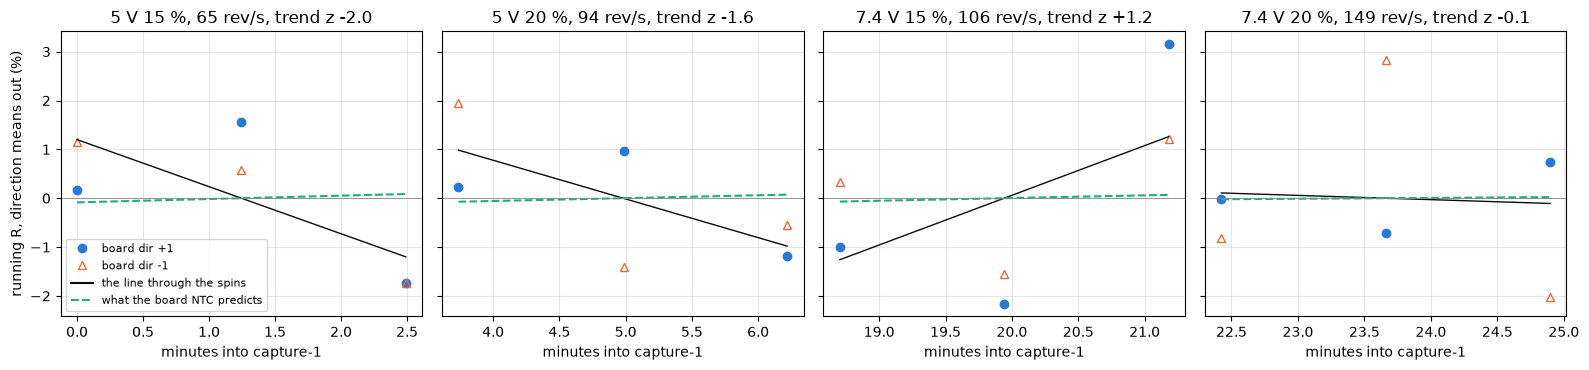

In [24]:
trend = LOW_RUNG_R.set_index(["pre", "level", "duty"])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for a, (lv, du) in zip(ax, idn.LOW_RUNGS):
    rung = RESID[(BENCH_MS, lv, du)].sort_values("t_min")
    fit = trend.loc[(BENCH_MS, lv, du)]
    for d in (1, -1):
        mine = rung[rung["dir"] == d]
        a.plot(mine["t_min"], mine["resid"],
               **figures.direction_style(d, MECH_COLOR[d]),
               label=f"board dir {d:+d}")
    ends = np.linspace(rung["t_min"].min(), rung["t_min"].max(), 2)
    slope = fit["trend_pct_per_min"]
    middle = rung["resid"].mean() - slope * rung["t_min"].mean()
    ntc = fit["ntc_predicts_pct"]
    ntc_line = (ends - ends[0]) / (ends[1] - ends[0]) * ntc - ntc / 2
    a.plot(ends, np.polyval([slope, middle], ends), color=figures.INK, lw=1)
    a.plot(ends, ntc_line, color=figures.GREEN, lw=1.5, ls="--")
    a.axhline(0, color=figures.MUTED, lw=0.6)
    figures.label(a, x="minutes into capture-1",
                  title=f"{lv:g} V {du} %, {fit['rev_s']:.0f} rev/s, trend "
                  f"z {fit['z']:+.1f}")
ax[0].plot([], [], color=figures.INK, label="the line through the spins")
ax[0].plot([], [], color=figures.GREEN, ls="--",
           label="what the board NTC predicts")
ax[0].legend(fontsize=8, loc="lower left")
figures.label(ax[0], y="running R, direction means out (%)", grid=False)
figures.finish(fig)

One panel per rung, each spin's running $R$ with its direction's mean taken out, the black line through the spins and the green line the slope the board NTC predicts. The thing to see is that the spins scatter about 1.5 % and the lines go both ways.

One spin of 5 V 15 %, at 65 rev/s, scatters 1.42 % over the 50 ms window and 1.60 % over 200 ms. A change of 0.5 % between two checks therefore needs 17 to 21 spins per check, half each way. The steepest line, 5 V 15 % at -0.96 $\pm$ 0.49 % per minute (z -2.0 over 200 ms, -3.5 over 50 ms, the two direction means counted against the dof), falls while the board warms 0.44 C, which predicts +0.17 %, the opposite of copper. The other three split in sign. So capture-1 shows no common drift of $R$ over its sitting, and the one excursion is not thermal, moderate confidence with six spins per rung.

The running $R$ at these rungs sits 2.4 to 10.2 % under the locked $R$, so it is a relative thermometer only. The 7.4 V block reads its low rungs 4.7 % under the 5 V block, about 20 minutes later, while the NTC step predicts +0.30 %. That is the low-speed offset route 6 finds in $V_b$ under 160 rev/s, read here as $R$, and not a drift.

### Sizing the checks

A check is only useful if the blocks of spins between checks keep the winding's rise small. Stage 2's thermal numbers size them. The copper's heat capacity is the teardown's cool-winding heating power over its first rate of rise, with its fast and slow time constants, and the body's is rest-resistance's one-body map at copper's coefficient. Each maneuver's copper joules are $R\,i^2$ integrated over its own current from the drive's start, an upper bound at partial duty, since the crest sample reads over the mean there.

In [25]:
# the copper as its own thermometer: how much heat a block of spins
# leaves, from stage 2's thermal numbers only
TD = idn.TD
# the teardown's cool winding: watts over the initial rate
C_COPPER = TD["heat_power_w"]["value"] / TD["heat_rate_c_per_s"]["value"]
TAU_FAST, TAU_SLOW = TD["fast_tau_s"]["value"], TD["slow_tau_s"]["value"]
# rest-resistance's one-body map at copper's coefficient, J/C
C_BODY = idn.ALPHA_CU / BODY_PCT_PER_J
m_rot = TD["mass_rotor_g"]["value"]
in_lap = idn.RR["copper_heat_capacity_max_j_per_c"]["value"]
print(f"copper {C_COPPER:.3f} J/C (teardown's cool-winding, "
      f"{TD['heat_power_w']['value']:.2f} W over "
      f"{TD['heat_rate_c_per_s']['value']:.2f} C/s; rest-resistance's in-lap "
      f"bound {in_lap:.3f}), fast tau {TAU_FAST:.2f} s, slow tau "
      f"{TAU_SLOW:.0f} s")
print(f"body {C_BODY:.2f} J/C (rest-resistance's one-body map); teardown's "
      f"rotor {m_rot:.3f} g would be {m_rot * COPPER_J_PER_G_C:.2f} J/C as "
      f"copper and {m_rot * IRON_J_PER_G_C:.2f} as iron")

copper 0.138 J/C (teardown's cool-winding, 2.46 W over 17.85 C/s; rest-resistance's in-lap bound 0.134), fast tau 2.15 s, slow tau 96 s
body 0.54 J/C (rest-resistance's one-body map); teardown's rotor 1.123 g would be 0.43 J/C as copper and 0.51 as iron


Each rung's copper joules from the drive's start, at the spin-up, a short spin with a 50 or a 200 ms window, and the bench spin.

In [26]:
for ms in MARKS_MS:
    rows = [min(int(ms * idn.FS / 1000), len(e) - 1) for e in EN["e"]]
    EN[f"e_{ms}ms"] = [float(e[row]) for e, row in zip(EN["e"], rows)]
JOULES = EN.groupby(["run", "level", "duty"])[
    [f"e_{ms}ms" for ms in MARKS_MS]].mean()
show(JOULES, n=None)

e_65ms  e_115ms  e_265ms  e_1500ms
run          level duty                                    
capture-1    5.000 15     0.003    0.004    0.007     0.032
                   20     0.004    0.006    0.009     0.040
                   30     0.008    0.010    0.015     0.055
                   40     0.012    0.014    0.020     0.064
                   60     0.023    0.026    0.034     0.088
             7.400 15     0.005    0.007    0.012     0.053
                   20     0.008    0.010    0.017     0.066
                   30     0.015    0.018    0.026     0.085
                   40     0.024    0.028    0.037     0.108
                   60     0.049    0.054    0.065     0.146
speed-torque 5.000 100    0.058    0.062    0.072     0.074

What a short spin, a repeat of them and an anchor run-up leave in the copper.

In [27]:
SHORT_J = JOULES.loc["capture-1"]["e_115ms"]   # a 50 ms window's spin
E_TOP = float(SHORT_J.max())
BLK20 = float(2 * SHORT_J.sum())      # one repeat's 20 short spins
# one 250-265 ms anchor run-up
RUN_UP = float(JOULES.loc["speed-torque"]["e_265ms"].iloc[0])
e_low = SHORT_J.min()
held_runups = RUNUP_BLOCK * RUN_UP / C_BODY
wait = TAU_SLOW * np.log(held_runups / HELD_FLOOR_C)
print(f"one short spin: {e_low:.4f} to {E_TOP:.4f} J, a fast rise of "
      f"{e_low / C_COPPER:.2f} to {E_TOP / C_COPPER:.2f} C falling to "
      f"{np.exp(-5 / TAU_FAST) * 100:.0f} % in 5 s, and "
      f"{e_low / C_BODY:.3f} to {E_TOP / C_BODY:.3f} C held")
print(f"one repeat's 20 short spins {BLK20:.3f} J: {BLK20 / C_BODY:.2f} C "
      f"held, plus at most {E_TOP / C_COPPER:.2f} C of the last spin's fast "
      f"part")
print(f"one 250 ms anchor run-up {RUN_UP:.3f} J: {RUN_UP / C_COPPER:.2f} C "
      f"fast, {RUN_UP / C_BODY:.2f} C held; six run-ups "
      f"{held_runups:.2f} C held, under 0.2 C after {wait:.0f} s")

one short spin: 0.0040 to 0.0541 J, a fast rise of 0.03 to 0.39 C falling to 10 % in 5 s, and 0.007 to 0.099 C held
one repeat's 20 short spins 0.356 J: 0.65 C held, plus at most 0.39 C of the last spin's fast part
one 250 ms anchor run-up 0.072 J: 0.52 C fast, 0.13 C held; six run-ups 0.79 C held, under 0.2 C after 133 s


The copper's rise at a block's end, top-rung (7.4 V 60 %) short spins every few seconds, no body cooling credited, in C.

In [28]:
rise = {}
for n in BLOCK_SPINS:
    rise[f"{n} spins"] = [idn.block_rise_c(E_TOP, n, rest, C_COPPER, C_BODY,
                                           TAU_FAST) for rest in RESTS_S]
show(pd.DataFrame(rise, index=pd.Index(RESTS_S, name="rest_s")), n=None)

,6 spins,10 spins,20 spins
rest_s,,,
2,1.240,1.640,2.633
5,1.030,1.427,2.421
10,0.991,1.389,2.382


What a reference check, a seat's laps and a wait before a check cost in heat.

In [29]:
held = BLK20 / C_BODY
ref = C1_COSTS.loc[REF_RUNG].copy()      # the reference rung, 5 V 15 %
ref["short"] = ref["revs95"] + ref["c15"]
ref_r = LOW_RUNG_R[(LOW_RUNG_R["level"] == REF_RUNG[0])
                   & (LOW_RUNG_R["duty"] == REF_RUNG[1])]
ref_sd = ref_r.set_index("pre")["sd_pct"]
check_j = REPEAT_COASTS * SHORT_J.loc[REF_RUNG]
few = np.sqrt(2 / FEW_SPINS)
print(f"a reference check of 20 spins at 5 V 15 %: "
      f"{REPEAT_COASTS * ref['short']:.0f} revs as spin-up and 15 ms of "
      f"coast ({REPEAT_COASTS * (ref['short'] + ref['rev_s'] * WINDOW_S):.0f}"
      f" with a 50 ms window), {check_j:.3f} J, {check_j / C_BODY:.2f} C "
      f"held; 6 spins per check give {few * ref_sd.loc[SHORT_MS]:.2f} to "
      f"{few * ref_sd.loc[BENCH_MS]:.2f} % on a change")
lap200 = np.array(J_LAP) * HOLD_MS / LAP_MS   # the 300 ms laps' scaled
print(f"one seat's four 200 ms laps: {SEAT_LAPS * lap200[0]:.1f} to "
      f"{SEAT_LAPS * lap200[1]:.1f} J, {SEAT_LAPS * lap200[0] / C_BODY:.1f} "
      f"to {SEAT_LAPS * lap200[1] / C_BODY:.1f} C held")
for delay in DELAYS_S:
    fall = held * (1 - np.exp(-delay / TAU_SLOW))
    print(f"a {delay} s delay before a check: the held {held:.2f} C falls "
          f"by {fall:.3f} C ({fall * idn.ALPHA_CU * 100:.3f} % of R), the "
          f"fast part to {np.exp(-delay / TAU_FAST) * 100:.1f} %")

a reference check of 20 spins at 5 V 15 %: 68 revs as spin-up and 15 ms of coast (129 with a 50 ms window), 0.080 J, 0.15 C held; 6 spins per check give 0.82 to 0.92 % on a change
one seat's four 200 ms laps: 1.9 to 2.5 J, 3.5 to 4.6 C held
a 10 s delay before a check: the held 0.65 C falls by 0.064 C (0.025 % of R), the fast part to 1.0 %
a 20 s delay before a check: the held 0.65 C falls by 0.122 C (0.048 % of R), the fast part to 0.0 %


The copper holds 0.138 J/C, against rest-resistance's in-lap bound of 0.134, with a fast time constant of 2.15 s. The body holds 0.54 J/C by rest-resistance's map, near the teardown's rotor at 0.43 J/C as all copper and 0.51 as all iron, and the teardown's slow time constant is 96 s.

- A short spin puts 0.004 J (5 V 15 %) to 0.054 J (7.4 V 60 %) into the copper, a fast rise of 0.03 to 0.39 C that falls to 10 % in 5 s, and 0.007 to 0.10 C held.
- One repeat's 20 short spins, 0.36 J, hold 0.65 C, plus at most 0.39 C of the last spin's fast part. Six top-rung spins 5 s apart reach 1.03 C, and twenty reach 2.42 C.
- A 250 ms anchor run-up is 0.072 J, 0.52 C fast and 0.13 C held. Six of them hold 0.79 C, which falls under 0.2 C after about 133 s.
- A reference check of 20 spins at 5 V 15 % costs about 68 revs as spin-ups and coasts, 0.08 J and 0.15 C held, so a full-size check is cheap. Six spins per check would give 0.82 to 0.92 % on a change.
- A delay of 10 to 20 s before a check moves the held heat by 0.06 to 0.12 C, 0.025 to 0.05 % of $R$, and the fast part is down to 1 % by 10 s.
- One seat's four 200 ms locked laps put 1.9 to 2.5 J in, 3.5 to 4.6 C held.

These numbers size the capture list at the end of this notebook.

## Route 3. Ke from coasts

With the bridge open the terminals read the EMF alone, and the ripple in the same rows counts the speed. bemf-coast's $K_e$ is the mean over capture-1's 60 coasts of the bridged EMF over whole ripple cycles near 10 ms after the cut, over the ripple count in the same rows. A servo can read the same after any short spin. One repeat, the 20 coasts of one pass, is the ident read.

In [30]:
# Ke per coast, the bridged EMF's mean over whole ripple cycles near the
# cut over the ripple count in the same rows
K1 = TB["capture-1"].copy()
K1["ke"] = K1["e_win"] / (2 * np.pi * K1["coast_rev_s"])
print(idn.kept("capture-1 spins", K1, ["repeat"]))
# the mean of all 60 is bemf-coast's Ke
assert abs(K1["ke"].mean() / idn.KE - 1) < 1e-9
KE_RUNGS = K1.groupby(["level", "duty"]).agg(
    rev_s=("coast_rev_s", "mean"), ke=("ke", "mean"), sd=("ke", "std"),
    n=("ke", "size")).reset_index()
KE_RUNGS["pct"] = idn.pct(KE_RUNGS["ke"], idn.KE)
KE_RUNGS["se_pct"] = (KE_RUNGS["sd"] / np.sqrt(KE_RUNGS["n"]) / idn.KE
                      * 100)
KE_RUNGS["z"] = KE_RUNGS["pct"] / KE_RUNGS["se_pct"]
KE_LINE = np.polyfit(K1["coast_rev_s"], idn.pct(K1["ke"], idn.KE), 1)
show(KE_RUNGS.sort_values("rev_s")[["level", "duty", "rev_s", "pct",
                                    "se_pct", "z"]], n=None)
trend = idn.BEMF["ke_speed_trend_pct_per_100_rev_s"]["value"]
outside = int((KE_RUNGS["z"].abs() > 2).sum())
print(f"Ke over all 60 coasts {K1['ke'].mean() * 1e3:.5f} mV s/rad, "
      f"bemf-coast's {idn.KE * 1e3:.5f}; per coast sd "
      f"{K1['ke'].std() / idn.KE * 100:.2f} %")
print(f"a line through every coast: {KE_LINE[0] * 100:+.3f} % per 100 "
      f"rev/s (bemf-coast {trend:+.3f}); {outside} of {len(KE_RUNGS)} "
      f"rungs outside +/-2 se")

[capture-1 spins] kept 60 rows: 0:20, 1:20, 2:20


,level,duty,rev_s,pct,se_pct,z
0,5.000,15,49.594,0.104,0.124,0.836
1,5.000,20,77.632,0.499,0.060,8.319
5,7.400,15,92.041,0.323,0.114,2.824
6,7.400,20,134.487,-0.128,0.037,-3.513
2,5.000,30,137.947,0.126,0.068,1.834
3,5.000,40,199.048,0.235,0.038,6.239
7,7.400,30,224.147,-0.029,0.035,-0.828
8,7.400,40,308.460,-0.284,0.084,-3.392
4,5.000,60,315.127,-0.135,0.074,-1.831
9,7.400,60,474.163,-0.710,0.100,-7.101


Ke over all 60 coasts 1.16838 mV s/rad, bemf-coast's 1.16838; per coast sd 0.37 %
a line through every coast: -0.222 % per 100 rev/s (bemf-coast -0.258); 6 of 10 rungs outside +/-2 se


One repeat's 20 coasts, against the reference and held out on the other two repeats.

In [31]:
rows = []
for rep in sorted(K1["repeat"].unique()):
    own = K1[K1["repeat"] == rep]["ke"]
    others = K1[K1["repeat"] != rep]["ke"]
    rows.append(dict(repeat=rep, ke=own.mean(),
                     in_sample_pct=idn.pct(own.mean(), idn.KE),
                     held_out_pct=idn.pct(own.mean(), others.mean()),
                     se_pct=own.std() / np.sqrt(len(own)) / idn.KE * 100))
REP = pd.DataFrame(rows)
show(REP.drop(columns="ke"), n=None)
print("one repeat's 20 coasts read "
      + ", ".join(f"{ke * 1e3:.5f}" for ke in REP["ke"]) + " mV s/rad")

,repeat,in_sample_pct,held_out_pct,se_pct
0,0,0.035,0.053,0.086
1,1,-0.005,-0.007,0.075
2,2,-0.031,-0.046,0.093


one repeat's 20 coasts read 1.16879, 1.16832, 1.16802 mV s/rad


Every coast's Ke against its speed, with the rung means and a line.

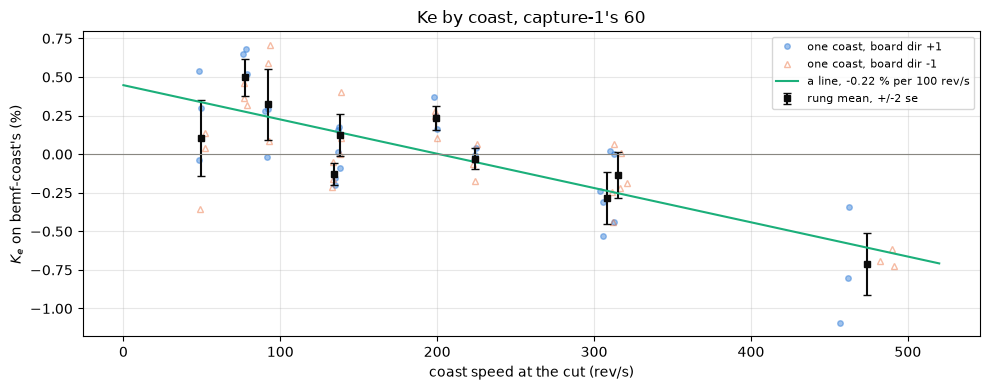

In [32]:
speeds = np.linspace(0, 520, 2)
fig, ax = plt.subplots(figsize=(10, 4))
for d in (1, -1):
    mine = K1[K1["dir"] == d]
    ax.plot(mine["coast_rev_s"], idn.pct(mine["ke"], idn.KE), ms=4,
            alpha=0.45, label=f"one coast, board dir {d:+d}",
            **figures.direction_style(d, MECH_COLOR[d]))
ax.errorbar(KE_RUNGS["rev_s"], KE_RUNGS["pct"], yerr=2 * KE_RUNGS["se_pct"],
            fmt="s", color=figures.INK, capsize=3, ms=5,
            label="rung mean, +/-2 se")
ax.plot(speeds, np.polyval(KE_LINE, speeds), color=figures.GREEN, lw=1.5,
        label=f"a line, {KE_LINE[0] * 100:+.2f} % per 100 rev/s")
ax.axhline(0, color=figures.MUTED, lw=0.8)
ax.legend(fontsize=8)
figures.label(ax, x="coast speed at the cut (rev/s)",
              y=r"$K_e$ on bemf-coast's (%)",
              title="Ke by coast, capture-1's 60")
figures.finish(fig)

One dot per coast, the black squares each rung's mean with $\pm$2 standard errors, and the green line through every coast. The thing to see is the slope. $K_e$ falls 0.22 % per 100 rev/s (bemf-coast reads 0.26), and 6 of the 10 rungs sit outside the $\pm$2 se flat band, from +0.50 % at 5 V 20 % (z +8.3) to -0.71 % at 7.4 V 60 % (z -7.1). So "$K_e$" is the mean over the speed range the reference used, and a read at one rung is biased by its speed, high confidence.

One repeat's 20 coasts read 1.16879, 1.16832 and 1.16802 mV s/rad. That is +0.035, -0.005 and -0.031 % on the reference, which contains them, and +0.053, -0.007 and -0.046 % held out on the other two repeats, with standard errors of 0.08 to 0.09 %.

### How many coasts

Fewer coasts cost less travel. Coasts drawn at random from one repeat, 4000 draws per repeat, and a few fixed designs, are each graded held out on the other two repeats.

In [33]:
# n coasts drawn at random from one repeat, every repeat, KE_DRAWS draws
# each, against the reference and held out on the other two repeats
rng = np.random.default_rng(KE_SEED)
draws = []
for n in KE_COAST_COUNTS:
    e_in, e_ho = [], []
    for rep in sorted(K1["repeat"].unique()):
        own = K1[K1["repeat"] == rep]["ke"].to_numpy()
        others = K1[K1["repeat"] != rep]["ke"].mean()
        for _ in range(KE_DRAWS if n < REPEAT_COASTS else 1):
            pick = rng.choice(len(own), n, replace=False)
            e_in.append(idn.pct(own[pick].mean(), idn.KE))
            e_ho.append(idn.pct(own[pick].mean(), others))
    e_in, e_ho = np.array(e_in), np.array(e_ho)
    draws.append(dict(n=n, rms_in=idn.rms(e_in), rms_ho=idn.rms(e_ho),
                      p95_ho=np.percentile(np.abs(e_ho), 95),
                      within_0p3=(np.abs(e_ho) <= KE_TOL_PCT).mean()))
COAST_DRAWS = pd.DataFrame(draws)
show(COAST_DRAWS, n=None)

,n,rms_in,rms_ho,p95_ho,within_0p3
0,1,0.371,0.373,0.705,0.628
1,2,0.256,0.258,0.491,0.743
2,3,0.202,0.204,0.393,0.862
3,4,0.169,0.172,0.334,0.923
4,6,0.133,0.136,0.265,0.975
5,8,0.107,0.111,0.216,0.994
6,10,0.089,0.094,0.183,1.000
7,14,0.062,0.069,0.136,1.000
8,20,0.027,0.041,0.053,1.000


A few fixed designs from one repeat, both directions of each named rung, held out on the other two repeats.

In [34]:
DESIGNS = {
    "7.4 V 40 % only": [(7.4, 40)], "5 V 30 % only": [(5.0, 30)],
    "5 V 15 % only": [(5.0, 15)], "7.4 V 60 % only": [(7.4, 60)],
    "5 V 20 + 7.4 V 30 + 7.4 V 60": [(5.0, 20), (7.4, 30), (7.4, 60)],
    "7.4 V 20, 30, 40, 60": [(7.4, 20), (7.4, 30), (7.4, 40), (7.4, 60)],
    "5 V 30, 40 + 7.4 V 30, 40": [(5.0, 30), (5.0, 40), (7.4, 30),
                                  (7.4, 40)],
    "the minimal V_b rungs, 7.4 V 30, 40, 60": idn.MIN_RUNGS}
rows = []
for name, cells in DESIGNS.items():
    row = dict(design=name, coasts=2 * len(cells))
    held_out = []
    for rep in sorted(K1["repeat"].unique()):
        own = K1[(K1["repeat"] == rep) & idn.in_rungs(K1, cells)]
        assert len(own) == 2 * len(cells)
        others = K1[K1["repeat"] != rep]["ke"].mean()
        held_out.append(idn.pct(own["ke"].mean(), others))
        row[f"held_out_{rep}_pct"] = held_out[-1]
        row[f"on_ref_{rep}_pct"] = idn.pct(own["ke"].mean(), idn.KE)
    row["held_out_mean_pct"] = np.mean(held_out)
    rows.append(row)
show(pd.DataFrame(rows), n=None)

,design,coasts,held_out_0_pct,on_ref_0_pct,held_out_1_pct,on_ref_1_pct,held_out_2_pct,on_ref_2_pct,held_out_mean_pct
0,7.4 V 40 % only,2,-0.262,-0.280,-0.090,-0.088,-0.500,-0.485,-0.284
1,5 V 30 % only,2,0.307,0.289,-0.045,-0.043,0.115,0.130,0.126
2,5 V 15 % only,2,0.355,0.337,-0.197,-0.195,0.153,0.168,0.104
3,7.4 V 60 % only,2,-0.744,-0.761,-0.480,-0.478,-0.906,-0.891,-0.710
4,5 V 20 + 7.4 V 30 + 7.4 V 60,6,-0.033,-0.050,-0.007,-0.005,-0.199,-0.184,-0.080
5,"7.4 V 20, 30, 40, 60",8,-0.275,-0.293,-0.172,-0.170,-0.416,-0.401,-0.288
6,"5 V 30, 40 + 7.4 V 30, 40",8,0.099,0.081,0.016,0.018,-0.079,-0.064,0.012
7,"the minimal V_b rungs, 7.4 V 30, 40, 60",6,-0.311,-0.329,-0.203,-0.201,-0.508,-0.493,-0.341


What one repeat's coasts cost as short spins.

In [35]:
# a Ke coast: the spin-up, the cut, 15 ms of coast, then a brake
KC = C1_COSTS.assign(short=C1_COSTS["revs95"] + C1_COSTS["c15"],
                     short_s=C1_COSTS["t95"] + COAST_S)
KE_COST = dict(spins=REPEAT_COASTS, revs=float(2 * KC["short"].sum()),
               seconds=float(2 * KC["short_s"].sum()),
               largest=float(KC["short"].max()))
bench = 2 * (KC["bench"] + KC["cstop"]).sum()
print(f"one repeat, both directions at every rung, as short spins: "
      f"{KE_COST['revs']:.0f} revs and {KE_COST['seconds']:.1f} s in 20 "
      f"maneuvers, the largest {KE_COST['largest']:.1f} revs; the bench "
      f"spins used {bench:.0f} revs")

one repeat, both directions at every rung, as short spins: 265 revs and 1.6 s in 20 maneuvers, the largest 31.4 revs; the bench spins used 6773 revs


The held-out error against the number of coasts drawn.

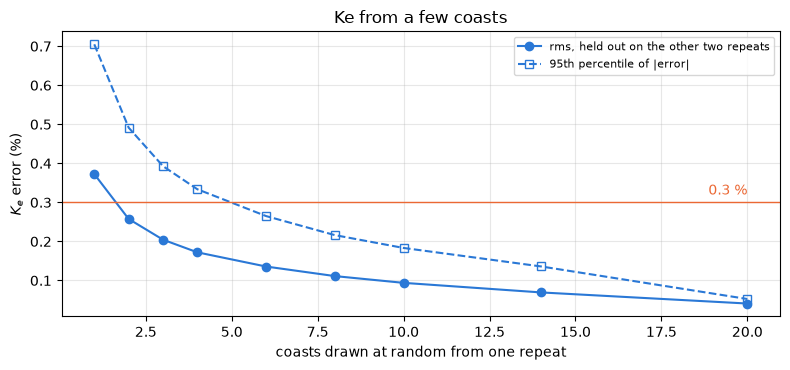

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(COAST_DRAWS["n"], COAST_DRAWS["rms_ho"], "o-", color=figures.BLUE,
        label="rms, held out on the other two repeats")
ax.plot(COAST_DRAWS["n"], COAST_DRAWS["p95_ho"], "s--", color=figures.BLUE,
        mfc="none", label="95th percentile of |error|")
ax.axhline(KE_TOL_PCT, color=figures.ORANGE, lw=1)
ax.text(20, 0.32, "0.3 %", color=figures.ORANGE, ha="right")
ax.legend(fontsize=8)
figures.label(ax, x="coasts drawn at random from one repeat",
              y=r"$K_e$ error (%)", title="Ke from a few coasts")
figures.finish(fig)

The rms and the 95th percentile of the held-out error against the number of coasts. The thing to see is where the curves cross 0.3 %. One coast carries 0.37 % rms, four 0.17 % with 92 % of draws within 0.3 %, and six 0.14 % with 98 % within. That holds only if the coasts span the speed range. 7.4 V 60 % alone reads -0.71 %, and the six coasts of the minimal $V_b$ rungs, 7.4 V 30, 40 and 60 %, read -0.20 to -0.49 % on the reference (-0.20 to -0.51 % held out).

A coast needs only the spin-up and 15 ms after the cut, 3 to 31 revs a maneuver, 265 revs and 1.6 s for all 20. The bench's 1.5 s spins used 6773 revs for the same 20.

## Route 4. L from one seat

inductance read the winding's $L$ at the twelve holes by two estimators. The period fit runs a one-pole model through each burst's periods. The ripple $L$ is the window's volts less $R\,i$ over the window's own current slope. A servo at its end stop could fire a few bursts. So the ident read is one seat, four bursts at 25 % forward with the group's first thrown out, graded against the 12-hole median of the same design. inductance's own cells run unchanged here.

In [37]:
# inductance's own cells, run unchanged in its folder: every burst's period
# fit and its ripple L
INN = idn.inductance_cells()
FITS, C2 = INN["FITS"], INN["C2"]
print(idn.kept("capture-1 bursts the summaries read (first of each group "
               "out, the excluded group out)", C2, ["pct", "sign"]))
for col in L_COLS:
    by_hole = C2.groupby("hole")[col].median().to_numpy()
    # the cells reproduce inductance's result
    assert np.allclose(by_hole, idn.IND[f"{col}_by_hole"], atol=2e-4)
L_REF = {col: idn.IND[col]["value"] for col in L_COLS}
print(f"inductance's result: period-fit L {L_REF['l_mh']:.4f} mH, ripple L "
      f"{L_REF['l_ripple_mh']:.4f} mH, reproduced by hole to 2e-4 mH; "
      f"motor-model's L0 at hole 11 {idn.MM['motor_l0_mh']['value']:.4f} mH")

[capture-1 bursts the summaries read (first of each group out, the excluded group out)] kept 214 rows: (25, -1):70, (25, 1):48, (40, -1):48, (40, 1):48
inductance's result: period-fit L 0.8333 mH, ripple L 0.6204 mH, reproduced by hole to 2e-4 mH; motor-model's L0 at hole 11 0.5048 mH


Burst to burst within a group, and the first burst of a group over its others, by the change before it.

In [38]:
first = FITS[(FITS["set"] == "capture-1") & ~FITS["excluded"]]
rows = []
for col in L_COLS:
    group = C2.groupby(["hole", "group"])[col]
    sd = group.std() / group.mean() * 100   # 4 bursts, the first out
    lead = first[first["first"]].set_index(["hole", "group"])[col]
    others = first[~first["first"]].groupby(["hole", "group"])[col].median()
    jump = (lead / others.reindex(lead.index) - 1) * 100
    row = dict(read=col, sd_median_pct=sd.median(), sd_lo_pct=sd.min(),
               sd_hi_pct=sd.max())
    for change in INN["CHANGE"]:
        row[f"first_{change}_pct"] = jump.xs(change, level="group").median()
    rows.append(row)
show(pd.DataFrame(rows).set_index("read").T, n=None)

read,l_mh,l_ripple_mh
sd_median_pct,0.709,1.180
sd_lo_pct,0.115,0.039
sd_hi_pct,1.688,3.530
first_g1-fwd-25_pct,7.709,1.261
first_g2-fwd-40_pct,-1.356,0.634
first_g3-rev-40_pct,11.095,1.714
first_g4-rev-25_pct,0.808,0.897
first_g5-rev-25-rested_pct,0.237,-0.418


One seat's L by each burst design, against the 12-hole median of the same design.

In [39]:
L_DESIGNS = {L_SEAT: ["g1-fwd-25"],
             "4 bursts, 40 % forward": ["g2-fwd-40"],
             "8 bursts, 25 and 40 % forward": ["g1-fwd-25", "g2-fwd-40"],
             "every burst at the seat (18)": list(INN["CHANGE"])}
LS, rows = {}, []
for col in L_COLS:
    for name, groups in L_DESIGNS.items():
        # one seat's read: the median of its bursts
        per = C2[C2["group"].isin(groups)].groupby("hole")[col].median()
        # against the 12-hole median of the same quantity and design
        err = pd.Series(idn.pct(per, per.median()), index=per.index)
        LS[(col, name)] = (per, err)
        rows.append(dict(read=col, design=name, median_mh=per.median(),
                         seat_sd_pct=err.std(), lo_pct=err.min(),
                         hi_pct=err.max(), hole_3_pct=err.loc[3],
                         hole_7_pct=err.loc[7], hole_11_pct=err.loc[11]))
show(pd.DataFrame(rows), n=None)
by_hole = C2.groupby("hole")[["l_mh", "l_ripple_mh"]].median()
ratio = by_hole["l_ripple_mh"] / by_hole["l_mh"]
print(f"ripple L over the period-fit L by hole: {ratio.min():.3f} to "
      f"{ratio.max():.3f}")

,read,design,median_mh,seat_sd_pct,lo_pct,hi_pct,hole_3_pct,hole_7_pct,hole_11_pct
0,l_mh,"4 bursts, 25 % forward",0.820,2.835,-5.923,2.266,-5.923,-4.313,-5.548
1,l_mh,"4 bursts, 40 % forward",0.884,2.975,-4.626,4.085,-4.463,-3.427,-4.626
2,l_mh,"8 bursts, 25 and 40 % forward",0.854,2.894,-5.201,3.348,-5.201,-4.473,-4.812
3,l_mh,every burst at the seat (18),0.829,2.717,-5.870,1.923,-5.870,-4.991,-4.676
4,l_ripple_mh,"4 bursts, 25 % forward",0.622,2.773,-3.736,5.364,0.550,-3.736,-1.384
5,l_ripple_mh,"4 bursts, 40 % forward",0.644,2.845,-5.011,3.663,0.911,-5.011,-3.376
6,l_ripple_mh,"8 bursts, 25 and 40 % forward",0.638,2.753,-4.884,3.568,0.895,-4.884,-3.242
7,l_ripple_mh,every burst at the seat (18),0.625,1.721,-3.744,2.255,-0.269,-3.744,-1.538


ripple L over the period-fit L by hole: 0.723 to 0.799


Each hole as the ident seat, by both estimators.

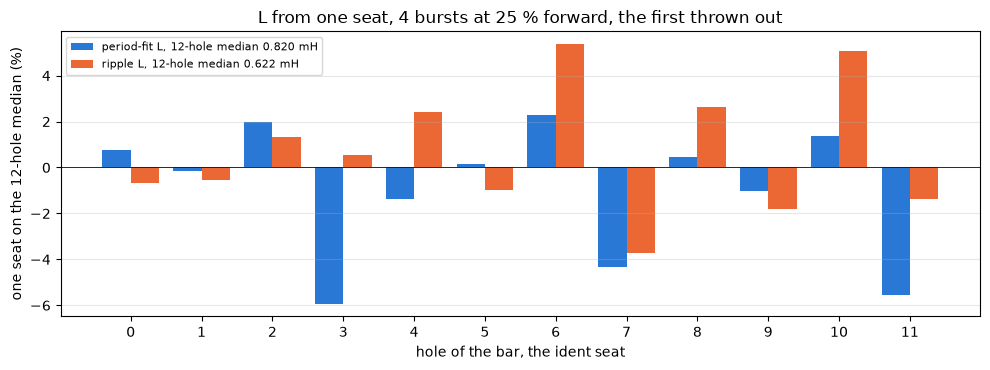

In [40]:
reads = (("l_mh", figures.BLUE, "period-fit L"),
         ("l_ripple_mh", figures.ORANGE, "ripple L"))
fig, ax = plt.subplots(figsize=(10, 3.8))
for j, (col, color, name) in enumerate(reads):
    per, err = LS[(col, L_SEAT)]
    ax.bar(per.index + (j - 0.5) * 0.4, err, 0.4, color=color,
           label=f"{name}, 12-hole median {per.median():.3f} mH")
ax.axhline(0, color=figures.INK, lw=0.6)
ax.set_xticks(range(12))
ax.legend(fontsize=8)
figures.label(ax, x="hole of the bar, the ident seat",
              y="one seat on the 12-hole median (%)",
              title="L from one seat, 4 bursts at 25 % forward, the first "
              "thrown out", grid=False)
ax.grid(alpha=figures.GRID_ALPHA, axis="y")
figures.finish(fig)

Each hole as the ident seat, period-fit $L$ in blue and ripple $L$ in orange. The thing to see is that one seat lands within a few percent, and three holes read low in the period fit and much less so in the ripple.

Within a seat, four bursts agree to 0.7 % in period-fit $L$ and 1.2 % in ripple $L$. One seat sits 2.8 % sd from the 12-hole median in either, 0.771 to 0.838 mH in period-fit $L$. Holes 3, 7 and 11 read -5.9, -4.3 and -5.5 % in period-fit $L$ at 25 %, and only +0.5, -3.7 and -1.4 % in ripple $L$. All 18 bursts at a seat bring ripple $L$ to 1.7 %. The first burst after a sign change reads +11.1 % in period-fit $L$ (+7.7 % after the bar's move) and only +1.7 % in ripple $L$, so a route that reads period-fit $L$ has to throw it away. Ripple $L$ over period-fit $L$ is 0.72 to 0.80 by hole. motor-model's $L_0$ at hole 11, 0.505 mH, is another model's small-current term and is not comparable to either.

A burst is about half a millisecond of drive at under 0.5 A, 150 ms apart, so five bursts take about 0.75 s locked and no travel. $L$ enters the estimate only as $L\,di/dt$ while the current moves, so its weight on the speed is the compensation notebook's test.

## Routes 5 and 7. c and Δ from the 100 % anchor

### c = J/(K_t K_e)

At 100 % nothing switches, so the crest sample is the mean current. At a speed-torque cut the drive's current pays for the rotor's acceleration and its drag. In the coast's first milliseconds the same drag alone slows the rotor. With the same drag on both sides,

$$i_{100} = c\,K_e\,(\alpha_\mathrm{drive} + \alpha_\mathrm{coast}), \qquad c = \frac{J}{K_t K_e}$$

with $\alpha_\mathrm{drive}$ the rise of the speed over the last 100 ms before the cut from speed-torque's own turn-window tach, and $\alpha_\mathrm{coast}$ the coast's deceleration at the cut. The coast has two reads of it, the 5 ms ripple windows and the speed drop pinned to the tach at the cut. At a partial-duty spin the mean current is then $c\,K_e\,(\alpha_\mathrm{coast} + \alpha_\mathrm{drive})$, the anchor, and $\Delta$ is the crest less it. $K_e$ and $J$ cancel in the anchor, so the route needs no constant but $c$. One pass reads $c$ from one run-up each way.

In [41]:
# c = J/(Kt Ke) at each speed-torque cut, from the 100 % run-up's last
# 100 ms and the coast's first milliseconds
REV = idn.runup_windows()[0]       # speed-torque's turn-window tach
ST = TB["speed-torque"].copy()
ST = ST.merge(idn.cut_slopes(REV, ST), on=["k", "dir"])
ST["i100"] = ST["i_crest_50"]      # nothing switches, so the crest is the
                                   # mean current
print(idn.kept("speed-torque cuts", ST, ["repeat", "dir"]))
C_REF = idn.J / idn.KE ** 2
CALL = idn.c_per_cut(ST)
show(ST[["k", "dir", "repeat"]].assign(c_win=CALL["win"] / C_REF,
                                       c_pin=CALL["pin"] / C_REF), n=None)
six = [f"{x} {CALL[x].mean() / C_REF:.4f}, sd "
       f"{CALL[x].std(ddof=1) / CALL[x].mean() * 100:.1f} %"
       for x in idn.ANCHOR_READS]
print(f"c per cut over J/(Kt Ke) = {C_REF:.5f} A s/V, all six: "
      + "; ".join(six))

[speed-torque cuts] kept 6 rows: (0, -1):1, (0, 1):1, (1, -1):1, (1, 1):1, (2, -1):1, (2, 1):1


,k,dir,repeat,c_win,c_pin
0,0,1,0,0.954,1.051
1,0,-1,0,0.981,1.004
2,1,1,1,1.021,1.013
3,1,-1,1,0.965,1.084
4,2,1,2,0.959,1.001
5,2,-1,2,0.973,0.962


c per cut over J/(Kt Ke) = 0.00458 A s/V, all six: win 0.9757, sd 2.5 %; pin 1.0190, sd 4.2 %


One ident pass reads c from one run-up each way.

In [42]:
CR, passes = {}, []
for rep in sorted(ST["repeat"].unique()):   # one run-up per direction
    one = (ST["repeat"] == rep).to_numpy()
    CR[rep] = {x: float(CALL[x][one].mean()) for x in idn.ANCHOR_READS}
    row = dict(rep=rep)
    for x in idn.ANCHOR_READS:
        row[f"c_{x}"] = CR[rep][x] / C_REF
        row[f"{x}_on_six_cuts_pct"] = (CR[rep][x] / CALL[x].mean() - 1) * 100
    passes.append(row)
show(pd.DataFrame(passes), n=None)
spread = []
for x in idn.ANCHOR_READS:
    v = np.array([CR[k][x] for k in CR]) / C_REF
    spread.append(f"{x} {v.min():.3f} to {v.max():.3f} x J/(Kt Ke), sd "
                  f"{v.std(ddof=1) * 100:.1f} %")
print("one pass spreads " + "; ".join(spread))

,rep,c_win,win_on_six_cuts_pct,c_pin,pin_on_six_cuts_pct
0,0,0.967,-0.847,1.028,0.846
1,1,0.993,1.801,1.048,2.863
2,2,0.966,-0.954,0.981,-3.710


one pass spreads win 0.966 to 0.993 x J/(Kt Ke), sd 1.5 %; pin 0.981 to 1.048 x J/(Kt Ke), sd 3.4 %


c read again a day later, at high-1's 100 % spins with the meter in series.

In [43]:
# the window read, 10-29, against 10-28's six cuts
slopes = SL[SL["run"] == "high-1"][["folder", "dir", "slope_200"]]
full_duty = TB["high-1"][TB["high-1"]["duty"] == 100]
h1 = full_duty.merge(slopes, on=["folder", "dir"], how="left")
alpha = (idn.alpha_reads(h1)["win"]
         + 2 * np.pi * h1["slope_200"].fillna(0.0))
c_meter = h1["meter_ma"] * 1e-3 / (idn.KE * alpha)
C_1029 = (c_meter.mean() / C_REF,
          c_meter.std() / np.sqrt(len(c_meter)) / C_REF)
# the six cuts' standard error
C_SE = CALL["win"].std(ddof=1) / np.sqrt(len(CALL["win"])) / C_REF
c_1028 = CALL["win"].mean() / C_REF
print(f"c on 10-29 at high-1's 100 % spins, by the meter, window read: "
      f"{C_1029[0]:.3f} x J/(Kt Ke) (se {C_1029[1]:.3f}, {len(c_meter)} "
      f"spins) against 10-28's {c_1028:.3f} (se {C_SE:.3f}), "
      f"{(C_1029[0] / c_1028 - 1) * 100:+.2f} +/- "
      f"{np.hypot(C_1029[1], C_SE) * 100:.1f} %")

c on 10-29 at high-1's 100 % spins, by the meter, window read: 0.958 x J/(Kt Ke) (se 0.023, 6 spins) against 10-28's 0.976 (se 0.010), -1.87 +/- 2.5 %


By the 5 ms windows, $c$ over the six cuts is 0.976 x $J/(K_t K_e)$ with an sd of 2.5 % a cut, and by the pinned read 1.019 with 4.2 %. One run-up each way gives 0.967, 0.993 and 0.966 by the windows, -3.4 to -0.7 % on $J/(K_t K_e)$ with an sd of 1.5 %, and 1.028, 1.048 and 0.981 by the pinned read, -1.9 to +4.8 % with an sd of 3.4 %. Read again a day later at high-1's 100 % spins with the meter in series, $c$ by the windows is 0.958, -1.9 $\pm$ 2.5 % on the first day's six cuts. So $c$ carries over a day within its error, moderate confidence, from one point of six spins.

### The Δ table

Each pass's $c$ with the same repeat's 20 spins gives $\Delta$ per spin, the crest less the anchor. The anchor uses the pinned read under 300 rev/s and the windows over it, each with its own $c$. The table is $f(D) = \Delta / V_\mathrm{window}$ per duty, held flat below the lowest duty and zero at 100 %, the same form as the published grid. The reference is motor-model's published no-meter grid per volt, the mean over its four rails. The anchor is also graded against the DMM on the meter runs, read the day after $c$.

In [44]:
# the Delta table per ident pass: the crest less the anchor per spin,
# f(D) = Delta / v_on per duty, from one repeat and one pass's c
assert idn.tach_gate(TB["capture-1"])[0].all()
C1_RAW = TB["capture-1"].copy()
C_SIX = {x: CALL[x].mean() for x in idn.ANCHOR_READS}
FT_ALL, F_ALL = idn.f_from(idn.anchor_delta(C1_RAW, C_SIX, SL, "capture-1"))
print("f(D) mA/V, the published grid: " + ", ".join(
    f"{d:g} {v:.3f}" for d, v in zip(*FT_PUB) if 0 < d < 100))
print("f(D) mA/V by the anchor, all three repeats and six cuts: "
      + ", ".join(f"{d} {v:.3f}" for d, v in F_ALL.items()))

f(D) mA/V, the published grid: 10 3.685, 15 3.812, 20 3.892, 30 3.898, 40 3.699, 50 3.323, 60 2.807, 70 2.194, 80 1.525, 90 0.834
f(D) mA/V by the anchor, all three repeats and six cuts: 15 3.614, 20 3.735, 30 3.508, 40 3.519, 60 2.671


Each pass's table over 200 and 50 ms windows, and over the minimal rungs alone.

In [45]:
TABS, TABS50, F50, TABSMIN = {}, {}, {}, {}
per_pass = []
for rep in sorted(C1_RAW["repeat"].unique()):
    spins = C1_RAW[C1_RAW["repeat"] == rep]
    T = idn.anchor_delta(spins.copy(), CR[rep], SL, "capture-1")
    TABS[rep], f = idn.f_from(T)
    # a short spin's 50 ms window
    T50 = idn.anchor_delta(spins.copy(), CR[rep], SL, "capture-1",
                           pre=SHORT_MS)
    TABS50[rep], F50[rep] = idn.f_from(T50)
    TABSMIN[rep], f_min = idn.f_from(T50[idn.in_rungs(T50, idn.MIN_RUNGS)])
    pub = np.interp(f.index.to_numpy(float), *FT_PUB)
    on_grid = pd.Series((f.to_numpy() / pub - 1) * 100, index=f.index)
    per_pass.append(pd.DataFrame({"pass": rep, "f_200": f,
                                  "on_grid_pct": on_grid, "f_50": F50[rep],
                                  "f_minimal": f_min}))
show(pd.concat(per_pass), n=None)

,pass,f_200,on_grid_pct,f_50,f_minimal
duty,,,,,
15,0,3.483,-8.633,3.479,NaN
20,0,3.577,-8.105,3.620,NaN
30,0,3.254,-16.527,3.296,3.382
40,0,3.416,-7.661,3.313,3.912
60,0,2.674,-4.764,2.585,2.459
15,1,3.468,-9.027,3.464,NaN
20,1,3.497,-10.159,3.475,NaN
30,1,3.331,-14.550,3.306,3.539
40,1,3.257,-11.951,3.338,4.043


Each table at capture-1's rungs, each rung at its own window volts, less the published grid, in mA.

In [46]:
rung_v = C1_RAW.groupby(["level", "duty"])["v_on_200"].mean()
tables = [(f"{k}", v) for k, v in TABS.items()]
tables += [(f"{k} (50 ms)", v) for k, v in TABS50.items()]
tables += [(f"{k} (minimal)", v) for k, v in TABSMIN.items()]
tables += [("all", FT_ALL)]
DG, rows = {}, []
for name, table in tables:
    offsets = []
    for (lv, du), v in rung_v.items():    # at each rung's own v_on
        offsets.append((np.interp(du, *table) - np.interp(du, *FT_PUB)) * v)
    e = np.array(offsets)
    DG[name] = e
    row = {"pass": name}
    for (lv, du), x in zip(rung_v.index, e):
        row[f"{lv:g}/{du}"] = x
    row.update(mean_ma=e.mean(), rms_ma=idn.rms(e))
    rows.append(row)
show(pd.DataFrame(rows), n=None)

,pass,5/15,5/20,5/30,5/40,5/60,7.4/15,7.4/20,7.4/30,7.4/40,7.4/60,mean_ma,rms_ma
0,0,-1.624,-1.555,-3.167,-1.391,-0.656,-2.406,-2.304,-4.698,-2.065,-0.974,-2.084,2.363
1,1,-1.698,-1.948,-2.788,-2.170,-1.036,-2.516,-2.887,-4.136,-3.222,-1.538,-2.394,2.545
2,2,0.391,1.184,0.181,0.882,-0.291,0.580,1.755,0.268,1.309,-0.433,0.583,0.885
3,0 (50 ms),-1.640,-1.343,-2.958,-1.897,-1.088,-2.430,-1.990,-4.389,-2.816,-1.615,-2.217,2.402
4,1 (50 ms),-1.716,-2.057,-2.912,-1.774,-0.697,-2.542,-3.048,-4.320,-2.633,-1.036,-2.273,2.484
5,2 (50 ms),0.456,1.542,0.334,0.852,-0.736,0.675,2.285,0.496,1.264,-1.092,0.608,1.126
6,0 (minimal),-2.119,-2.515,-2.536,1.048,-1.708,-3.140,-3.727,-3.762,1.556,-2.536,-1.944,2.608
7,1 (minimal),-1.344,-1.740,-1.763,1.688,-0.512,-1.991,-2.579,-2.616,2.505,-0.760,-0.911,1.880
8,2 (minimal),1.133,0.733,0.704,1.027,1.261,1.678,1.086,1.044,1.525,1.873,1.206,1.260
9,all,-0.975,-0.775,-1.919,-0.884,-0.667,-1.445,-1.149,-2.846,-1.313,-0.990,-1.296,1.438


Each pass's anchor over the DMM on the meter runs, with c from the day before.

In [47]:
DD, rows = {}, []
for rep in list(CR) + ["all"]:
    c_pass = CR[rep] if rep != "all" else C_SIX
    ratios = []
    for run in ("meter-1", "high-1"):
        T = idn.anchor_delta(TB[run].copy(), c_pass, SL, run)
        T = T[T["duty"] < 100]
        ratios.append(T["anchor"] / T["meter_ma"])
    ratios = pd.concat(ratios)
    DD[rep] = (ratios.mean(), ratios.std() / np.sqrt(len(ratios)))
    rows.append({"pass": rep, "over_dmm": DD[rep][0], "se": DD[rep][1],
                 "n": len(ratios)})
show(pd.DataFrame(rows), n=None)

,pass,over_dmm,se,n
0,0,1.045,0.006,30
1,1,1.068,0.006,30
2,2,1.007,0.005,30
3,all,1.040,0.005,30


The pass-to-pass move against the spread of one pass's pinned c.

In [48]:
d50 = np.array([DG[f"{k} (50 ms)"].mean() for k in CR])
an_all = idn.anchor_delta(C1_RAW, C_SIX, SL, "capture-1")["anchor"]
# one pass's c by the pinned read, the sd over the three passes
pin_sd = np.std([CR[k]["pin"] for k in CR], ddof=1) / C_REF
print(f"the 50 ms passes' mean offsets on the grid move {np.ptp(d50):.1f} "
      f"mA pass to pass; the anchor at capture-1's spins is "
      f"{an_all.min():.0f} to {an_all.max():.0f} mA, so the pinned c's "
      f"one-pass sd of {pin_sd * 100:.1f} % is {an_all.min() * pin_sd:.1f} "
      f"to {an_all.max() * pin_sd:.1f} mA")

the 50 ms passes' mean offsets on the grid move 2.9 mA pass to pass; the anchor at capture-1's spins is 48 to 100 mA, so the pinned c's one-pass sd of 3.4 % is 1.7 to 3.4 mA


The reading term per volt by the anchor, against the published grid.

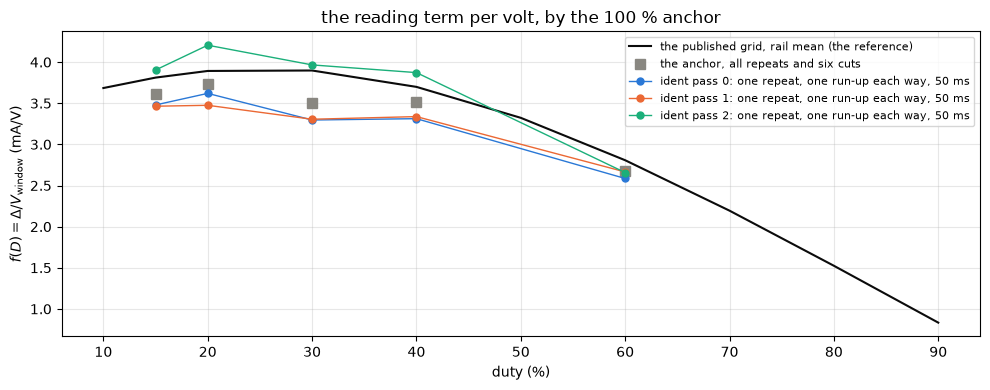

In [49]:
duties = np.array(sorted(F_ALL.index))
pass_colors = (figures.BLUE, figures.ORANGE, figures.GREEN)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(FT_PUB[0][1:-1], FT_PUB[1][1:-1], "-", color=figures.INK, lw=1.5,
        label="the published grid, rail mean (the reference)")
ax.plot(duties, F_ALL.to_numpy(), "s", color=figures.MUTED, ms=7,
        label="the anchor, all repeats and six cuts")
for rep, color in zip(sorted(F50), pass_colors):
    ax.plot(F50[rep].index, F50[rep].to_numpy(), "o-", color=color, ms=5,
            lw=1, label=f"ident pass {rep}: one repeat, one run-up each "
            f"way, 50 ms")
ax.legend(fontsize=8)
figures.label(ax, x="duty (%)",
              y=r"$f(D) = \Delta / V_\mathrm{window}$ (mA/V)",
              title="the reading term per volt, by the 100 % anchor")
figures.finish(fig)

The black line is the published grid, the gray squares the anchor over every cut and repeat, and the colored lines the three passes over 50 ms windows. The thing to see is that pass 2 sits above the grid and passes 0 and 1 below it, by about the same amount at every duty.

Over 50 ms windows the passes read 3.30 to 4.21 mA/V at 15 to 40 % and 2.59 to 2.67 at 60 %. At capture-1's rungs, each at its own window volts, they read -2.2, -2.3 and +0.6 mA on the grid in the mean, and -2.1, -2.4 and +0.6 mA over 200 ms. Every cut and repeat together reads -1.3 mA. The worst rung of a pass is 7.4 V 30 % at -4.7 mA. Against the DMM the day after, each pass's anchor reads 1.045, 1.068 and 1.007 of the meter, se about 0.006, and every cut together 1.040.

The passes move 2.9 mA from one to the next, and that is the spread of $c$. One pass's $c$ by the pinned read spreads 3.4 %, which is 1.7 to 3.4 mA on capture-1's anchor of 48 to 100 mA, and the pass offsets sit within about one sigma of it. So one run-up each way is too few for $\Delta$ to 1 mA, moderate confidence.

### The run-up's cost

The anchor's run-up is the costliest maneuver of a pass. Its revolutions come from speed-torque's turn-window tach integrated from rest.

In [50]:
# the anchor run-up's cost: speed-torque's turn-window tach integrated
# from rest, motor revs by time into the 100 % run-up at 5.0 V
rows = []
for (k, d), h in REV.groupby(["k", "dir"]):
    h = h.sort_values("t")
    t = np.r_[0.0, h["t"].to_numpy()]
    w = np.r_[0.0, h["rev_s"].to_numpy()]
    revs = np.r_[0.0, np.cumsum(np.diff(t) * (w[1:] + w[:-1]) / 2)]
    row = dict(k=k, dir=d, t=t, revs=revs)
    for T in RUNUP_MARKS_S:
        row[f"revs_{int(T * 1e3)}ms"] = float(np.interp(T, t, revs))
    rows.append(row)
RUNUP_REVS = pd.DataFrame(rows)
marks = RUNUP_REVS[["k", "dir", "revs_250ms", "revs_300ms"]]
RUNUP_COSTS = COSTS[COSTS["run"] == "speed-torque"].merge(marks,
                                                          on=["k", "dir"])
# the coast's first 15 ms, the mean over the six run-ups
C15 = RUNUP_COSTS["coast_revs_15ms"].mean()
# the bench run-up and 15 ms of coast before a brake
RUNUP_COSTS["with_coast_300"] = RUNUP_COSTS["revs_300ms"] + C15
RUNUP_COSTS["with_coast_250"] = RUNUP_COSTS["revs_250ms"] + C15
# the same with each run-up's own coast
RUNUP_COSTS["own_coast_300"] = (RUNUP_COSTS["revs_300ms"]
                                + RUNUP_COSTS["coast_revs_15ms"])
show(RUNUP_REVS.drop(columns=["t", "revs"]), n=None)
show(RUNUP_COSTS[["k", "dir", "own_coast_300"]], n=None)
c300, c250 = RUNUP_COSTS["with_coast_300"], RUNUP_COSTS["with_coast_250"]
free = RUNUP_REVS["revs_300ms"].mean() + RUNUP_COSTS["coast_revs"].mean()
print(f"the coast: {C15:.1f} revs in its first 15 ms, "
      f"{RUNUP_COSTS['coast_revs'].mean():.1f} revs to the stop "
      f"({RUNUP_COSTS['coast_stop_s'].mean() * 1e3:.0f} ms)")
print(f"a 300 ms run-up with 15 ms of coast: {c300.min():.1f} to "
      f"{c300.max():.1f} revs; with the free coast {free:.0f}; a 250 ms "
      f"run-up with 15 ms of coast {c250.min():.1f} to {c250.max():.1f} "
      f"revs; the travel {idn.TRAVEL_REVS:.1f} revs")

,k,dir,revs_100ms,revs_150ms,revs_200ms,revs_250ms,revs_300ms
0,0,-1,45.068,72.879,100.774,128.751,155.779
1,0,1,43.332,70.047,96.898,123.832,150.055
2,1,-1,44.922,72.649,100.482,128.381,155.293
3,1,1,43.248,69.821,96.664,123.747,150.048
4,2,-1,44.942,72.594,100.379,128.256,155.274
5,2,1,43.240,69.912,96.671,123.520,149.854


,k,dir,own_coast_300
0,0,1,157.448
1,0,-1,163.414
2,1,1,157.447
3,1,-1,162.908
4,2,1,157.213
5,2,-1,162.855


the coast: 7.5 revs in its first 15 ms, 58.6 revs to the stop (262 ms)
a 300 ms run-up with 15 ms of coast: 157.4 to 163.3 revs; with the free coast 211; a 250 ms run-up with 15 ms of coast 131.0 to 136.2 revs; the travel 157.4 revs


The six run-ups' revolutions against time, with the travel.

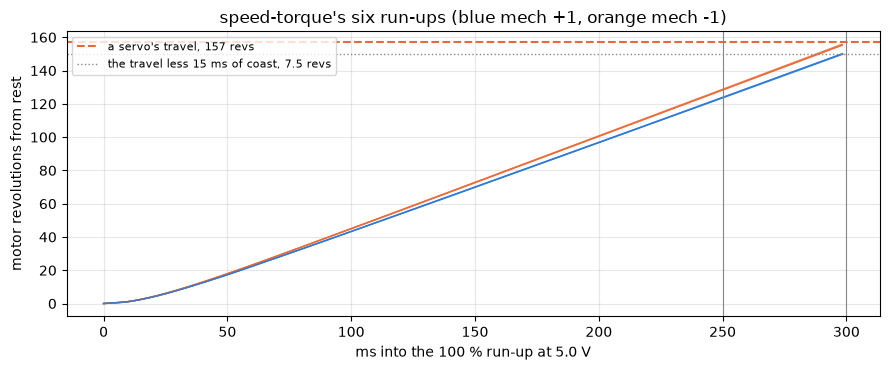

In [51]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for _, run_up in RUNUP_REVS.iterrows():
    mech = int(run_up["dir"]) * idn.MECH["speed-torque"]
    ax.plot(run_up["t"] * 1e3, run_up["revs"], color=MECH_COLOR[mech], lw=1,
            alpha=0.8)
ax.axhline(idn.TRAVEL_REVS, color=figures.ORANGE, lw=1.5, ls="--",
           label=f"a servo's travel, {idn.TRAVEL_REVS:.0f} revs")
ax.axhline(idn.TRAVEL_REVS - C15, color=figures.MUTED, lw=1, ls=":",
           label=f"the travel less 15 ms of coast, {C15:.1f} revs")
for cut_ms in (250, 300):
    ax.axvline(cut_ms, color=figures.MUTED, lw=0.8)
ax.legend(fontsize=8, loc="upper left")
figures.label(ax, x="ms into the 100 % run-up at 5.0 V",
              y="motor revolutions from rest",
              title="speed-torque's six run-ups (blue mech +1, orange mech "
              "-1)")
figures.finish(fig)

The six run-ups against time, the travel dashed and the travel less the coast's first 15 ms dotted, with the 250 and 300 ms cuts marked. The thing to see is that the 300 ms run-up reaches the dotted line.

At 100 % on 5.0 V the run-up covers 43 to 45 revs by 100 ms, 97 to 101 by 200 ms, 124 to 129 by 250 ms and 150 to 156 by 300 ms, and the coast's first 15 ms add 7.5 revs. So the bench's 300 ms run-up with 15 ms of coast comes to 157.4 to 163.3 revs against 157.4 of travel, at the limit in mech +1 and over it in mech -1, and with its free coast 211. A 250 ms run-up braked after 15 ms of coast fits at 131 to 136 revs. Every $c$ here was read at 300 ms, so whether $c$ holds at 250 ms is not tested.

## Route 6. V_b by mechanical direction

$V_b$ is what the terminal volts carry beyond the EMF and the copper's drop, $X = V_\mathrm{mean} - K_e\,\omega - R\,\hat i$, with $\omega$ the ripple tach and $\hat i$ the crest less $\Delta$. The EMF is the estimator's own $K_e$ at the tach's speed rather than the coast's $E_0$, so whatever $K_e$ does with speed (route 3's -0.22 % per 100 rev/s) lands in $X$ and the estimator inherits none of it. The reference $R$, $K_e$ and $\Delta$ go in, so only the $V_b$ read varies.

$X$ is read as two parts. The spins whose current drops out, rows of the window under a quarter of its mean, carry more of it, and in proportion, so the first part is $k_d$ times the dropout rate, one coefficient fitted over every spin with one level per rung shared by both directions, which reads $k_d$ from the direction split at one speed and from the spin-to-spin spread inside a rung. The rest is a speed table per mechanical direction, the rung means of $X - k_d\,\dot n_d$ at 50 rev/s knots from 150 to 650 rev/s, extrapolated past the top rung by its last segment. Its value at and below 150 rev/s is the low rungs' mean when the two rails agree and zero when they split, since a term that follows the rail is the construction's and not the motor's. The dropout rate is the board's own count, so the table needs the leads' orientation for its speed part alone. Both forms, with $k_d$ and with it held at zero, are kept, and the compensation notebook scores them.

The quarter is one fixed fraction, `oscnb.tel.DROPOUT_FRAC`, that every notebook and the board count by, since $k_d$ means something only against one definition of a dropout. Whether it sits in a gap on this motor is checked first, from the rows of every window by their crest over the window mean.

The reference fit is capture-1's full data, all three repeats over 200 ms windows. Each subset is one repeat's rungs both ways, three passes. The fewest rungs that hold, by a rule on held-out speed scores set before running, are 7.4 V at 30, 40 and 60 %. That speed test belongs to the compensation notebook. Here each subset is graded as a constant, its table and its $k_d$ against the full-data fit, with its cost.


In [52]:
# V_b tables with reference R, Ke and Delta, so only the V_b ident varies:
# the full-data table against one repeat's subsets
SEP = idn.dropout_separation(C1)
VB_FULL = idn.vb_fit(C1, FT_PUB)     # all three repeats, 200 ms, the
                                     # reference fit
VB_FULL_S = idn.vb_fit(C1, FT_PUB, dropouts=False)   # k_d held at 0, the
                                                     # speed-only table
floors = ", ".join(f"{lv:g} V {x:+.1f} +/- {s:.1f} mV"
                   for lv, (x, s) in VB_FULL["floor_by_rail"].items())
print(f"the dropout threshold, {SEP['threshold']:.2f} of the window mean: "
      f"capture-1's rows under 0.10 {SEP['rows_under_0p10']}, 0.10 to the "
      f"threshold {SEP['rows_0p10_to_thr']}, the threshold to 0.40 "
      f"{SEP['rows_thr_to_0p40']}, 0.40 to 0.60 {SEP['rows_0p40_to_0p60']}; "
      f"the two bands around the threshold hold "
      f"{SEP['ambiguous_share'] * 100:.0f} % of the rows under 0.40")
print(f"k_d {VB_FULL['k_d']:.3f} +/- {VB_FULL['k_d_se']:.3f} mV per "
      f"dropout/s over {VB_FULL['k_d_dof']} dof; the floor under "
      f"{idn.LOW_SPEED:.0f} rev/s: {floors}, split "
      f"{VB_FULL['floor_split_se']:.1f} se, so the floor is "
      f"{VB_FULL['floor']:.0f} mV")

the dropout threshold, 0.25 of the window mean: capture-1's rows under 0.10 513, 0.10 to the threshold 41, the threshold to 0.40 238, 0.40 to 0.60 980; the two bands around the threshold hold 35 % of the rows under 0.40
k_d 0.524 +/- 0.026 mV per dropout/s over 49 dof; the floor under 160 rev/s: 5 V -4.2 +/- 0.6 mV, 7.4 V -22.2 +/- 0.6 mV, split 20.4 se, so the floor is 0 mV


The full-data tables by knot, mV, and the scatter of the three single-repeat tables.

In [53]:
ONE = {rep: idn.vb_fit(C1[C1["repeat"] == rep], FT_PUB) for rep in REPEATS}
tables = {}
for m in (1, -1):
    tables[f"mech {m:+d}, speed part with k_d"] = VB_FULL[m]["table"]
    tables[f"mech {m:+d}, speed only"] = VB_FULL_S[m]["table"]
    singles = np.array([ONE[rep][m]["table"] for rep in REPEATS])
    tables[f"mech {m:+d}, single-repeat sd"] = singles.std(axis=0, ddof=1)
knots = [f"{k:.0f} rev/s" for k in idn.VB_KNOTS]
show(pd.DataFrame(tables, index=knots).T, n=None)

,150 rev/s,200 rev/s,250 rev/s,300 rev/s,350 rev/s,400 rev/s,450 rev/s,500 rev/s,550 rev/s,600 rev/s,650 rev/s
"mech +1, speed part with k_d",0.000,18.497,17.022,26.670,52.785,57.536,62.288,67.039,71.790,76.541,81.293
"mech +1, speed only",0.000,18.497,26.684,80.201,139.506,208.719,277.933,347.147,416.360,485.574,554.787
"mech +1, single-repeat sd",0.000,1.673,3.961,18.291,8.187,4.550,14.015,24.376,34.842,45.341,55.854
"mech -1, speed part with k_d",0.000,10.712,6.125,15.873,47.692,50.832,53.972,57.113,60.253,63.393,66.534
"mech -1, speed only",0.000,10.712,6.125,15.873,56.141,88.387,120.633,152.878,185.124,217.369,249.615
"mech -1, single-repeat sd",0.000,4.016,6.644,4.899,4.876,5.289,6.690,8.609,10.774,13.063,15.420


The rung subsets graded, each read from one repeat's rungs both ways.

In [54]:
SUBSETS = {
    "all 10 rungs": [(5.0, 15), (5.0, 20), (5.0, 30), (5.0, 40), (5.0, 60),
                     (7.4, 15), (7.4, 20), (7.4, 30), (7.4, 40), (7.4, 60)],
    "7 rungs over 145 rev/s": [(5.0, 30), (5.0, 40), (5.0, 60), (7.4, 20),
                               (7.4, 30), (7.4, 40), (7.4, 60)],
    "5 V 30/40/60 + 7.4 V 40/60": [(5.0, 30), (5.0, 40), (5.0, 60),
                                   (7.4, 40), (7.4, 60)],
    "7.4 V only, 5 rungs": [(7.4, 15), (7.4, 20), (7.4, 30), (7.4, 40),
                            (7.4, 60)],
    "7.4 V 20/30/40/60": [(7.4, 20), (7.4, 30), (7.4, 40), (7.4, 60)],
    "7.4 V 30/40/60": idn.MIN_RUNGS,
    "5 V 40 + 7.4 V 30/60": [(5.0, 40), (7.4, 30), (7.4, 60)],
    "7.4 V 40/60": [(7.4, 40), (7.4, 60)],
    "7.4 V 60 only": [(7.4, 60)],
    "5 V only, 5 rungs": [(5.0, 15), (5.0, 20), (5.0, 30), (5.0, 40),
                          (5.0, 60)],
}
MIN_SUBSET = "7.4 V 30/40/60"     # the fewest rungs that hold

Every subset fitted from each repeat, its table graded against the full-data table and its k_d beside it.

In [55]:
GRADED_KNOTS = (idn.VB_KNOTS >= KNOTS_LO) & (idn.VB_KNOTS <= KNOTS_HI)
grades, VB_MIN = [], {}
for pre in WINDOWS_MS:
    for name, cells in SUBSETS.items():
        for rep in REPEATS:
            in_set = (C1["repeat"] == rep) & idn.in_rungs(C1, cells)
            spins = C1[in_set]
            assert len(spins) == 2 * len(cells)
            fit = idn.vb_fit(spins, FT_PUB, pre=pre)
            if name == MIN_SUBSET:
                VB_MIN[(pre, rep)] = fit
            for m in (1, -1):
                d = fit[m]["table"] - VB_FULL[m]["table"]
                grades.append(dict(
                    pre=pre, subset=name, rep=rep, mech=m,
                    rms_mv=idn.rms(d[GRADED_KNOTS]),
                    max_mv=np.abs(d[GRADED_KNOTS]).max(),
                    at_550=d[idn.VB_KNOTS == KNOT_FAR][0], k_d=fit["k_d"],
                    k_d_se=fit["k_d_se"]))
KR = pd.DataFrame(grades)
KM = KR.groupby(["pre", "subset", "mech"], sort=False).agg(
    rms_mv=("rms_mv", "median"), max_mv=("max_mv", "median"),
    at_550=("at_550", "median")).reset_index()
KD = KR[KR["mech"] == 1].groupby(["pre", "subset"], sort=False)["k_d"]
KD = KD.agg(["median", "min", "max"])
print(f"k_d by subset, median and range over the 3 passes, mV per "
      f"dropout/s, against the full-data {VB_FULL['k_d']:.3f}:")
show(KD, n=None)

k_d by subset, median and range over the 3 passes, mV per dropout/s, against the full-data 0.524:


median   min   max
pre subset                                        
200 all 10 rungs                 0.538 0.494 0.619
    7 rungs over 145 rev/s       0.538 0.494 0.619
    5 V 30/40/60 + 7.4 V 40/60   0.538 0.494 0.619
    7.4 V only, 5 rungs          0.530 0.493 0.658
    7.4 V 20/30/40/60            0.530 0.493 0.658
    7.4 V 30/40/60               0.530 0.493 0.658
    5 V 40 + 7.4 V 30/60         0.529 0.462 0.710
    7.4 V 40/60                  0.530 0.493 0.658
    7.4 V 60 only                0.529 0.462 0.710
    5 V only, 5 rungs            0.508 0.508 0.779
50  all 10 rungs                 0.506 0.411 0.620
    7 rungs over 145 rev/s       0.506 0.411 0.620
    5 V 30/40/60 + 7.4 V 40/60   0.506 0.411 0.620
    7.4 V only, 5 rungs          0.505 0.416 0.804
    7.4 V 20/30/40/60            0.505 0.416 0.804
    7.4 V 30/40/60               0.505 0.416 0.804
    5 V 40 + 7.4 V 30/60         0.500 0.386 0.957
    7.4 V 40/60                  0.505 0.416 0.804
    7.4 V 60 only                0.500 0.386 0.957
    5 V only, 5 rungs            0.412 0.378 0.517

Each subset's table less the full-data table, the median over the three passes in mV, rms and max over the 200 to 500 rev/s knots and at 550, with its cost as short spins.

In [56]:
# the cost: the spin-up to 95 %, the window, 15 ms of coast, both ways
rows = []
for pre in WINDOWS_MS:
    for name, cells in SUBSETS.items():
        cs = C1_COSTS.loc[cells]
        per_spin = cs["revs95"] + cs["rev_s"] * pre / 1e3 + cs["c15"]
        grade = KM[(KM["pre"] == pre) & (KM["subset"] == name)]
        grade = grade.set_index("mech")
        row = dict(pre=pre, subset=name)
        for m in (1, -1):
            for col in ("rms_mv", "max_mv", "at_550"):
                row[f"{col} {m:+d}"] = grade.loc[m, col]
        row.update(spins=2 * len(cells), revs=2 * per_spin.sum(),
                   largest=per_spin.max(),
                   seconds=2 * (cs["t95"] + pre / 1e3 + COAST_S).sum())
        rows.append(row)
show(pd.DataFrame(rows), n=None)

,pre,subset,rms_mv +1,max_mv +1,at_550 +1,rms_mv -1,max_mv -1,at_550 -1,spins,revs,largest,seconds
0,200,all 10 rungs,12.414,18.601,-22.371,3.979,7.163,-2.591,20,1142.258,136.459,5.603
1,200,7 rungs over 145 rev/s,12.414,18.601,-22.371,3.979,7.163,-2.591,14,1015.522,136.459,3.947
2,200,5 V 30/40/60 + 7.4 V 40/60,14.055,21.936,-22.371,5.109,11.126,-2.591,10,817.048,136.459,2.823
3,200,"7.4 V only, 5 rungs",20.291,28.617,-17.702,14.130,25.057,-3.045,10,694.930,136.459,2.807
4,200,7.4 V 20/30/40/60,20.291,28.617,-17.702,14.130,25.057,-3.045,8,644.463,136.459,2.253
5,200,7.4 V 30/40/60,19.221,28.617,-17.702,13.705,25.057,-3.045,6,571.030,136.459,1.699
6,200,5 V 40 + 7.4 V 30/60,18.113,26.239,-18.724,18.190,28.457,-9.194,6,511.056,136.459,1.702
7,200,7.4 V 40/60,22.729,36.665,-17.702,14.799,25.057,-3.045,4,445.989,136.459,1.129
8,200,7.4 V 60 only,20.478,28.339,-27.905,22.836,37.760,-16.368,2,272.919,136.459,0.563
9,200,"5 V only, 5 rungs",7.757,14.324,14.638,18.697,35.444,47.107,10,447.328,90.370,2.796


What the minimal set and the pass's 20 spins cost with 50 ms windows.

In [57]:
cs = C1_COSTS.loc[idn.MIN_RUNGS]
ps = cs["revs95"] + cs["rev_s"] * WINDOW_S + cs["c15"]
VB_COST = dict(spins=2 * len(idn.MIN_RUNGS), revs=float(2 * ps.sum()),
               largest=float(ps.max()),
               seconds=float(2 * (cs["t95"] + WINDOW_S + COAST_S).sum()))
ALL_COST = (C1_COSTS["revs95"] + C1_COSTS["rev_s"] * WINDOW_S
            + C1_COSTS["c15"])
PASS_SPINS = dict(spins=2 * len(C1_COSTS), revs=float(2 * ALL_COST.sum()),
                  largest=float(ALL_COST.max()),
                  seconds=float(2 * (C1_COSTS["t95"] + WINDOW_S
                                     + COAST_S).sum()))
print(f"the minimal set: {VB_COST['spins']} spins, {VB_COST['revs']:.0f} "
      f"revs, the largest {VB_COST['largest']:.0f}, "
      f"{VB_COST['seconds']:.1f} s; the pass's {PASS_SPINS['spins']} "
      f"spins: {PASS_SPINS['revs']:.0f} revs, the largest "
      f"{PASS_SPINS['largest']:.0f}, {PASS_SPINS['seconds']:.1f} s")

the minimal set: 6 spins, 243 revs, the largest 58, 0.8 s; the pass's 20 spins: 485 revs, the largest 58, 2.6 s


The rung means of $X$ as measured and with the dropout term out, for the figure below.

In [58]:
X_ALL = idn.vb_measured(C1, FT_PUB)      # capture-1's X per spin
D_ALL = idn.signals(C1, FT_PUB)["dropouts"]
RM_RAW = idn.rung_means(C1, X_ALL)        # the rung means of X as measured
# and of what k_d x dropouts leaves, the speed part
RM_ALL = idn.rung_means(C1, X_ALL - VB_FULL["k_d"] * D_ALL)

Each direction's rung means against the full-data table and the minimal tables.

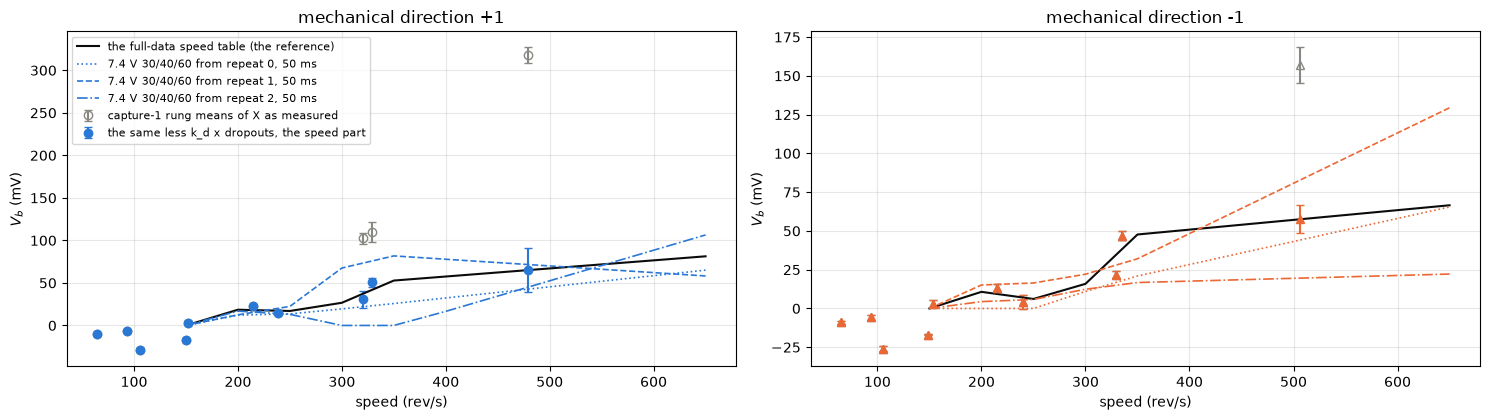

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for a, m in zip(ax, (1, -1)):
    marker = figures.DIRECTION_MARKER[m]
    raw = RM_RAW[RM_RAW["mech"] == m]
    part = RM_ALL[RM_ALL["mech"] == m]
    a.errorbar(raw["rev_s"], raw["x"], yerr=raw["sd"] / np.sqrt(raw["n"]),
               fmt=marker, mfc="none", color=figures.MUTED, capsize=3,
               label="capture-1 rung means of X as measured")
    a.errorbar(part["rev_s"], part["x"],
               yerr=part["sd"] / np.sqrt(part["n"]), fmt=marker,
               color=MECH_COLOR[m], capsize=3,
               label="the same less k_d x dropouts, the speed part")
    a.plot(idn.VB_KNOTS, VB_FULL[m]["table"], "-", color=figures.INK,
           lw=1.5, label="the full-data speed table (the reference)")
    for rep, ls in zip(REPEATS, (":", "--", "-.")):
        a.plot(idn.VB_KNOTS, VB_MIN[(SHORT_MS, rep)][m]["table"], ls,
               color=MECH_COLOR[m], lw=1.2,
               label=f"7.4 V 30/40/60 from repeat {rep}, 50 ms")
    figures.label(a, x="speed (rev/s)", y=r"$V_b$ (mV)",
                  title=f"mechanical direction {m:+d}")
ax[0].legend(fontsize=8)
figures.finish(fig)

Each direction's rung means over every repeat, hollow as measured and filled with $k_d$ times the rung's dropouts taken out, the full-data speed table in black, and the minimal table from each repeat over 50 ms in color. The thing to see is how much of the rise past 300 rev/s the dropout term takes, and how close the two directions' speed parts come.

The dropout threshold sits in a gap on this motor only in part. Of capture-1's rows under 0.40 of the window mean, 513 sit under 0.10 and 238 between the quarter and 0.40, so 35 % of them are in the two bands around the threshold, 41 of them just under it. $k_d$ is 0.524 $\pm$ 0.026 mV per dropout/s over 49 dof. The low rungs split by rail, -4.2 $\pm$ 0.6 mV at 5 V against -22.2 $\pm$ 0.6 at 7.4 V, 20 se apart, so the floor is zero. With $k_d$ out the speed part reaches 72 mV at 550 rev/s in mech +1 and 60 mV in mech -1, where the speed-only tables read 416 and 185 mV, and the 231 mV the speed-only tables split by direction at 550 rev/s is 12 mV in the speed parts. The three single-repeat tables scatter 2 to 18 mV a knot up to 300 rev/s and 5 to 56 mV from 350 to 650. The minimal subset's tables sit 21 mV (mech +1) and 17 mV (mech -1) rms from the full-data table over the 200 to 500 rev/s knots with 50 ms windows, and its $k_d$ reads 0.51 in the median of the three passes, 0.42 to 0.80. Moderate confidence.


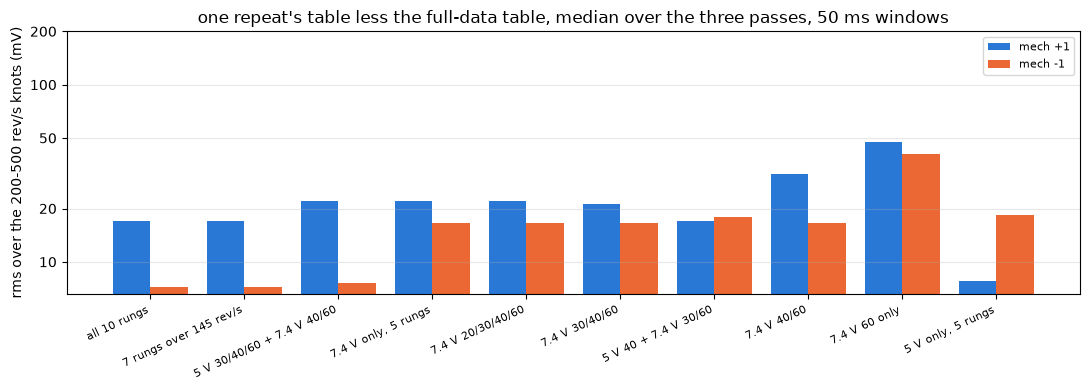

In [60]:
short = KM[KM["pre"] == SHORT_MS]
names = list(SUBSETS)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 4))
for j, m in enumerate((1, -1)):
    rms = short[short["mech"] == m].set_index("subset").loc[names, "rms_mv"]
    ax.bar(x + (j - 0.5) * 0.4, rms, 0.4, color=MECH_COLOR[m],
           label=f"mech {m:+d}")
ax.set_yscale("log")
ax.set_yticks([10, 20, 50, 100, 200], ["10", "20", "50", "100", "200"])
ax.minorticks_off()
ax.set_xticks(x, names, fontsize=8, rotation=25, ha="right")
ax.legend(fontsize=8)
figures.label(ax, y="rms over the 200-500 rev/s knots (mV)",
              title="one repeat's table less the full-data table, median "
              "over the three passes, 50 ms windows", grid=False)
ax.grid(alpha=figures.GRID_ALPHA, axis="y")
figures.finish(fig)

Each subset's table less the full-data table, rms over the 200 to 500 rev/s knots, the median over the three passes, on a log scale. The thing to see is how flat the chart is. With $k_d$ carrying the rise past 300 rev/s the speed tables are small, and the subsets differ by tens of millivolts at most: all ten rungs 17 and 7 mV (mech +1 and -1), 7.4 V 30/40/60 21 and 17 mV, 7.4 V 40/60 31 and 17, one rung alone 48 and 40, and 5 V alone 8 and 19 mV but +14 and +47 mV at 550 rev/s, where it extrapolates from 340. The 50 and 200 ms windows agree within a few mV for every subset. $k_d$ from the minimal rungs reads 0.51 to 0.53 mV per dropout/s in the median against 0.524 on the full data, 0.42 to 0.80 over the three passes with 50 ms windows. With 200 ms windows the largest spin is 136 revs, inside 157 with no room to coast, and with 50 ms windows it is 58. The six spins of the minimal set cost 243 revs and 0.8 s with 50 ms windows.


In [61]:
# per-rung residuals of the minimal table (7.4 V 30/40/60, 200 ms) at the
# held-out repeats' rungs: measured V_b less the table
held = []
for rep in REPEATS:
    fit = VB_MIN[(BENCH_MS, rep)]
    te = C1[C1["repeat"] != rep].copy()
    te["x"] = idn.vb_measured(te, FT_PUB).to_numpy()
    dropouts = idn.signals(te, FT_PUB)["dropouts"].to_numpy()
    table = idn.vb_total(fit, te["mech"].to_numpy(),
                         te["spin_rev_s"].to_numpy(), dropouts, "table")
    te["res"] = te["x"] - table
    held.append(te)
RRV = pd.concat(held)
VR = RRV.groupby(["level", "duty", "mech"]).agg(
    rev_s=("spin_rev_s", "mean"), res=("res", "mean"), sd=("res", "std"),
    n=("res", "size")).reset_index()
# a cell holds 3 distinct spins, each held out twice, so n is 6 and the se
# counts 3
VR["se"] = VR["sd"] / np.sqrt(DISTINCT_SPINS)
VR["z"] = VR["res"] / VR["se"]
VR["in_fit"] = idn.in_rungs(VR, idn.MIN_RUNGS)
show(VR.sort_values(["mech", "rev_s"]), n=None)
outside = VR[(VR["z"].abs() >= 2) & ~VR["in_fit"]]
print(f"rungs outside the flat band and not in the fit: {len(outside)} of "
      f"{int((~VR['in_fit']).sum())}; 1 mV of V_b is "
      f"{1e-3 / idn.KE_REV:.3f} rev/s of speed")

,level,duty,mech,rev_s,res,sd,n,se,z,in_fit
0,5.000,15,-1,65.046,-9.030,1.419,6,0.819,-11.025,False
2,5.000,20,-1,93.806,-5.763,2.601,6,1.502,-3.838,False
10,7.400,15,-1,105.621,-26.058,2.389,6,1.379,-18.893,False
12,7.400,20,-1,148.844,-16.838,0.721,6,0.416,-40.429,False
4,5.000,30,-1,153.365,2.674,3.296,6,1.903,1.405,False
6,5.000,40,-1,214.516,7.249,5.258,6,3.035,2.388,False
14,7.400,30,-1,239.784,-2.311,11.114,6,6.417,-0.360,True
16,7.400,40,-1,329.680,0.379,6.369,6,3.677,0.103,True
8,5.000,60,-1,335.485,24.429,4.974,6,2.872,8.506,False
18,7.400,60,-1,506.586,0.079,24.709,6,14.266,0.006,True


rungs outside the flat band and not in the fit: 12 of 14; 1 mV of V_b is 0.136 rev/s of speed


Each held-out rung's residual by speed, the rungs inside the fit ringed.

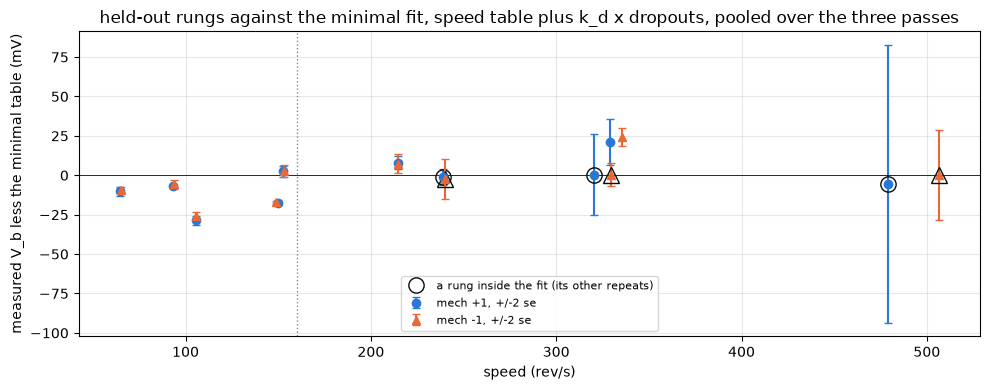

In [62]:
fig, ax = plt.subplots(figsize=(10, 4))
for m in (1, -1):
    marker = figures.DIRECTION_MARKER[m]
    rungs = VR[VR["mech"] == m]
    ax.errorbar(rungs["rev_s"], rungs["res"], yerr=2 * rungs["se"],
                fmt=marker, color=MECH_COLOR[m], capsize=3, ms=6,
                label=f"mech {m:+d}, +/-2 se")
    inside = rungs[rungs["in_fit"]]
    ax.plot(inside["rev_s"], inside["res"], marker, mfc="none",
            mec=figures.INK, ms=11)
ax.plot([], [], "o", mfc="none", mec=figures.INK, ms=11,
        label="a rung inside the fit (its other repeats)")
ax.axhline(0, color=figures.INK, lw=0.6)
ax.axvline(idn.LOW_SPEED, color=figures.MUTED, lw=1, ls=":")
ax.legend(fontsize=8)
figures.label(ax, x="speed (rev/s)",
              y="measured V_b less the minimal table (mV)",
              title="held-out rungs against the minimal fit, speed table "
              "plus k_d x dropouts, pooled over the three passes")
figures.finish(fig)

Each held-out rung's measured $X$ less the minimal fit over 200 ms, the speed table plus $k_d$ times the spin's own dropouts, by speed, with $\pm$2 standard errors over the three distinct spins of a cell, the rungs inside the fit ringed. The thing to see is the two groups that sit off zero, the rungs under 150 rev/s and the 5 V rungs above 200.

Under 150 rev/s every rung sits below zero, -6 to -29 mV, the 7.4 V rungs at -17 to -29 mV (z -18 to -40). Above 200 rev/s the 5 V rungs sit above zero and the 7.4 V rungs on it: 5 V 40 % reads +7 to +8 mV (z 2.4 and 3.8) and 5 V 60 % +21 to +24 mV (z 2.9 and 8.5) in the two directions, while the 7.4 V rungs inside the fit read within 6 mV on the other repeats. The full-data rung means show the same thing at one speed: at 330 rev/s in the direction with no dropouts, 5 V 60 % reads 47 mV and 7.4 V 40 % 22 mV. So $X$ carries a term that follows the rail and not the speed, about 20 to 25 mV lower at 7.4 V than at 5 V from 65 to 335 rev/s, which neither a speed table nor $k_d$ holds, and a fit on 7.4 V rungs alone carries it to 5 V as a bias. It is the size of the ON edge's lag uncertainty on the 7.4 V tap, where sample-timing's bounds span 26 ticks at about 3 mV a tick. The same rungs at 3.7 V would say whether it is linear in the rail. One millivolt of $V_b$ is 0.136 rev/s.


## Results

The figure sets every route against its reference on one axis, one dot per seat, combination, pass or folder. The thing to see is the width of each route. $K_e$ from one repeat is the tightest, $R$ from one seat and $L$ from one seat spread a few percent, and $c$ and the anchor carry a few percent from one run-up each way.

In [63]:
# each route's error on its reference, from the cells above
ke_ho = REP["held_out_pct"].to_numpy()
l_seat_err = LS[("l_mh", L_SEAT)][1]
cw = np.array([CR[k]["win"] for k in CR]) / C_REF - 1
cp = np.array([CR[k]["pin"] for k in CR]) / C_REF - 1
dmm = np.array([DD[k][0] for k in CR]) - 1
ROUTES = [
    ("R, one seat", SEATS[("as read", 1)], figures.BLUE),
    ("R, two seats", SEATS[("as read", 2)], figures.BLUE),
    ("R, three seats", SEATS[("as read", 3)], figures.BLUE),
    ("R(T), the board NTC's move on T_ref", MOVE.to_numpy(), figures.BLUE),
    ("Ke, one repeat's 20 coasts", ke_ho, figures.GREEN),
    ("L, one seat", l_seat_err.to_numpy(), figures.ORANGE),
    ("c, 5 ms windows", cw * 100, figures.MUTED),
    ("c, pinned", cp * 100, figures.MUTED),
    ("anchor over the DMM", dmm * 100, figures.MUTED)]

Every route on one axis, one dot per seat, combination, pass or folder.

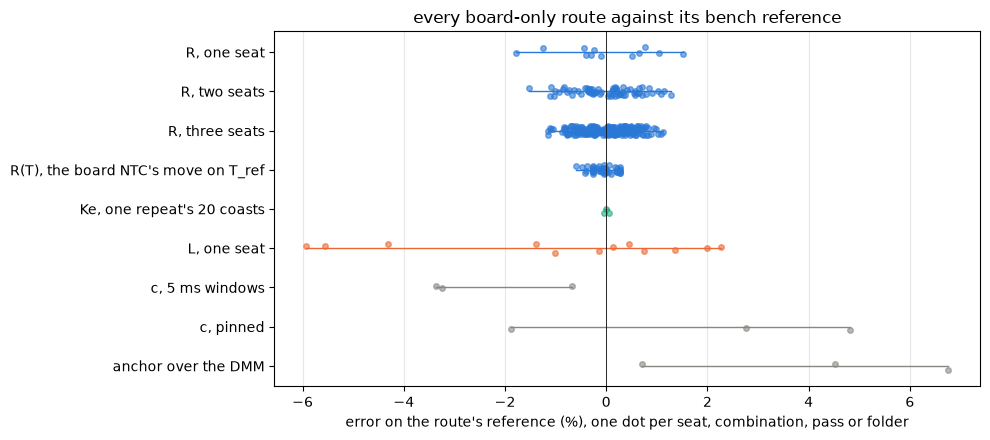

In [64]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for j, (name, err, color) in enumerate(ROUTES):
    err = np.asarray(err, float)
    jitter = np.random.default_rng(j).uniform(-0.12, 0.12, len(err))
    ax.plot(err, np.full(len(err), j) + jitter, "o", ms=4, color=color,
            alpha=0.6)
    ax.plot([np.min(err), np.max(err)], [j, j], color=color, lw=1)
ax.axvline(0, color=figures.INK, lw=0.6)
ax.set_yticks(range(len(ROUTES)), [route[0] for route in ROUTES])
ax.invert_yaxis()
figures.label(ax, x="error on the route's reference (%), one dot per seat, "
              "combination, pass or folder",
              title="every board-only route against its bench reference",
              grid=False)
ax.grid(alpha=figures.GRID_ALPHA, axis="x")
figures.finish(fig)

| constant | board-only route | value | reference | error | spread between repeats | cost |
|---|---|---|---|---|---|---|
| $R$ | one locked seat, two 200 to 300 ms laps at 100 %, 3.7 and 4.2 V | 4.384 to 4.531 ohm by seat | 4.463 ohm, the 12-hole mean (median 4.455) | sd 0.91 %, -1.78 to +1.52 %. Two seats 0.61 %, three 0.48 % | lap to lap 0.24 % | 2 laps, 0.4 to 0.6 s, 0.72 to 0.85 A, no travel |
| $R(T)$ | board NTC, copper 0.39 %/C | -0.60 to +0.26 % of $R$ by sitting | none on the winding | self-heat at most 0.37 % | none | none |
| $K_e$ | 20 coasts of one repeat | 1.16802 to 1.16879 mV s/rad | 1.16838 (bemf-coast) | -0.05 to +0.05 % held out | 0.37 % a coast, four coasts 0.17 % rms | 20 short spins, 1.6 s, 265 revs, the largest 31 |
| $L$ | four bursts at one seat, 25 % forward, the first thrown out | 0.771 to 0.838 mH by seat | 0.833 mH (inductance) | sd 2.8 % on the 12-hole median of the design | burst to burst 0.7 % | 5 bursts, 0.75 s, no travel |
| $\Delta$ | the 100 % anchor, one run-up each way and one repeat's spins | 3.30 to 4.21 mA/V at 15 to 40 %, 2.59 to 2.67 at 60 % | the published no-meter grid | -2.2, -2.3 and +0.6 mA by pass. Over the DMM 1.045, 1.068, 1.007 | 2.9 mA pass to pass | the 20 spins (485 revs, the largest 58) and 2 run-ups |
| $V_b$ | 7.4 V 30/40/60 % both ways, 50 ms windows | $k_d$ 0.51 mV per dropout/s (0.42 to 0.80) and a speed table per mechanical direction | the full-data fit, $k_d$ 0.524 $\pm$ 0.026 | tables 21 and 17 mV rms at the 200 to 500 rev/s knots | single-repeat tables 2 to 56 mV a knot | 6 spins inside the 20, 0.8 s, 243 revs, the largest 58 |
| $c$ | the anchor, one run-up each way | 0.966 to 0.993 x $J/(K_t K_e)$ by windows, 0.981 to 1.048 pinned | $J/(K_t K_e)$ = 0.00458 A s/V | -3.4 to -0.7 % by windows, -1.9 to +4.8 % pinned | sd 1.5 % by windows, 3.4 % pinned | 2 run-ups, 300 ms each |

A whole pass on one seat comes to about 2.6 s of short spins (20 of them, 485 revs, none over 58), two 100 % run-ups, and about 1.4 s locked. Every maneuver fits 157 revs of travel but the 300 ms anchor run-up.

The result file carries one key per constant, each a value with its bounds and, beside it, its reference, its error, its spread and its cost: `r_one_seat_ohm`, `r_two_seats_ohm`, `r_three_seats_ohm`, `r_board_ntc_move_pct` (with $T_\mathrm{ref}$ and the self-heat bounds), `r_reference_rung`, `ke_v_s_per_rad`, `l_mh`, `l_ripple_mh`, `c_a_s_per_v` (by both reads), `delta_f_ma_per_v` (by duty) and `v_b_mv` (the two speed tables by knot, $k_d$, the floor by rail, the threshold's gap, their reference and the rungs), plus `servo_travel_motor_revs`.

In [65]:
def route(quantity, **extra):
    """A quantity with the route's reference, error, spread and cost."""
    return {**quantity, **extra}


def cost(maneuvers, seconds, revs, largest=None, **extra):
    """What a route costs a servo, in maneuvers, seconds and motor revs."""
    out = {"maneuvers": results.q(maneuvers, unit="count"),
           "seconds": results.q(seconds, unit="s"),
           "motor_revs": results.q(revs, unit="rev")}
    if largest is not None:
        out["largest_maneuver_revs"] = results.q(largest, unit="rev")
    out.update(extra)
    return out


def l_key(seat, reference):
    """One seat's L by the 4-burst design, against its 12-hole median."""
    per, err = seat
    return route(results.median_range(per, "mH"), reference=reference,
                 error_pct=results.q(err.std(), err.min(), err.max(), "%"),
                 cost=cost(L_BURSTS, L_SEAT_S, 0.0))


def c_key(passes, read, c_ref, err_pct):
    """One pass's c by one read, the three passes as value and bounds."""
    values = [passes[k][read] for k in passes]
    return route(results.median_range(values, "A s/V"),
                 reference=results.q(c_ref, unit="A s/V"),
                 error_pct=results.median_range(err_pct, "%"))


def knot(speed):
    return f"{speed:.0f} rev/s"

The R keys, one, two and three seats, each with its reference and cost.

In [66]:
bias_200 = HOLD_READS.set_index("read").loc["line_200", "bias_pct"]
R_COST = cost(2, R_SEAT_S, 0.0,
              amps=results.q(np.mean(I_LAP), *I_LAP, "A"),
              joules_per_lap=results.q(np.mean(J_LAP), *J_LAP, "J"),
              hold_200ms_bias_pct=results.q(float(bias_200), unit="%"))
R_SEATS = {}
for k in SEAT_COUNTS:
    picks = itertools.combinations(range(len(seat_r)), k)
    ohm = np.array([np.mean(seat_r[list(pick)]) for pick in picks])
    err = SEATS[("as read", k)]
    angle = SEATS[("angle part", k)]
    R_SEATS[k] = route(
        results.median_range(ohm, "ohm"),
        reference=results.q(R_MEAN, unit="ohm"),
        error_pct=results.q(err.std(), err.min(), err.max(), "%"),
        error_95th_pct=results.q(np.percentile(np.abs(err), 95), unit="%"),
        error_angle_part_pct=results.q(angle.std(), angle.min(),
                                       angle.max(), "%"),
        error_vs_dmm_pct=results.median_range(idn.pct(ohm, R_DMM), "%"),
        spread_pct=results.q(RRN["REPEAT_PCT"], unit="%"),
        cost=dict(R_COST, maneuvers=results.q(2 * k, unit="count"),
                  seconds=results.q(R_SEAT_S * k, unit="s")))

The R(T) and reference-rung keys.

In [67]:
board_c = GRADED["board_c"]
NTC_KEY = route(
    results.median_range(MOVE, "%"),
    t_ref_c=results.q(T_REF, board_c.min(), board_c.max(), "C"),
    board_span_all_tel_c=results.q(BOARD_SPAN, unit="C"),
    self_heat_bound_pct=results.q(SELF_SPIN, unit="%"),
    self_heat_bound_runup_pct=results.q(SELF_RUNUP, unit="%"),
    cost=cost(0, 0.0, 0.0))
ref_rung = LOW_RUNG_R[(LOW_RUNG_R["level"] == REF_RUNG[0])
                      & (LOW_RUNG_R["duty"] == REF_RUNG[1])].set_index("pre")
bench = ref_rung.loc[BENCH_MS]
REF_KEY = dict(
    spin_sd_pct={f"{p} ms": results.q(ref_rung.loc[p, "sd_pct"], unit="%")
                 for p in (SHORT_MS, BENCH_MS)},
    spins_per_check={f"{p} ms": results.q(ref_rung.loc[p, "spins_per_check"],
                                          unit="count")
                     for p in (SHORT_MS, BENCH_MS)},
    trend_pct_per_min=results.pm(bench["trend_pct_per_min"],
                                 bench["trend_se"], "%/min"),
    ntc_predicts_pct=results.q(bench["ntc_predicts_pct"], unit="%"),
    rev_s=results.q(bench["rev_s"], unit="rev/s"))

The Ke, L and c keys.

In [68]:
ke_pass = REP["ke"].to_numpy()
four = COAST_DRAWS.set_index("n").loc[4]     # the key's four coasts
KE_KEY = route(
    results.median_range(ke_pass, "V s/rad"),
    reference=idn.BEMF["ke_v_s_per_rad"],
    error_pct=results.q(idn.rms(ke_ho), ke_ho.min(), ke_ho.max(), "%"),
    spread_per_coast_pct=results.q(K1["ke"].std() / idn.KE * 100, unit="%"),
    four_coasts_rms_pct=results.q(four["rms_ho"], unit="%"),
    speed_trend_pct_per_100_rev_s=results.q(KE_LINE[0] * 100, unit="%"),
    cost=cost(KE_COST["spins"], KE_COST["seconds"], KE_COST["revs"],
              KE_COST["largest"]))
L_KEYS = {col: l_key(LS[(col, L_SEAT)], idn.IND[col]) for col in L_COLS}
RUNUP_MEAN = float(RUNUP_REVS["revs_300ms"].mean())
RUNUP_LARGEST = float(RUNUP_COSTS["with_coast_300"].max())
C_KEY = dict(win=c_key(CR, "win", C_REF, cw * 100),
             pin=c_key(CR, "pin", C_REF, cp * 100),
             cost=cost(RUNUPS, RUNUP_S, 2 * RUNUP_MEAN, RUNUP_LARGEST))

The Delta key, the table per duty with the published grid as its reference.

In [69]:
f50 = pd.DataFrame(F50)                    # duty x pass
pub_at = pd.Series(np.interp(f50.index.to_numpy(float), *FT_PUB),
                   index=f50.index)
DELTA_KEY = {}
for d in f50.index:
    DELTA_KEY[f"{d} %"] = route(
        results.median_range(f50.loc[d], "mA/V"),
        reference=results.q(pub_at.loc[d], unit="mA/V"))
DELTA_KEY["error_ma"] = results.median_range(d50, "mA")
DELTA_KEY["anchor_over_dmm"] = results.median_range(
    [DD[k][0] for k in CR], "")
DELTA_KEY["cost"] = cost(PASS_MANEUVERS, PASS_SPINS["seconds"] + RUNUP_S,
                         PASS_SPINS["revs"] + 2 * RUNUP_MEAN, RUNUP_LARGEST)

The V_b key, the minimal tables by knot, k_d, the floor and the full-data reference.

In [70]:
km50 = KM[(KM["pre"] == SHORT_MS) & (KM["subset"] == MIN_SUBSET)]
km50 = km50.set_index("mech")
kd50 = np.array([VB_MIN[(SHORT_MS, rep)]["k_d"] for rep in REPEATS])
VB_TAB, VB_REF, ONE_SD = {}, {}, {}
for m in (1, -1):
    t = np.array([VB_MIN[(SHORT_MS, rep)][m]["table"] for rep in REPEATS])
    VB_TAB[f"{m:+d}"] = {knot(k): results.median_range(t[:, i], "mV")
                         for i, k in enumerate(idn.VB_KNOTS)}
    VB_REF[f"{m:+d}"] = {knot(k): results.q(v, unit="mV")
                         for k, v in zip(idn.VB_KNOTS, VB_FULL[m]["table"])}
    singles = np.array([ONE[rep][m]["table"] for rep in REPEATS])
    sd = [float(x) for x in singles.std(axis=0, ddof=1)]
    ONE_SD[f"{m:+d}"] = {knot(k): results.q(v, unit="mV")
                         for k, v in zip(idn.VB_KNOTS, sd)}
V_B_KEY = {
    "rungs": [f"{v:g} V {d} %" for v, d in idn.MIN_RUNGS], "table": VB_TAB,
    "reference": VB_REF,
    "k_d_mv_per_dropout_s": route(
        results.median_range(kd50, "mV s"),
        reference=results.pm(VB_FULL["k_d"], VB_FULL["k_d_se"], "mV s")),
    "floor_mv": results.q(VB_FULL["floor"], unit="mV"),
    "floor_by_rail_mv": {f"{lv:g} V": results.pm(x, s, "mV") for lv, (x, s)
                         in VB_FULL["floor_by_rail"].items()},
    "dropout_threshold": results.q(SEP["threshold"], unit=""),
    "dropout_ambiguous_share": results.q(SEP["ambiguous_share"], unit=""),
    "error_rms_200_500_mv": {f"{m:+d}": results.q(km50.loc[m, "rms_mv"],
                                                  unit="mV")
                             for m in (1, -1)},
    "single_repeat_sd_mv": ONE_SD,
    "cost": cost(VB_COST["spins"], VB_COST["seconds"], VB_COST["revs"],
                 VB_COST["largest"])}

The notes that travel with the result file, kept as they were written.

In [71]:
NOTES = (
    "identification reads stage 2's mg90-b captures as a servo's board alone "
    "could and grades each route against stage 2's bench references; it "
    "scores no speed. Each route key is a quantity, value and bounds, with "
    "reference, error_pct (or error_ma), spread and cost beside it. "
    "r_one_seat_ohm, r_two_seats_ohm, r_three_seats_ohm: rest-resistance's "
    "stall pass, a seat's R the mean of its two graded 100 % laps (3.7 and "
    "4.2 V, direction +1, the line through V/I back to the lap's start), "
    "every combination of k of the 12 holes; value the median, bounds the "
    "lowest and highest; reference the 12-hole mean; error_pct sd over the "
    "combinations with the extremes as bounds; error_angle_part_pct the same "
    "with rest-resistance's one-body heat taken out; spread_pct the laps' "
    "own scatter about a hole's mean. r_board_ntc_move_pct: copper's 0.39 "
    "%/C times the board NTC (nominal beta, at each folder's rest baseline) "
    "less T_ref, the board at the stall pass's graded laps, over capture-1, "
    "speed-torque and swapped-1's folders; self_heat_bound_pct the winding's "
    "rise bounded by rest-resistance's warming_pct_per_j for a spin's own "
    f"joules and its one-body map ({RRN['best']['slope']:.3f} %/J held, tau "
    f"{RRN['TAU_BODY']:.0f} s) for heat carried. r_reference_rung: "
    "capture-1's 5 V 15 % running R at the cut, (V_mean - E0)/i_hat, the "
    "per-spin sd with direction means out, the spins per check for 0.5 % on "
    "a change, and the trend over the sitting. ke_v_s_per_rad: one repeat's "
    "20 coasts (e_win over the ripple count), the three repeats as the value "
    "and bounds; error_pct held out on the other two repeats. l_mh, "
    "l_ripple_mh: inductance's capture-1 bursts at one seat, 4 bursts at 25 "
    "% forward with the group's first thrown out, the 12 holes as value and "
    "bounds; error_pct against the 12-hole median of the same design. "
    "c_a_s_per_v: c = i100 / (Ke (alpha_drive + alpha_coast)) from one "
    "speed-torque run-up per direction, the three passes, by the coast's 5 "
    "ms windows and its pinned read. delta_f_ma_per_v: the reading term per "
    "volt by the 100 % anchor, crest less anchor over 50 ms windows of one "
    "capture-1 repeat with that pass's c, the three passes; error_ma the "
    "mean over capture-1's rungs at their own v_on against the published "
    "no-meter grid. v_b_mv: the speed table by mechanical direction from one "
    "repeat of 7.4 V 30/40/60 % both ways, 50 ms windows, reference R, Ke "
    "and Delta; value the median over the three passes, bounds the range; "
    "reference the full-data table (all repeats, 200 ms). X = V_mean - Ke "
    "w_tach - R i_hat is split as a speed table plus k_d_mv_per_dropout_s "
    "times the dropout rate (rows of the window under dropout_threshold of "
    "its mean, per second); the table is the speed part; floor_mv is the "
    "table at and below 150 rev/s, the low rungs' mean unless the rails "
    "split (floor_by_rail_mv), then 0; dropout_ambiguous_share is the share "
    "of the rows under 0.40 of the mean that sit within 0.10 to 0.40, the "
    "threshold's gap. Costs by the board's rough speed, (D v_on - R i)/Ke, a "
    "short spin the spin-up to 95 % of speed, the window and 15 ms of coast; "
    "the anchor run-up's revs by speed-torque's turn-window tach.")

mg90-b's result file.

In [72]:
path = results.write(
    "2-motor", "identification", idn.PAIR, pair=idn.MOTOR.key, notes=NOTES,
    servo_travel_motor_revs=results.q(idn.TRAVEL_REVS, unit="rev"),
    r_one_seat_ohm=R_SEATS[1], r_two_seats_ohm=R_SEATS[2],
    r_three_seats_ohm=R_SEATS[3], r_board_ntc_move_pct=NTC_KEY,
    r_reference_rung=REF_KEY, ke_v_s_per_rad=KE_KEY,
    l_mh=L_KEYS["l_mh"], l_ripple_mh=L_KEYS["l_ripple_mh"],
    c_a_s_per_v=C_KEY, delta_f_ma_per_v=DELTA_KEY, v_b_mv=V_B_KEY)
print("wrote", path)

wrote stages/2-motor/identification/results/mg90-b.json


## Second motor

Everything above was built on mg90-b. mg90-c is a second motor of the same family on the same board, and this section is the check that the identification passes and what they recover come out the same on a motor they were not built on. It runs the same passes on mg90-c's own datasets and grades each against mg90-c's own reference constants. mg90-b's numbers from the cells above stand beside them as the comparison and enter nothing. The [telemetry README](../../../telemetry/mg90-c__dev-v006-2A-D/README.md) lists every mg90-c dataset with its brush state.

`second_motor_ident.py`, beside the notebook, executes `identification.py` a second time on top of motor-model's `second_motor.py`, so every constant comes from mg90-c's result files and every folder is mg90-c's. No function body changes. Where identification runs another notebook's cells, the same cells run on mg90-c. rest-resistance's lap reduction runs with mg90-c as the registry's motor, inductance's bursts go through that notebook's own mg90-c cells, and speed-torque's count runs with the capture and the constants rebound to mg90-c, as speed-torque's own mg90-c section rebinds them. Each reproduces its mg90-c result file, and the cells below assert it.

The data differ from mg90-b's in four ways.

- The stall pass and the bursts share one bar seat, in state C, half a day after the ladder. rest-resistance has no meter's ohms and no one-body split on mg90-c, so the seats are graded as read, and the winding's self-heat bound is not run.
- The ladder, `bemf-coast/capture-1`, in state A, ran a 3.7 V level as well. The pass reads its 5.0 and 7.4 V rungs, the rungs mg90-b's pass read, so one repeat is again 20 coasts. bemf-coast's $K_e$, the reference, is the mean over all 84 coasts, the 3.7 V ones included.
- Every dataset ran the black lead on MOT_A, as mg90-b's capture-1 did, so the mechanical direction is the board's.
- The meter runs `meter-1` and `high-1` ran in state C.

The method runs as written. Where one of its rules fails on this motor, the pass is kept as it comes out and the failure is reported.

In [73]:
# the second motor: identification.py again, on mg90-c's results and folders
ic = smi.idn                            # the mg90-c copy; idn stays mg90-b's
print(ic.MOTOR.key, "on", ic.BOARD.key, "from", results.rel(ic.PAIR))
print(f"locked R {ic.R_LOCKED:.4f} ohm (rest-resistance), "
      f"Ke {ic.KE * 1e3:.5f} mV s/rad (bemf-coast), "
      f"J {ic.J * 1e9:.4f} x 1e-9 kg m^2 (speed-torque), "
      f"L {ic.IND['l_mh']['value']:.4f} mH (inductance)")
RED_C = ic.reductions()
TB_C, SL_C = RED_C["TB"], RED_C["SL"]
FT_PUB_C = ic.f_table_published()       # mg90-c's own no-meter grid
TAGGED_C = ic.tag_mech(TB_C["capture-1"], "capture-1")
PASS_C = TAGGED_C[TAGGED_C["level"].isin([5.0, 7.4])]   # the pass's rails
gate_c, dropped_c = ic.tach_gate(PASS_C)
C1_C = PASS_C[gate_c]                   # a spin the gate fails is not a truth
DROPPED_C = [int(k) for k in dropped_c["k"]]
print(f"capture-1: {len(TAGGED_C)} spins, {len(PASS_C)} at 5.0 and 7.4 V; "
      f"the ripple tach's gate keeps {len(C1_C)}, drops k {DROPPED_C}")
show(dropped_c, n=None)

mg90-c on dev-v006-2A-D from telemetry/mg90-c__dev-v006-2A-D
locked R 4.4020 ohm (rest-resistance), Ke 1.16441 mV s/rad (bemf-coast), J 6.1405 x 1e-9 kg m^2 (speed-torque), L 0.8410 mH (inductance)


capture-1: 84 spins, 60 at 5.0 and 7.4 V; the ripple tach's gate keeps 58, drops k [43, 44]


,k,dir,duty,spin_rev_s,spin_rev_s_rough,rev_s_cut_win,seed_diff_pct,tach_less_coast_pct
80,43,1,60,485.716,488.229,486.338,0.517,-0.128
82,44,1,60,486.957,489.474,490.785,0.517,-0.780


In [74]:
# R and L from one seat: rest-resistance's and inductance's cells on mg90-c
RRN_C, INN_C = ic.rest_resistance_cells(), ic.inductance_cells()
HOLE_C, S_C, C2_C = RRN_C["HOLE"], RRN_C["S"], INN_C["C2"]
seat_r_c = HOLE_C["r_plus"].to_numpy()
assert np.allclose(seat_r_c, ic.RR["r_term_by_hole"], atol=1e-4)
GRADED_C = S_C[S_C["graded"] & (S_C["dir"] == 1)]
R_MEAN_C = float(seat_r_c.mean())
SEATS_C = {k: idn.combos(seat_r_c, k) for k in SEAT_COUNTS}
for k, c in SEATS_C.items():
    print(f"R, the mean of {k} seat(s): sd {c.std():.2f} %, "
          f"{c.min():+.2f} to {c.max():+.2f} % on the 12-hole mean "
          f"(mg90-b sd {SEATS[('as read', k)].std():.2f} %)")
print(f"the 12-hole mean {R_MEAN_C:.4f} ohm, one seat {seat_r_c.min():.4f} "
      f"to {seat_r_c.max():.4f}; lap scatter {RRN_C['REPEAT_PCT']:.2f} %")
SEAT_L_C = {}
for col in L_COLS:
    by_hole = C2_C.groupby("hole")[col].median().to_numpy()
    assert np.allclose(by_hole, ic.IND[f"{col}_by_hole"], atol=2e-4)
    design = C2_C[C2_C["group"] == "g1-fwd-25"]   # 4 bursts, 25 % forward
    per = design.groupby("hole")[col].median()
    err = pd.Series(idn.pct(per, per.median()), index=per.index)
    SEAT_L_C[col] = (per, err)
    mg90b = LS[(col, L_SEAT)][1]
    print(f"{col}: one seat {per.min():.4f} to {per.max():.4f} mH, sd "
          f"{err.std():.2f} % on the 12-hole median {per.median():.4f} mH "
          f"(mg90-b sd {mg90b.std():.2f} %)")

R, the mean of 1 seat(s): sd 0.92 %, -2.47 to +1.08 % on the 12-hole mean (mg90-b sd 0.91 %)
R, the mean of 2 seat(s): sd 0.62 %, -1.65 to +1.07 % on the 12-hole mean (mg90-b sd 0.61 %)
R, the mean of 3 seat(s): sd 0.48 %, -1.28 to +0.95 % on the 12-hole mean (mg90-b sd 0.48 %)
the 12-hole mean 4.3916 ohm, one seat 4.2831 to 4.4391; lap scatter 0.24 %
l_mh: one seat 0.7737 to 0.8429 mH, sd 2.67 % on the 12-hole median 0.8100 mH (mg90-b sd 2.84 %)
l_ripple_mh: one seat 0.5914 to 0.6273 mH, sd 1.71 % on the 12-hole median 0.6171 mH (mg90-b sd 2.77 %)


In [75]:
# Ke from one repeat's 20 coasts at the pass's rungs, against bemf-coast's Ke
coasts_c = TB_C["capture-1"]
ke_all_c = coasts_c["e_win"] / (2 * np.pi * coasts_c["coast_rev_s"])
assert abs(ke_all_c.mean() / ic.KE - 1) < 1e-9    # bemf-coast's 84 coasts
K1_C = PASS_C.assign(ke=PASS_C["e_win"] / (2 * np.pi * PASS_C["coast_rev_s"]))
rows = []
for rep, own in K1_C.groupby("repeat"):
    others = K1_C[K1_C["repeat"] != rep]["ke"].mean()   # the same rungs
    rows.append(dict(repeat=rep, coasts=len(own), ke_mv=own["ke"].mean() * 1e3,
                     in_sample_pct=idn.pct(own["ke"].mean(), ic.KE),
                     held_out_pct=idn.pct(own["ke"].mean(), others)))
REP_C = pd.DataFrame(rows)
show(REP_C, n=None)
KE_LINE_C = np.polyfit(K1_C["coast_rev_s"], idn.pct(K1_C["ke"], ic.KE), 1)
low_c = ke_all_c[coasts_c["level"] == 3.7]
print(f"per coast sd {K1_C['ke'].std() / ic.KE * 100:.2f} %, a line "
      f"{KE_LINE_C[0] * 100:+.2f} % per 100 rev/s; the reference's 3.7 V "
      f"coasts read {idn.pct(low_c.mean(), ic.KE):+.2f} % on it")
print("mg90-b held out: " + ", ".join(f"{x:+.3f}" for x in ke_ho) + " %")

,repeat,coasts,ke_mv,in_sample_pct,held_out_pct
0,0,20,1.164,-0.025,0.102
1,1,20,1.164,-0.076,0.025
2,2,20,1.162,-0.177,-0.127


per coast sd 0.40 %, a line -0.28 % per 100 rev/s; the reference's 3.7 V coasts read +0.23 % on it
mg90-b held out: +0.053, -0.007, -0.046 %


In [76]:
# c = J/(Kt Ke) per cut by both reads, from mg90-c's speed-torque run-ups
REV_C = ic.runup_windows()[0]
ST_C = TB_C["speed-torque"].copy()
ST_C = ST_C.merge(ic.cut_slopes(REV_C, ST_C), on=["k", "dir"])
ST_C["i100"] = ST_C["i_crest_50"]           # nothing switches at 100 %
C_REF_C = ic.J / ic.KE ** 2
CALL_C = ic.c_per_cut(ST_C)
CUTS_C = ST_C[["k", "dir", "repeat", "spin_rev_s", "i100", "drag_win_ma",
               "drag_pin_ma"]].assign(c_win=CALL_C["win"] / C_REF_C,
                                      c_pin=CALL_C["pin"] / C_REF_C)
print(f"c over J/(Kt Ke) = {C_REF_C:.5f} A s/V, per cut:")
show(CUTS_C, n=None)
PIN_NEG_C = [dict(k=int(r.k), dir=int(r.dir))
             for r in CUTS_C.itertuples() if r.c_pin < 0]
CR_C = {}
for rep in sorted(ST_C["repeat"].unique()):  # a pass: one run-up each way
    one = (ST_C["repeat"] == rep).to_numpy()
    CR_C[int(rep)] = {x: float(CALL_C[x][one].mean())
                      for x in idn.ANCHOR_READS}
for x in idn.ANCHOR_READS:
    v_c = [CR_C[k][x] / C_REF_C for k in CR_C]
    v_b = [CR[k][x] / C_REF for k in CR]
    print(f"{x}, one pass: " + ", ".join(f"{v:.3f}" for v in v_c)
          + " (mg90-b " + ", ".join(f"{v:.3f}" for v in v_b) + "); six "
          f"cuts {CALL_C[x].mean() / C_REF_C:.3f}, sd "
          f"{CALL_C[x].std(ddof=1) / abs(CALL_C[x].mean()) * 100:.1f} %")
print(f"cuts with a negative pinned c: {PIN_NEG_C}")

c over J/(Kt Ke) = 0.00453 A s/V, per cut:


,k,dir,repeat,spin_rev_s,i100,drag_win_ma,drag_pin_ma,c_win,c_pin
0,0,1,0,559.644,102.759,108.579,95.619,0.946,1.074
1,0,-1,0,563.630,105.914,111.022,84.498,0.969,1.279
2,1,1,1,563.280,104.879,112.612,104.865,0.918,0.984
3,1,-1,1,541.332,106.813,106.858,-46.728,1.009,-2.237
4,2,1,2,560.167,104.182,106.406,101.556,0.977,1.024
5,2,-1,2,568.152,106.993,112.008,98.052,0.954,1.090


win, one pass: 0.958, 0.964, 0.966 (mg90-b 0.967, 0.993, 0.966); six cuts 0.962, sd 3.2 %
pin, one pass: 1.177, -0.626, 1.057 (mg90-b 1.028, 1.048, 0.981); six cuts 0.536, sd 254.2 %
cuts with a negative pinned c: [{'k': 1, 'dir': -1}]


In [77]:
# Delta per pass: the crest less the anchor over 50 ms, with that pass's c
RAW_C = TB_C["capture-1"].loc[C1_C.index]   # the pass's spins, gated
v_on_c = RAW_C.groupby(["level", "duty"])["v_on_200"].mean()
F50_C, D50_C, DD_C = {}, {}, {}
for rep, c_pass in CR_C.items():
    spins = RAW_C[RAW_C["repeat"] == rep].copy()
    T50 = ic.anchor_delta(spins, c_pass, SL_C, "capture-1", pre=SHORT_MS)
    table, F50_C[rep] = ic.f_from(T50)
    err = [(np.interp(du, *table) - np.interp(du, *FT_PUB_C)) * v
           for (lv, du), v in v_on_c.items()]    # at each rung's own v_on
    D50_C[rep] = float(np.mean(err))
    ratio = []
    for run in ("meter-1", "high-1"):            # the anchor over the DMM
        T = ic.anchor_delta(TB_C[run].copy(), c_pass, SL_C, run)
        T = T[T["duty"] < 100]
        ratio.append(T["anchor"] / T["meter_ma"])
    DD_C[rep] = float(pd.concat(ratio).mean())
    print(f"pass {rep}: f(D) " + ", ".join(
        f"{d} % {v:.2f}" for d, v in F50_C[rep].items())
        + f" mA/V; {D50_C[rep]:+.1f} mA on the grid, "
        f"{DD_C[rep]:.3f} of the DMM")
print("the published grid, mA/V: " + ", ".join(
    f"{d:g} % {v:.2f}" for d, v in zip(*FT_PUB_C) if 0 < d < 100))
print("mg90-b by pass: " + ", ".join(
    f"{m:+.1f} mA, {DD[k][0]:.3f}" for k, m in zip(CR, d50)))

pass 0: f(D) 15 % 2.25, 20 % 2.15, 30 % 1.70, 40 % 2.44, 60 % 2.98 mA/V; -7.0 mA on the grid, 1.144 of the DMM
pass 1: f(D) 15 % 16.39, 20 % 18.40, 30 % 21.53, 40 % 14.36, 60 % 2.64 mA/V; +68.5 mA on the grid, -0.309 of the DMM
pass 2: f(D) 15 % 2.98, 20 % 3.45, 30 % 2.96, 40 % 3.16, 60 % 2.97 mA/V; -2.1 mA on the grid, 1.048 of the DMM
the published grid, mA/V: 10 % 3.43, 15 % 3.58, 20 % 3.69, 30 % 3.73, 40 % 3.56, 50 % 3.21, 60 % 2.72, 70 % 2.13, 80 % 1.48, 90 % 0.81
mg90-b by pass: -2.2 mA, 1.045, -2.3 mA, 1.068, +0.6 mA, 1.007


In [78]:
# V_b: the full-data fit and one repeat's 7.4 V 30/40/60 %, gated spins out
SEP_C = ic.dropout_separation(C1_C)
VB_FULL_C = ic.vb_fit(C1_C, FT_PUB_C)          # all three repeats, 200 ms
ONE_C = {r: ic.vb_fit(C1_C[C1_C["repeat"] == r], FT_PUB_C) for r in REPEATS}
VB_MIN_C = {}
for rep in REPEATS:
    spins = C1_C[(C1_C["repeat"] == rep) & ic.in_rungs(C1_C, ic.MIN_RUNGS)]
    print(f"repeat {rep}: {len(spins)} of {2 * len(ic.MIN_RUNGS)} spins")
    VB_MIN_C[rep] = ic.vb_fit(spins, FT_PUB_C, pre=SHORT_MS)
KD_C = np.array([VB_MIN_C[r]["k_d"] for r in REPEATS])
RMS_VB_C = {m: float(np.median([idn.rms((VB_MIN_C[r][m]["table"]
            - VB_FULL_C[m]["table"])[GRADED_KNOTS]) for r in REPEATS]))
            for m in (1, -1)}
print(f"full data: k_d {VB_FULL_C['k_d']:.3f} +/- {VB_FULL_C['k_d_se']:.3f} "
      f"(mg90-b {VB_FULL['k_d']:.3f}); the low rungs by rail " + ", ".join(
          f"{lv:g} V {x:+.1f}" for lv, (x, s) in
          VB_FULL_C["floor_by_rail"].items())
      + f" mV, {VB_FULL_C['floor_split_se']:.0f} se apart, floor "
      f"{VB_FULL_C['floor']:.0f}; ambiguous rows "
      f"{SEP_C['ambiguous_share'] * 100:.0f} %")
for m in (1, -1):
    print(f"  mech {m:+d}, speed table " + " ".join(
        f"{x:.0f}" for x in VB_FULL_C[m]["table"]) + " mV")
print(f"minimal, 50 ms: k_d {np.median(KD_C):.2f} ({KD_C.min():.2f} to "
      f"{KD_C.max():.2f}); tables rms " + " and ".join(
          f"{RMS_VB_C[m]:.0f}" for m in (1, -1))
      + " mV (mg90-b " + " and ".join(
          f"{km50.loc[m, 'rms_mv']:.0f}" for m in (1, -1)) + ")")

repeat 0: 6 of 6 spins
repeat 1: 5 of 6 spins
repeat 2: 5 of 6 spins
full data: k_d 0.443 +/- 0.041 (mg90-b 0.524); the low rungs by rail 5 V -1.5, 7.4 V -29.4 mV, 31 se apart, floor 0; ambiguous rows 43 %
  mech +1, speed table 0 22 4 24 95 94 93 91 90 89 87 mV
  mech -1, speed table 0 12 0 9 49 56 63 71 78 85 92 mV
minimal, 50 ms: k_d 0.54 (0.28 to 0.58); tables rms 64 and 18 mV (mg90-b 21 and 17)


In [79]:
# R moved by the board NTC on the stall pass's T_ref, every TEL folder,
# the same captures as mg90-b's
jobs, caps = [], []
for cap, tab in NTC_CAPS:
    for _, C in pd.read_csv(ic.PAIR / cap / tab).iterrows():
        jobs.append((ic.folder_ntc, (ic.PAIR / cap / C["folder"],), {}))
        block = "" if tab in ("cycles.csv", "laps.csv") else f" ({tab[:-4]})"
        caps.append(cap + block)
NT_C = pd.DataFrame(smi.run_parallel(jobs)).assign(capture=caps)
T_REF_C = float(GRADED_C["board_c"].median())
NT_C["r_move_pct"] = idn.ALPHA_CU * (NT_C["ntc_c"] - T_REF_C) * 100
for cap, g in NT_C.groupby("capture", sort=False):
    print(f"  {cap:34s} board {g['ntc_c'].min():.2f} to "
          f"{g['ntc_c'].max():.2f} C, R moves {g['r_move_pct'].min():+.2f} "
          f"to {g['r_move_pct'].max():+.2f} %")
MOVE_C = NT_C[NT_C["capture"].isin(SPIN_CAPS)]["r_move_pct"]
SPAN_C = float(NT_C["ntc_c"].max() - NT_C["ntc_c"].min())
print(f"T_ref {T_REF_C:.2f} C; the spinning captures move R "
      f"{MOVE_C.min():+.2f} to {MOVE_C.max():+.2f} % (mg90-b "
      f"{MOVE.min():+.2f} to {MOVE.max():+.2f}); every folder spans "
      f"{SPAN_C:.2f} C")

  bemf-coast/capture-1               board 24.19 to 25.11 C, R moves +0.57 to +0.93 %
  speed-torque/capture-1             board 24.60 to 25.02 C, R moves +0.74 to +0.90 %
  rest-resistance/capture-1/stall    board 21.63 to 22.88 C, R moves -0.43 to +0.06 %
  bemf-coast/meter-1                 board 22.40 to 23.93 C, R moves -0.12 to +0.47 %
  bemf-coast/swapped-1 (wired)       board 21.15 to 22.25 C, R moves -0.61 to -0.18 %
  bemf-coast/swapped-1 (swapped)     board 21.34 to 22.34 C, R moves -0.54 to -0.15 %
  bemf-coast/high-1                  board 22.90 to 23.43 C, R moves +0.07 to +0.28 %
T_ref 22.72 C; the spinning captures move R -0.61 to +0.93 % (mg90-b -0.60 to +0.26); every folder spans 3.96 C


In [80]:
# the reference rung, 5 V 15 %: the running R at the cut, as above
ntc_of = NT_C.set_index("folder")["ntc_c"]
t0_c = TB_C["capture-1"]["t_start"].min()
REF_C = {}
for pre in WINDOWS_MS:
    S = ic.signals(TB_C["capture-1"], FT_PUB_C, pre)
    S = S[(S["level"] == REF_RUNG[0]) & (S["duty"] == REF_RUNG[1])]
    r_run = (S["v_mean_d"] - S["e_cut"]) / (S["i_hat_d"] * 1e-3)
    by_dir = r_run.groupby(S["dir"]).transform("mean")
    resid = (r_run - by_dir) / r_run.mean() * 100     # direction means out
    sd = float(np.sqrt((resid ** 2).sum() / (len(S) - 2)))
    minutes = (S["t_start"] - t0_c) / 60
    b, cov = np.polyfit(minutes, resid, 1, cov=True)
    se = float(np.sqrt(cov[0, 0] * (len(S) - 2) / (len(S) - 3)))
    ntc = pd.Series(ntc_of.loc[S["folder"]].to_numpy(), index=S.index)
    first = ntc.groupby(S["repeat"]).first()
    REF_C[pre] = dict(sd_pct=sd, trend=float(b[0]), trend_se=se,
                      rev_s=float(S["spin_rev_s"].mean()),
                      ntc_pct=(first.iloc[-1] - first.iloc[0])
                      * idn.ALPHA_CU * 100, r=float(r_run.mean()),
                      spins=idn.spins_for_change(sd))
    print(f"{pre} ms: {len(S)} spins at {REF_C[pre]['rev_s']:.0f} rev/s, "
          f"R {REF_C[pre]['r']:.3f} ohm, sd {sd:.2f} %, trend {b[0]:+.2f} "
          f"+/- {se:.2f} %/min, the NTC predicts "
          f"{REF_C[pre]['ntc_pct']:+.2f} %; {REF_C[pre]['spins']} spins "
          f"per check (mg90-b sd {ref_rung.loc[pre, 'sd_pct']:.2f} %)")

200 ms: 6 spins at 69 rev/s, R 4.098 ohm, sd 6.07 %, trend +0.08 +/- 2.59 %/min, the NTC predicts +0.07 %; 296 spins per check (mg90-b sd 1.60 %)
50 ms: 6 spins at 69 rev/s, R 4.109 ohm, sd 6.41 %, trend -0.03 +/- 2.74 %/min, the NTC predicts +0.07 %; 329 spins per check (mg90-b sd 1.42 %)


In [81]:
# what a pass costs on mg90-c, by the board's rough speed, as above
CO_C = ic.costs()
on_rails = CO_C["volts_set"].isin([5.0, 7.4]) & (CO_C["run"] == "capture-1")
CC_C = CO_C[on_rails].groupby(["volts_set", "duty_pct"]).agg(
    revs95=("revs95", "mean"), rev_s=("rev_s_end", "mean"),
    c15=("coast_revs_15ms", "mean"), t95=("t95_s", "mean"))
coast_c = CC_C["revs95"] + CC_C["c15"]       # spin-up, cut, 15 ms of coast
window_c = coast_c + CC_C["rev_s"] * WINDOW_S   # with a 50 ms window
tail = WINDOW_S + COAST_S                    # s, the window and the coast
KE_COST_C = dict(spins=REPEAT_COASTS, revs=float(2 * coast_c.sum()),
                 seconds=float(2 * (CC_C["t95"] + COAST_S).sum()),
                 largest=float(coast_c.max()))
mins = window_c.loc[ic.MIN_RUNGS]
VB_COST_C = dict(spins=2 * len(ic.MIN_RUNGS), revs=float(2 * mins.sum()),
                 largest=float(mins.max()), seconds=float(2 * (
                     CC_C["t95"].loc[ic.MIN_RUNGS] + tail).sum()))
PASS_COST_C = dict(spins=2 * len(CC_C), revs=float(2 * window_c.sum()),
                   largest=float(window_c.max()),
                   seconds=float(2 * (CC_C["t95"] + tail).sum()))
runup_c = []
for (k, d), h in REV_C.sort_values("t").groupby(["k", "dir"]):
    t, w = np.r_[0.0, h["t"]], np.r_[0.0, h["rev_s"]]
    revs = np.r_[0.0, np.cumsum(np.diff(t) * (w[1:] + w[:-1]) / 2)]
    runup_c.append(float(np.interp(RUNUP_CUT_S, t, revs)))
C15_C = CO_C[CO_C["run"] == "speed-torque"]["coast_revs_15ms"].mean()
RUNUP_C = dict(revs=float(np.mean(runup_c)),
               largest=float(max(runup_c) + C15_C))
print(f"Ke's 20 coasts {KE_COST_C['revs']:.0f} revs; the pass's 20 spins "
      f"{PASS_COST_C['revs']:.0f} revs, the largest "
      f"{PASS_COST_C['largest']:.0f}; the V_b six {VB_COST_C['revs']:.0f}; "
      f"a 300 ms run-up {min(runup_c):.0f} to {max(runup_c):.0f} revs, "
      f"{RUNUP_C['largest']:.0f} with 15 ms of coast")

Ke's 20 coasts 259 revs; the pass's 20 spins 483 revs, the largest 56; the V_b six 241; a 300 ms run-up 155 to 160 revs, 168 with 15 ms of coast


In [82]:
# the two motors side by side: each route's error on its own motor's
# reference
ke_ho_c = REP_C["held_out_pct"].to_numpy()
cw_c = np.array([CR_C[k]["win"] for k in CR_C]) / C_REF_C * 100 - 100
cp_c = np.array([CR_C[k]["pin"] for k in CR_C]) / C_REF_C * 100 - 100
dmm_c = np.array([DD_C[k] for k in CR_C]) * 100 - 100
d50_c = np.array([D50_C[k] for k in CR_C])
lr_b = LS[("l_ripple_mh", L_SEAT)][1]


def span(v, f="{:+.2f}"):
    return f"{f.format(min(v))} to {f.format(max(v))}"


ROWS_C = [
    ("R, one seat, sd (%)", SEATS_C[1].std(), SEATS[("as read", 1)].std()),
    ("R, three seats, sd (%)", SEATS_C[3].std(), SEATS[("as read", 3)].std()),
    ("L period fit, one seat, sd (%)", SEAT_L_C["l_mh"][1].std(),
     l_seat_err.std()),
    ("L ripple, one seat, sd (%)", SEAT_L_C["l_ripple_mh"][1].std(),
     lr_b.std()),
    ("Ke, one repeat held out (%)", span(ke_ho_c), span(ke_ho)),
    ("c by the windows, by pass (%)", span(cw_c, "{:+.1f}"),
     span(cw * 100, "{:+.1f}")),
    ("c pinned, by pass (%)", span(cp_c, "{:+.1f}"),
     span(cp * 100, "{:+.1f}")),
    ("Delta on the grid, by pass (mA)", span(d50_c, "{:+.1f}"),
     span(d50, "{:+.1f}")),
    ("anchor over the DMM, by pass (%)", span(dmm_c, "{:+.1f}"),
     span(dmm * 100, "{:+.1f}")),
    ("k_d, full data (mV per dropout/s)", VB_FULL_C["k_d"], VB_FULL["k_d"]),
    ("k_d, minimal, median of 3", np.median(KD_C), np.median(kd50)),
    ("V_b minimal tables, rms +1 (mV)", RMS_VB_C[1], km50.loc[1, "rms_mv"]),
    ("V_b minimal tables, rms -1 (mV)", RMS_VB_C[-1], km50.loc[-1, "rms_mv"]),
    ("R moved by the board NTC (%)", span(MOVE_C), span(MOVE)),
]
text = [[x if isinstance(x, str) else f"{x:.3f}" for x in row]
        for row in ROWS_C]
show(pd.DataFrame(text, columns=["route", "mg90-c", "mg90-b"]), n=None)

,route,mg90-c,mg90-b
0,"R, one seat, sd (%)",0.921,0.910
1,"R, three seats, sd (%)",0.481,0.475
2,"L period fit, one seat, sd (%)",2.667,2.835
3,"L ripple, one seat, sd (%)",1.710,2.773
4,"Ke, one repeat held out (%)",-0.13 to +0.10,-0.05 to +0.05
5,"c by the windows, by pass (%)",-4.2 to -3.4,-3.4 to -0.7
6,"c pinned, by pass (%)",-162.6 to +17.7,-1.9 to +4.8
7,"Delta on the grid, by pass (mA)",-7.0 to +68.5,-2.3 to +0.6
8,"anchor over the DMM, by pass (%)",-130.9 to +14.4,+0.7 to +6.8
9,"k_d, full data (mV per dropout/s)",0.443,0.524


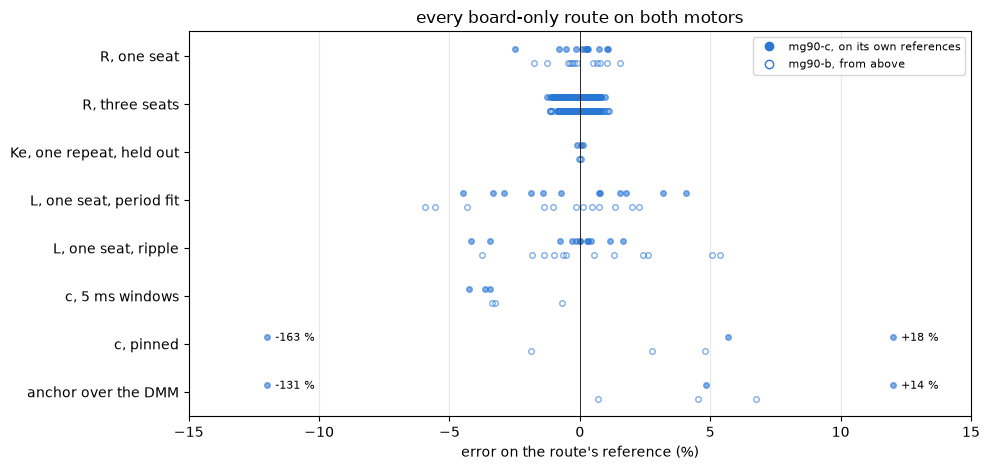

In [83]:
# every % route on both motors, one dot per seat combination or pass
FIG_C = [("R, one seat", SEATS_C[1], SEATS[("as read", 1)]),
         ("R, three seats", SEATS_C[3], SEATS[("as read", 3)]),
         ("Ke, one repeat, held out", ke_ho_c, ke_ho),
         ("L, one seat, period fit", SEAT_L_C["l_mh"][1], l_seat_err),
         ("L, one seat, ripple", SEAT_L_C["l_ripple_mh"][1], lr_b),
         ("c, 5 ms windows", cw_c, cw * 100), ("c, pinned", cp_c, cp * 100),
         ("anchor over the DMM", dmm_c, dmm * 100)]
EDGE = 12.0                                    # %, the axis' half width
blue = figures.BLUE
fig, ax = plt.subplots(figsize=(10, 4.8))
for j, (name, v_c, v_b) in enumerate(FIG_C):
    for v, y, mfc in ((v_c, j - 0.15, blue), (v_b, j + 0.15, "none")):
        v = np.asarray(v, float)
        ax.plot(np.clip(v, -EDGE, EDGE), np.full(len(v), y), "o", ms=4,
                color=blue, mfc=mfc, alpha=0.6)
        for x in v[np.abs(v) > EDGE]:          # off the axis, at its edge
            ax.annotate(f"{x:+.0f} %", (np.sign(x) * EDGE, y), fontsize=8,
                        xytext=(6, -3), textcoords="offset points")
ax.plot([], [], "o", color=blue, label="mg90-c, on its own references")
ax.plot([], [], "o", color=blue, mfc="none", label="mg90-b, from above")
ax.axvline(0, color=figures.INK, lw=0.6)
ax.set_xlim(-EDGE - 3, EDGE + 3)
ax.set_yticks(range(len(FIG_C)), [row[0] for row in FIG_C])
ax.invert_yaxis()
ax.legend(fontsize=8, loc="upper right")
figures.label(ax, x="error on the route's reference (%)",
              title="every board-only route on both motors", grid=False)
ax.grid(alpha=figures.GRID_ALPHA, axis="x")
figures.finish(fig)

Filled dots are mg90-c, each on its own reference, and hollow dots mg90-b from the cells above. A dot past 12 % sits at the edge with its value beside it. The thing to see is that the locked routes and $K_e$ land on mg90-b's spread, and that $c$ by the pinned read and the anchor over the DMM do not.

- $R$ from one seat lands within 0.92 % sd of the 12-hole mean against 0.91 % on mg90-b, two seats within 0.62 against 0.61 % and three within 0.48 % on both. The worst seat is hole 1 at -2.47 %, the hole whose 3.7 V lap rest-resistance found off its line. The laps' own scatter is 0.24 % on both motors.
- $L$ from one seat, four bursts at 25 % forward, lands within 2.67 % sd in the period fit and 1.71 % in ripple $L$, against 2.84 and 2.77 %.
- $K_e$ from one repeat's 20 coasts reads -0.025, -0.076 and -0.177 % on bemf-coast's $K_e$, and +0.10, +0.02 and -0.13 % held out on the other two repeats at the same rungs, against $\pm$0.05 % on mg90-b. The 3.7 V coasts in the reference read +0.23 % on it. The coasts fall 0.28 % per 100 rev/s against 0.22.
- $c$ by the 5 ms windows reads 0.918 to 1.009 x $J/(K_t K_e)$ per cut, 0.962 over the six with an sd of 3.2 %, and 0.958, 0.964 and 0.966 from one run-up each way. The pinned read gives 0.984 to 1.279 on five cuts and -2.237 on the sixth, k 1 in direction -1, whose pinned coast drag reads -46.7 mA against 84.5 to 104.9 mA on the other five. That one cut takes pass 1's pinned $c$ to -0.626.
- $\Delta$ by the anchor takes the pinned read under 300 rev/s, so pass 1 reads 14.4 to 21.5 mA/V at 15 to 40 %, +68.5 mA on the grid in the mean and -0.309 of the DMM. Passes 0 and 2 read -7.0 and -2.1 mA on the grid and 1.144 and 1.048 of the DMM, against mg90-b's -2.3 to +0.6 mA and 1.007 to 1.068. On this motor the window read carried the anchor's $c$ and the pinned read did not.
- $V_b$ loses two spins to the ripple tach's gate, 7.4 V 60 % in direction +1 of repeats 1 and 2, whose two seeds differ by 0.517 % against the 0.3 % limit. The minimal subset then holds 6, 5 and 5 spins. On what remains $k_d$ reads 0.443 $\pm$ 0.041 mV per dropout/s on the full data against 0.524 $\pm$ 0.026, and 0.54 (0.28 to 0.58) from the minimal rungs against 0.51. The low rungs split by rail, -1.5 mV at 5 V against -29.4 mV at 7.4 V, so the floor is zero, as on mg90-b. The minimal tables sit 64 mV (mech +1) and 18 mV (mech -1) rms from the full-data table over 200 to 500 rev/s, against 21 and 17 mV. Mech +1 is the direction whose top rung the gate took out of two of the three repeats.
- The board NTC sat at 24.2 to 25.1 C through the ladder and at 21.6 to 22.9 C through the stall pass half a day later, so on $T_\mathrm{ref}$ = 22.72 C it moves $R$ by -0.61 to +0.93 % over the spinning captures, against -0.60 to +0.26 % on mg90-b.
- The reference rung, 5 V 15 % at 69 rev/s, scatters 6.1 % a spin over 200 ms and 6.4 % over 50 ms, against 1.60 and 1.42 % on mg90-b, so a check of 0.5 % would take about 300 spins on this ladder.
- The pass's 20 short spins cost 483 revs, none over 56, against 485 and 58, and the 300 ms run-up 155 to 160 revs and 168 with 15 ms of coast, against 157 of travel.

The result file carries mg90-b's keys as these passes produce them, pass 1 included, and two more that name the findings, `pinned_c_negative_cuts` and `tach_gate_dropped_spins`. Its notes name what is left out, the angle part of $R$, the meter's ohms, the hold-length refit, the self-heat bounds and the random draws of coasts.

In [84]:
# mg90-c's keys as the passes produce them, each defined as mg90-b's above
I_LAP_C = (GRADED_C["i_start"].min(), GRADED_C["i_start"].max())
J_LAP_C = (GRADED_C["joules"].min(), GRADED_C["joules"].max())
R_COST_C = cost(2, R_SEAT_S, 0.0,
                amps=results.q(np.mean(I_LAP_C), *I_LAP_C, "A"),
                joules_per_lap=results.q(np.mean(J_LAP_C), *J_LAP_C, "J"))
SEAT_KEYS_C = {}
for k in SEAT_COUNTS:
    picks = itertools.combinations(range(len(seat_r_c)), k)
    ohm = np.array([np.mean(seat_r_c[list(pick)]) for pick in picks])
    e = SEATS_C[k]
    SEAT_KEYS_C[k] = route(
        results.median_range(ohm, "ohm"),
        reference=results.q(R_MEAN_C, unit="ohm"),
        error_pct=results.q(e.std(), e.min(), e.max(), "%"),
        error_95th_pct=results.q(np.percentile(np.abs(e), 95), unit="%"),
        spread_pct=results.q(RRN_C["REPEAT_PCT"], unit="%"),
        cost=dict(R_COST_C, maneuvers=results.q(2 * k, unit="count"),
                  seconds=results.q(R_SEAT_S * k, unit="s")))
ke_c = REP_C["ke_mv"].to_numpy() * 1e-3
f50_c = pd.DataFrame(F50_C)                       # duty x pass
pub_c = np.interp(f50_c.index.to_numpy(float), *FT_PUB_C)

In [85]:
# the V_b key: the minimal tables by knot, k_d and the full-data reference
VB_TAB_C, VB_REF_C, ONE_SD_C = {}, {}, {}
for m in (1, -1):
    t = np.array([VB_MIN_C[r][m]["table"] for r in REPEATS])
    VB_TAB_C[f"{m:+d}"] = {knot(k): results.median_range(t[:, i], "mV")
                           for i, k in enumerate(idn.VB_KNOTS)}
    VB_REF_C[f"{m:+d}"] = {knot(k): results.q(v, unit="mV") for k, v in
                           zip(idn.VB_KNOTS, VB_FULL_C[m]["table"])}
    sd = np.array([ONE_C[r][m]["table"] for r in REPEATS]).std(axis=0,
                                                              ddof=1)
    ONE_SD_C[f"{m:+d}"] = {knot(k): results.q(v, unit="mV")
                           for k, v in zip(idn.VB_KNOTS, sd)}
V_B_KEY_C = {
    "rungs": [f"{v:g} V {d} %" for v, d in ic.MIN_RUNGS], "table": VB_TAB_C,
    "reference": VB_REF_C,
    "k_d_mv_per_dropout_s": route(
        results.median_range(KD_C, "mV s"),
        reference=results.pm(VB_FULL_C["k_d"], VB_FULL_C["k_d_se"],
                             "mV s")),
    "floor_mv": results.q(VB_FULL_C["floor"], unit="mV"),
    "floor_by_rail_mv": {f"{lv:g} V": results.pm(x, s, "mV") for lv, (x, s)
                         in VB_FULL_C["floor_by_rail"].items()},
    "dropout_threshold": results.q(SEP_C["threshold"], unit=""),
    "dropout_ambiguous_share": results.q(SEP_C["ambiguous_share"], unit=""),
    "error_rms_200_500_mv": {f"{m:+d}": results.q(RMS_VB_C[m], unit="mV")
                             for m in (1, -1)},
    "single_repeat_sd_mv": ONE_SD_C,
    "cost": cost(VB_COST_C["spins"], VB_COST_C["seconds"], VB_COST_C["revs"],
                 VB_COST_C["largest"])}

In [86]:
# the Ke, R(T), reference-rung and Delta keys, as mg90-b's above
KE_KEY_C = route(
    results.median_range(ke_c, "V s/rad"),
    reference=ic.BEMF["ke_v_s_per_rad"],
    error_pct=results.q(idn.rms(ke_ho_c), ke_ho_c.min(), ke_ho_c.max(), "%"),
    spread_per_coast_pct=results.q(K1_C["ke"].std() / ic.KE * 100,
                                   unit="%"),
    speed_trend_pct_per_100_rev_s=results.q(KE_LINE_C[0] * 100, unit="%"),
    cost=cost(KE_COST_C["spins"], KE_COST_C["seconds"], KE_COST_C["revs"],
              KE_COST_C["largest"]))
board_c_c = GRADED_C["board_c"]
NTC_KEY_C = route(
    results.median_range(MOVE_C, "%"),
    t_ref_c=results.q(T_REF_C, board_c_c.min(), board_c_c.max(), "C"),
    board_span_all_tel_c=results.q(SPAN_C, unit="C"), cost=cost(0, 0, 0))
REF_KEY_C = dict(
    spin_sd_pct={f"{p} ms": results.q(REF_C[p]["sd_pct"], unit="%")
                 for p in REF_C},
    spins_per_check={f"{p} ms": results.q(REF_C[p]["spins"], unit="count")
                     for p in REF_C},
    trend_pct_per_min=results.pm(REF_C[BENCH_MS]["trend"],
                                 REF_C[BENCH_MS]["trend_se"], "%/min"),
    ntc_predicts_pct=results.q(REF_C[BENCH_MS]["ntc_pct"], unit="%"),
    rev_s=results.q(REF_C[BENCH_MS]["rev_s"], unit="rev/s"))
DELTA_KEY_C = {f"{d} %": route(results.median_range(f50_c.loc[d], "mA/V"),
                               reference=results.q(pub_c[i], unit="mA/V"))
               for i, d in enumerate(f50_c.index)}
DELTA_KEY_C.update(
    error_ma=results.median_range(d50_c, "mA"),
    anchor_over_dmm=results.median_range([DD_C[k] for k in CR_C], ""),
    cost=cost(PASS_MANEUVERS, PASS_COST_C["seconds"] + RUNUP_S,
              PASS_COST_C["revs"] + 2 * RUNUP_C["revs"], RUNUP_C["largest"]))
C_KEY_C = dict(win=c_key(CR_C, "win", C_REF_C, cw_c),
               pin=c_key(CR_C, "pin", C_REF_C, cp_c),
               cost=cost(RUNUPS, RUNUP_S, 2 * RUNUP_C["revs"],
                         RUNUP_C["largest"]))

In [87]:
# mg90-c's result file: mg90-b's keys and the two that name the findings
OMITTED_C = (
    "error_angle_part_pct (rest-resistance runs no one-body split on mg90-c), "
    "error_vs_dmm_pct and hold_200ms_bias_pct (no ohms route; the hold-length "
    "refit is not run here), self_heat_bound_pct and self_heat_bound_runup_pct "
    "(no one-body map), ke_v_s_per_rad's four_coasts_rms_pct (the random "
    "draws are not run here)")
NOTES_C = (
    "mg90-c, the second motor, through second_motor_ident.py, "
    "identification.py executed again on motor-model's second_motor.py "
    "copies, every constant from mg90-c's own result files; every key "
    "defined as in mg90-b.json's notes. The pass reads capture-1's 5.0 and "
    "7.4 V rungs (state A); its 3.7 V rungs are in bemf-coast's Ke reference "
    "but in no pass, and Ke is held out on the other two repeats at the same "
    "rungs. The ripple tach's gate drops the spins in tach_gate_dropped_spins "
    "(k, 7.4 V 60 % direction +1, seed difference 0.517 % over the 0.3 % "
    "limit) from Delta and V_b. pinned_c_negative_cuts lists the "
    "speed-torque cuts whose pinned read gives a negative c; the pass "
    "holding one is kept as it comes out, in c_a_s_per_v.pin and "
    "delta_f_ma_per_v. The meter runs are state C. r_board_ntc_move_pct's "
    "T_ref is mg90-c's stall pass, in sitting 2. Left out against mg90-b's "
    "file: " + OMITTED_C)
path_c = results.write(
    "2-motor", "identification", ic.PAIR, pair=ic.MOTOR.key, notes=NOTES_C,
    servo_travel_motor_revs=results.q(idn.TRAVEL_REVS, unit="rev"),
    r_one_seat_ohm=SEAT_KEYS_C[1], r_two_seats_ohm=SEAT_KEYS_C[2],
    r_three_seats_ohm=SEAT_KEYS_C[3], r_board_ntc_move_pct=NTC_KEY_C,
    r_reference_rung=REF_KEY_C, ke_v_s_per_rad=KE_KEY_C,
    l_mh=l_key(SEAT_L_C["l_mh"], ic.IND["l_mh"]),
    l_ripple_mh=l_key(SEAT_L_C["l_ripple_mh"], ic.IND["l_ripple_mh"]),
    c_a_s_per_v=C_KEY_C, delta_f_ma_per_v=DELTA_KEY_C, v_b_mv=V_B_KEY_C,
    pinned_c_negative_cuts=PIN_NEG_C, tach_gate_dropped_spins=DROPPED_C)
print("wrote", path_c, "| left out:", OMITTED_C)

wrote stages/2-motor/identification/results/mg90-c.json | left out: error_angle_part_pct (rest-resistance runs no one-body split on mg90-c), error_vs_dmm_pct and hold_200ms_bias_pct (no ohms route; the hold-length refit is not run here), self_heat_bound_pct and self_heat_bound_runup_pct (no one-body map), ke_v_s_per_rad's four_coasts_rms_pct (the random draws are not run here)


### What the second motor says

The board-only identification carries to mg90-c on the locked routes and the coasts. $R$ from one seat lands within 0.92 % sd of mg90-c's angle average against 0.91 % on mg90-b, $L$ from one seat within 2.7 % against 2.8 %, and $K_e$ from one repeat within 0.13 % held out against 0.05 %. The lap reduction and the burst fits reproduce mg90-c's result files hole by hole, and the run-up count its 5686 crossings. $k_d$ reads 0.44 $\pm$ 0.04 mV per dropout/s on the full data against 0.52 $\pm$ 0.03, and 0.54 from the minimal rungs against 0.51, with the gated spins out.

Two parts of the method do not carry as written. The pinned read of the coast's deceleration is fragile. One cut in six on this motor inverts it, and that one cut takes a whole pass of $c$ and $\Delta$ down, while the window read of the same six cuts sits at 0.92 to 1.01 of the reference. The next stage's identification requirements can meet that with a physical gate on $c$, positive and within the window read's spread, or with the window read itself. And the ripple tach's gate excludes real spins at 7.4 V 60 % on this motor, two of six, so a gated spin has to be an expected case of a pass and not an assertion. With them out, the minimal $V_b$ table in direction +1 reads 64 mV rms from the full-data one, three times mg90-b's.

So the method's constants come out the same on a second motor where every maneuver reads cleanly. Where one cut or one spin fails, these passes have no answer for it, and one motor's data were not enough to show that. The reference rung's 6 % scatter a spin, four times mg90-b's, is open.

## Limitations

- Two motors of one clone. Every route is graded on mg90-b, and the second-motor section grades the same passes on mg90-c against its own files; the spreads are these two motors'.
- Every locked read is the bar on the bare pinion. An end stop through a gear train, with its backlash, its give and its current limit, is not in these data.
- The locked $R$ route drew 0.72 to 0.85 A at 100 %, over the 0.5 A a metal-gear servo's end stop should hold. The only PWM locked read here does not track it by hole.
- The anchor's 300 ms run-up uses 157.4 to 163.3 revs with 15 ms of coast, at or over the 157 available. A 250 ms run-up fits but is untested for $c$.
- The bench's 1.5 s spins do not fit in travel at 7 of 10 rungs. Every short spin here is a window cut out of a long spin, and nothing tests a spin that has run only about 115 ms, for $V_b$, for $\Delta$ or for $K_e$.
- The board NTC reads the board and the room. The winding's own rise is bounded from rest-resistance's thermal model, not measured, and no capture reads the winding's temperature.
- $V_b$'s drift between sittings is seen over two sittings a day apart, with a lead replaced between them.
- The dropout threshold's gap is partial on this motor: 35 % of the rows under 0.40 of the window mean sit within 0.10 to 0.40 of it. The dropout rate climbs to about 960 a second on the 100 % run-ups, twice the highest free spin, so $k_d$ is read over 0 to 480 a second and extrapolated past it.
- Under 330 rev/s, only capture-1 is meter-free, held out by repeat within one sitting.
- No spinning capture runs on the 3.7 V rail.
- The braked stop's distance is not in the data, so every cost stops at 15 ms of coast.
- Three passes are few for anything set by one run-up, so $c$ and $\Delta$ are known to their spread over three, not to a confidence interval.

## Open questions

- Why one seat reads $R$ up to 1.78 % from the angle average. rest-resistance's heat carried between holes and the commutator's angle both fit, low to moderate either way, since the pass read the holes once and in order. Seats read in a shuffled order with the first seat read again at the end separate them. Heat predicts the repeat of the first seat to read high after the others, the angle predicts it to read the same.
- Why $R$ moves 3 to 6 % between sittings and routes, 4.455 ohm at the stall, 4.182 at the run-up's start, 4.316 running under 160 rev/s and 4.196 to 4.445 at hole 11 over three burst sittings. Copper would need 15 C for the largest, and the board saw no such step where it was recorded. A contact film that wears in predicts a fall with use, a route that reads $R$ at another current predicts a split that repeats sitting to sitting. A locked read at the start and end of each sitting, with reference-rung checks between, says whether $R$ itself moves within a sitting and between two.
- Why the anchor reads 4.5 and 6.8 % over the DMM in two passes and 0.7 % in the third. The pass-to-pass spread of $c$ by the pinned read covers it at about one sigma, and a bias of the pinned read would show in every pass. More run-ups per pass, and cuts at several run-up lengths, separate the read's bias from $c$'s scatter.
- What the rail term in $X$ is, about 20 to 25 mV lower at 7.4 V than at 5 V at the same speed, from 65 to 335 rev/s. The same rungs at 3.7 V would say whether it is linear in the rail, and a meter in series at 7.4 V 15 % reads the grid's share of it directly.
- Whether $c$ holds on a run-up shorter than 300 ms, and whether $V_b$ and $\Delta$ read the same from a short spin. The capture below records both.

### What the next motor's capture must record

So that every route of this notebook runs on the next motor and the gaps above close.

1. **Lead orientation.** Which lead color sits on MOT_A, in the capture's metadata for every block. One swapped block, leads reversed, one repeat at 7.4 V 40 and 60 %, confirms the mechanical mapping.
2. **Locked seats.** At least 4 seats in shuffled order, with seat 1 read again at the end, so heat and angle separate. At each seat:
   - 100 % laps of 200 ms at 3.7 and 4.2 V, direction +1 then -1, 20 s apart.
   - a PWM hold at the servo's own 7.4 V rail at 25 to 35 % duty, 200 ms, both directions, the end-stop read a servo can make.
   - 5 bursts at 25 % forward and 5 at 40 % forward after a 20 s rest, the first of each group thrown out.
   - The seat survey is its own block, before the spin blocks, and the bar moves only there. A seat's four 200 ms laps put 1.9 to 2.5 J into the copper and hold 3 to 5 C, so rest at least 2 minutes between seats and 5 minutes before the first spin block. rest-resistance's heat part spans -1.08 to +1.06 % over its pass.
3. **R tracking, the copper as its own thermometer.**
   - **The bar at start and end only.** A locked $R$ read at the sitting's start and end only, at the same hole, with the bar left on through both. Each read is 200 ms at 0.5 A, both directions. The end read comes after its cool-down, below.
   - **Reference-rung checks.** After every spin block, repeat 5 V 15 % (65 rev/s, where $V_b$ is near zero) and read the running $R$ at the cut. One spin scatters 1.42 to 1.60 %, so a 0.5 % change between two checks needs 17 to 21 spins per check, half each way. Twenty spins cost about 70 revs, 0.08 J and 0.15 C held.
   - **Block sizing.** A block is at most one repeat's 20 short spins, or 6 spins at the top rung, with at least 5 s between spins and the top rungs not last. That keeps the winding under about 1 C a block. Wait at least 10 s after a block's last spin before its check.
   - **Run-ups last.** The anchor run-ups come last, at most 3 in a block. After the last, cool down at least 3 minutes before the end locked read. Six run-ups hold 0.79 C, which falls under 0.2 C after about 133 s.
   - **Timestamps** for every spin, read and rest, so $R$ per spin interpolates in time between the checks, with each spin's $R\,i^2$ joules logged beside it.
   - **Thermometers.** An untaped air thermocouple near the motor, and the board NTC in every TEL row. No thermocouple taped to the can, since stage 0's pad test reads a taped tip at least 13 % of its excess low and the can lags the winding.
4. **Coast rungs.** 15, 20, 30, 40 and 60 % at 5.0 and 7.4 V, both directions, 3 repeats, as servo-length short spins. Each is the drive to steady speed (at least 100 ms), a 50 ms window, the cut, and at least 20 ms of coast before any brake. At 7.4 V 30, 40 and 60 %, also one repeat of the bench's 1.5 s spin, to test the short spin's settle for $V_b$ and $\Delta$.
5. **Anchor run-ups.** 100 % at 5.0 V, 3 per direction, cut at 150, 200, 250 and 300 ms, 12 run-ups, each with at least 20 ms of free coast, to test $c$ against the run-up's length within a servo's travel.
6. **Rails.** 7.4 and 5.0 V as above, plus one repeat of the coast rungs at 3.7 V.
7. **Repeats across sittings.** Two sittings at least a day apart, each opening and closing with the same reference block, the 7.4 V 30/40/60 % short spins both ways and one locked $R$ read, for $V_b$'s and $R$'s drift between sittings and within one.
8. **Meter references, for grading only, in a block of their own.** The DMM in series at 5 V 30 % and 7.4 V 20 and 40 % for $\Delta$, and the DMM's ohms at each locked seat at room after a 10 minute rest.
9. **Meter-free low speed.** One extra meter-free repeat of 5 V 15 and 20 % in the second sitting, as held-out low-speed data with no meter.

## Conclusion

The board alone recovers every constant the back-EMF speed estimate needs, each from a maneuver a servo can make, and each lands near its bench reference. $K_e$ from one repeat's 20 coasts lands within 0.05 % held out, provided the coasts span the speed range, since $K_e$ falls 0.22 % per 100 rev/s. $R$ from one locked seat lands within 0.91 % sd of the angle average, 0.61 % from two seats and 0.48 % from three, and a 200 ms hold is enough. $L$ from one seat lands within 2.8 % sd. $V_b$ splits into $k_d$ times the dropout rate, 0.52 mV per dropout/s, which carries the direction split and the rise past 300 rev/s, and a speed table under 80 mV; three rungs, 7.4 V at 30, 40 and 60 % both ways, recover $k_d$ to 0.51 (0.42 to 0.80) and the tables within 21 and 17 mV of the full-data ones. $c$ and $\Delta$ by the 100 % anchor carry the most spread, $c$ 1.5 to 3.4 % and $\Delta$ 2.9 mA from one pass to the next, so one run-up each way is too few for $\Delta$ to 1 mA.

The board NTC moves $R$ by only -0.60 to +0.26 % across these sittings, because the bare motor sat near room temperature, and the winding's own rise above it is bounded under 0.4 %. These data cannot say whether $R$'s 3 to 6 % moves between sittings are temperature, route or contact. A repeated low-speed reference rung tracks $R$ within a sitting to about 1.5 % a spin, so a check of 17 to 21 spins reads a 0.5 % change.

Three things a servo cannot do as these data were captured. The locked route drew up to 0.85 A, over a metal-gear servo's end-stop hold. The 300 ms anchor run-up uses all or more of a servo's 157 revs. And the bench's 1.5 s spins do not fit in travel. A short spin fits, and a 250 ms run-up fits, but neither is tested. The next motor's capture above records both, and the compensation notebook takes these constants into the speed estimate.